In [1]:
# Podešavanje okruženja

import sys
import platform
import importlib.util

print("Python verzija:", sys.version)
print("Platforma:", platform.platform())

required_packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "sklearn",
    "requests",
]

for package in required_packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'instaliran' if installed else 'nije instaliran'}")

Python verzija: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platforma: Linux-6.6.122+-x86_64-with-glibc2.39
pandas: instaliran
numpy: instaliran
matplotlib: instaliran
seaborn: instaliran
sklearn: instaliran
requests: instaliran


In [2]:
# Preuzimanje Transfermarkt baze i pregled strukture

%pip -q install duckdb

from pathlib import Path
import duckdb
import requests

url = (
    "https://pub-e682421888d945d684bcae8890b0ec20.r2.dev/"
    "data/transfermarkt-datasets.duckdb"
)

db_path = Path("/content/transfermarkt-datasets.duckdb")

if not db_path.exists():
    print("Preuzimanje baze počinje...")

    response = requests.get(url, stream=True, timeout=60)
    response.raise_for_status()

    total_bytes = 0
    with open(db_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)
                total_bytes += len(chunk)

    print(f"Preuzimanje završeno: {total_bytes / 1e6:.1f} MB")
else:
    print("Baza je već preuzeta.")

con = duckdb.connect(str(db_path), read_only=True)

tables = con.execute("SHOW TABLES").df()

print("\nDostupne tabele:")
display(tables)

Baza je već preuzeta.

Dostupne tabele:


,name
0,appearances
1,club_games
2,clubs
3,competitions
4,countries
5,game_events
6,game_lineups
7,games
8,national_teams
9,player_valuations


In [3]:
# Struktura i broj redova u svakoj tabeli

table_names = con.execute("SHOW TABLES").df()["name"].tolist()

table_summary = []

for table in table_names:
    row_count = con.execute(
        f'SELECT COUNT(*) FROM "{table}"'
    ).fetchone()[0]

    columns = con.execute(
        f'DESCRIBE "{table}"'
    ).df()["column_name"].tolist()

    table_summary.append({
        "table": table,
        "rows": row_count,
        "number_of_columns": len(columns),
        "columns": ", ".join(columns)
    })

summary_df = (
    __import__("pandas")
    .DataFrame(table_summary)
    .sort_values("rows", ascending=False)
    .reset_index(drop=True)
)

display(summary_df)

,table,rows,number_of_columns,columns
0,game_lineups,3179016,10,"game_lineups_id, date, game_id, player_id, clu..."
1,appearances,1894350,13,"appearance_id, game_id, player_id, player_club..."
2,game_events,1274469,11,"game_event_id, date, game_id, minute, type, cl..."
3,player_valuations,656301,6,"player_id, date, market_value_in_eur, current_..."
4,club_games,177916,11,"game_id, club_id, own_goals, own_position, own..."
5,transfers,175165,10,"player_id, transfer_date, transfer_season, fro..."
6,games,88958,23,"game_id, competition_id, season, round, date, ..."
7,players,50149,26,"player_id, first_name, last_name, name, last_s..."
8,clubs,796,17,"club_id, club_code, name, domestic_competition..."
9,national_teams,124,17,"national_team_id, name, team_code, country_id,..."


In [4]:
# Detaljan audit ključnih tabela

import pandas as pd

key_tables = [
    "players",
    "player_valuations",
    "appearances",
    "transfers",
    "clubs",
    "competitions",
]

for table in key_tables:
    print("\n" + "=" * 90)
    print(f"TABELA: {table}")

    # Struktura i tipovi podataka
    schema = con.execute(
        f'DESCRIBE "{table}"'
    ).df()

    display(schema)

    # Pet primera redova
    print(f"Primeri redova — {table}:")
    display(con.execute(
        f'SELECT * FROM "{table}" LIMIT 5'
    ).df())

    # Broj nedostajućih vrednosti po kolonama
    columns = schema["column_name"].tolist()

    expressions = [
        f'COUNT(*) FILTER (WHERE "{col}" IS NULL) AS "{col}"'
        for col in columns
    ]

    null_counts = con.execute(
        f'SELECT {", ".join(expressions)} FROM "{table}"'
    ).df().T.reset_index()

    null_counts.columns = ["column", "missing_count"]
    null_counts["missing_pct"] = (
        100 * null_counts["missing_count"] /
        con.execute(f'SELECT COUNT(*) FROM "{table}"').fetchone()[0]
    ).round(2)

    print(f"Nedostajuće vrednosti — {table}:")
    display(
        null_counts.sort_values(
            "missing_pct", ascending=False
        ).reset_index(drop=True)
    )


TABELA: players


,column_name,column_type,null,key,default,extra
0,player_id,INTEGER,YES,None,None,None
1,first_name,VARCHAR,YES,None,None,None
2,last_name,VARCHAR,YES,None,None,None
3,name,VARCHAR,YES,None,None,None
4,last_season,VARCHAR,YES,None,None,None
5,current_club_id,VARCHAR,YES,None,None,None
6,player_code,VARCHAR,YES,None,None,None
7,country_of_birth,VARCHAR,YES,None,None,None
8,city_of_birth,VARCHAR,YES,None,None,None
9,country_of_citizenship,VARCHAR,YES,None,None,None


Primeri redova — players:


,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,agent_name,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur,highest_market_value_in_eur
0,10,Miroslav,Klose,Miroslav Klose,2015,398,miroslav-klose,Poland,Opole,Germany,...,ASBW Sport Marketing,https://img.a.transfermarkt.technology/portrai...,<NA>,<NA>,None,https://www.transfermarkt.co.uk/miroslav-klose...,IT1,Società Sportiva Lazio S.p.A.,1000000,30000000
1,26,Roman,Weidenfeller,Roman Weidenfeller,2017,16,roman-weidenfeller,Germany,Diez,Germany,...,Neubauer 13 GmbH,https://img.a.transfermarkt.technology/portrai...,<NA>,<NA>,None,https://www.transfermarkt.co.uk/roman-weidenfe...,L1,Borussia Dortmund,750000,8000000
2,65,Dimitar,Berbatov,Dimitar Berbatov,2015,1091,dimitar-berbatov,Bulgaria,Blagoevgrad,Bulgaria,...,CSKA-AS-23 Ltd.,https://img.a.transfermarkt.technology/portrai...,<NA>,<NA>,None,https://www.transfermarkt.co.uk/dimitar-berbat...,GR1,Panthessalonikios Athlitikos Omilos Konstantin...,1000000,34500000
3,77,None,Lúcio,Lúcio,2012,506,lucio,Brazil,Brasília,Brazil,...,None,https://img.a.transfermarkt.technology/portrai...,<NA>,<NA>,None,https://www.transfermarkt.co.uk/lucio/profil/s...,IT1,Juventus FC,200000,24500000
4,80,Tom,Starke,Tom Starke,2017,27,tom-starke,East Germany (GDR),Freital,Germany,...,IFM,https://img.a.transfermarkt.technology/portrai...,<NA>,<NA>,None,https://www.transfermarkt.co.uk/tom-starke/pro...,L1,Bayern Munich,100000,3000000


Nedostajuće vrednosti — players:


...

,column_name,column_type,null,key,default,extra
0,competition_id,VARCHAR,YES,None,None,None
1,competition_code,VARCHAR,YES,None,None,None
2,name,VARCHAR,YES,None,None,None
3,sub_type,VARCHAR,YES,None,None,None
4,type,VARCHAR,YES,None,None,None
5,country_id,INTEGER,YES,None,None,None
6,country_name,VARCHAR,YES,None,None,None
7,domestic_league_code,VARCHAR,YES,None,None,None
8,confederation,VARCHAR,YES,None,None,None
9,total_clubs,INTEGER,YES,None,None,None


Primeri redova — competitions:


,competition_id,competition_code,name,sub_type,type,country_id,country_name,domestic_league_code,confederation,total_clubs,url
0,A1,bundesliga,bundesliga,first_tier,domestic_league,127,Austria,A1,europa,12,https://www.transfermarkt.co.uk/bundesliga/sta...
1,AFAC,afc-asian-cup,afc-asian-cup,afc_asian_cup,national_team_competition,-1,None,None,asien,<NA>,https://www.transfermarkt.co.uk/afc-asian-cup/...
2,AFCN,africa-cup-of-nations,africa-cup-of-nations,africa_cup_of_nations,national_team_competition,-1,None,None,afrika,<NA>,https://www.transfermarkt.co.uk/africa-cup-of-...
3,ARG1,torneo-apertura,torneo-apertura,first_tier,domestic_league,9,Argentina,ARG1,amerika,30,https://www.transfermarkt.co.uk/torneo-apertur...
4,AUS1,a-league-men,a-league-men,first_tier,domestic_league,12,Australia,AUS1,asien,12,https://www.transfermarkt.co.uk/a-league-men/s...


Nedostajuće vrednosti — competitions:


,column,missing_count,missing_pct
0,total_clubs,15,23.08
1,country_name,12,18.46
2,domestic_league_code,12,18.46
3,name,0,0.00
4,competition_code,0,0.00
5,competition_id,0,0.00
6,sub_type,0,0.00
7,country_id,0,0.00
8,type,0,0.00
9,confederation,0,0.00


In [5]:
# Vremenski raspon, duplikati i integritet podataka

import pandas as pd

# Vremenski raspon svih tabela sa relevantnim datumima
date_checks = {
    "players": ["date_of_birth", "contract_expiration_date"],
    "player_valuations": ["date"],
    "appearances": ["date"],
    "transfers": ["transfer_date"],
    "games": ["date"],
    "game_events": ["date"],
    "game_lineups": ["date"],
}

date_results = []

for table, date_columns in date_checks.items():
    available_columns = set(
        con.execute(f'DESCRIBE "{table}"')
        .df()["column_name"]
    )

    for col in date_columns:
        if col not in available_columns:
            continue

        result = con.execute(f"""
            SELECT
                MIN("{col}") AS min_date,
                MAX("{col}") AS max_date,
                COUNT(*) FILTER (
                    WHERE "{col}" IS NULL
                ) AS missing_dates,
                COUNT(*) AS total_rows
            FROM "{table}"
        """).df()

        date_results.append({
            "table": table,
            "column": col,
            "min_date": result.loc[0, "min_date"],
            "max_date": result.loc[0, "max_date"],
            "missing_dates": int(result.loc[0, "missing_dates"]),
            "total_rows": int(result.loc[0, "total_rows"]),
        })

date_df = pd.DataFrame(date_results)
display(date_df)


# Provera duplikata na osnovu kandidata za ključeve.

duplicate_checks = {
    "players": ["player_id"],
    "player_valuations": ["player_id", "date"],
    "appearances": ["appearance_id"],
    "transfers": [
        "player_id", "transfer_date",
        "from_club_id", "to_club_id"
    ],
    "clubs": ["club_id"],
    "competitions": ["competition_id"],
    "games": ["game_id"],
    "game_events": ["game_event_id"],
    "game_lineups": ["game_lineups_id"],
    "club_games": ["game_id", "club_id"],
    "countries": ["country_id"],
    "national_teams": ["national_team_id"],
    "version": ["commit_hash"],
}

duplicate_results = []

for table, key_cols in duplicate_checks.items():
    available = set(
        con.execute(f'DESCRIBE "{table}"')
        .df()["column_name"]
    )

    if not set(key_cols).issubset(available):
        continue

    key_sql = ", ".join(f'"{c}"' for c in key_cols)

    result = con.execute(f"""
        SELECT
            COUNT(*) AS total_rows,
            COUNT(*) - COUNT(DISTINCT ({key_sql}))
                AS duplicate_key_rows
        FROM "{table}"
    """).fetchone()

    duplicate_results.append({
        "table": table,
        "candidate_key": " + ".join(key_cols),
        "total_rows": result[0],
        "duplicate_key_rows": result[1],
    })

display(pd.DataFrame(duplicate_results))


# Transferi sa datumom posle današnjeg datuma.

future_transfers = con.execute("""
    SELECT
        COUNT(*) AS future_transfer_rows,
        MIN(transfer_date) AS first_future_date,
        MAX(transfer_date) AS last_future_date
    FROM transfers
    WHERE transfer_date > CURRENT_DATE
""").df()

print("Transferi sa budućim datumom:")
display(future_transfers)


# Provera osnovnog cilja: tržišne vrednosti
valuation_summary = con.execute("""
    SELECT
        COUNT(*) AS observations,
        COUNT(DISTINCT player_id) AS distinct_players,
        COUNT(DISTINCT date) AS distinct_dates,
        MIN(market_value_in_eur) AS min_value_eur,
        MEDIAN(market_value_in_eur) AS median_value_eur,
        MAX(market_value_in_eur) AS max_value_eur
    FROM player_valuations
""").df()

print("Osnovna statistika tržišnih vrednosti:")
display(valuation_summary)


,table,column,min_date,max_date,missing_dates,total_rows
0,players,date_of_birth,1968-07-31,2011-02-23,49,50149
1,players,contract_expiration_date,2000-05-31,2035-06-30,18569,50149
2,player_valuations,date,2000-01-20,2026-06-12,0,656301
3,appearances,date,2012-07-03,2026-06-28,0,1894350
4,transfers,transfer_date,1993-07-01,2030-06-30,0,175165
5,games,date,2006-06-09,2026-07-06,0,88958
6,game_events,date,2006-06-09,2026-07-06,0,1274469
7,game_lineups,date,2013-07-02,2026-07-06,0,3179016


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,table,candidate_key,total_rows,duplicate_key_rows
0,players,player_id,50149,0
1,player_valuations,player_id + date,656301,0
2,appearances,appearance_id,1894350,0
3,transfers,player_id + transfer_date + from_club_id + to_...,175165,0
4,clubs,club_id,796,0
5,competitions,competition_id,65,0
6,games,game_id,88958,0
7,game_events,game_event_id,1274469,0
8,game_lineups,game_lineups_id,3179016,0
9,club_games,game_id + club_id,177916,0


Transferi sa budućim datumom:


,future_transfer_rows,first_future_date,last_future_date
0,475,2026-11-30,2030-06-30


Osnovna statistika tržišnih vrednosti:


,observations,distinct_players,distinct_dates,min_value_eur,median_value_eur,max_value_eur
0,656301,41528,5749,0,500000.0,200000000


In [6]:
# Raspodela vrednosti, istorija igrača i vremensko preklapanje

import pandas as pd

# Raspodela tržišnih vrednosti
value_distribution = con.execute("""
    SELECT
        COUNT(*) AS total_observations,
        COUNT(*) FILTER (WHERE market_value_in_eur = 0) AS zero_values,
        COUNT(*) FILTER (WHERE market_value_in_eur < 0) AS negative_values,
        COUNT(*) FILTER (WHERE market_value_in_eur > 0) AS positive_values,
        COUNT(*) FILTER (WHERE market_value_in_eur >= 100000000) AS values_100m_plus,
        QUANTILE_CONT(market_value_in_eur, 0.01) AS p01,
        QUANTILE_CONT(market_value_in_eur, 0.25) AS p25,
        MEDIAN(market_value_in_eur) AS median,
        QUANTILE_CONT(market_value_in_eur, 0.75) AS p75,
        QUANTILE_CONT(market_value_in_eur, 0.90) AS p90,
        QUANTILE_CONT(market_value_in_eur, 0.99) AS p99
    FROM player_valuations
""").df()

print("Raspodela vrednosti (iznosi su u evrima):")
display(value_distribution)

# Broj procena po igraču
player_history = con.execute("""
    WITH per_player AS (
        SELECT
            player_id,
            COUNT(*) AS valuation_count,
            MIN(date) AS first_valuation,
            MAX(date) AS last_valuation
        FROM player_valuations
        GROUP BY player_id
    )
    SELECT
        COUNT(*) AS players,
        MEDIAN(valuation_count) AS median_valuations_per_player,
        AVG(valuation_count) AS mean_valuations_per_player,
        COUNT(*) FILTER (WHERE valuation_count = 1) AS players_with_one_valuation,
        COUNT(*) FILTER (WHERE valuation_count >= 5) AS players_with_5plus,
        COUNT(*) FILTER (WHERE valuation_count >= 10) AS players_with_10plus,
        COUNT(*) FILTER (WHERE valuation_count >= 20) AS players_with_20plus
    FROM per_player
""").df()

print("Dužina istorije procena po igraču:")
display(player_history)

# Preklapanje vremenskih perioda procena i nastupa
overlap = con.execute("""
    SELECT
        (SELECT MIN(date) FROM player_valuations) AS valuation_start,
        (SELECT MAX(date) FROM player_valuations) AS valuation_end,
        (SELECT MIN(date) FROM appearances) AS appearance_start,
        (SELECT MAX(date) FROM appearances) AS appearance_end,
        (SELECT COUNT(DISTINCT player_id) FROM player_valuations)
            AS valuation_players,
        (SELECT COUNT(DISTINCT player_id) FROM appearances)
            AS appearance_players,
        (SELECT COUNT(DISTINCT v.player_id)
         FROM player_valuations v
         INNER JOIN appearances a ON a.player_id = v.player_id)
            AS players_in_both_tables
""").df()

print("Vremensko preklapanje i igrači zajednički za obe tabele:")
display(overlap)

# Pregled budućih transfera
future_transfer_details = con.execute("""
    SELECT
        transfer_date,
        player_name,
        from_club_name,
        to_club_name,
        transfer_fee,
        market_value_in_eur,
        transfer_season
    FROM transfers
    WHERE transfer_date > CURRENT_DATE
    ORDER BY transfer_date
    LIMIT 20
""").df()

print("Primeri transfera sa budućim datumima:")
display(future_transfer_details)


Raspodela vrednosti (iznosi su u evrima):


,total_observations,zero_values,negative_values,positive_values,values_100m_plus,p01,p25,median,p75,p90,p99
0,656301,1,0,656300,351,25000.0,200000.0,500000.0,1500000.0,5000000.0,32000000.0


Dužina istorije procena po igraču:


,players,median_valuations_per_player,mean_valuations_per_player,players_with_one_valuation,players_with_5plus,players_with_10plus,players_with_20plus
0,41528,15.0,15.803819,1063,35889,28678,14049


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Vremensko preklapanje i igrači zajednički za obe tabele:


,valuation_start,valuation_end,appearance_start,appearance_end,valuation_players,appearance_players,players_in_both_tables
0,2000-01-20,2026-06-12,2012-07-03,2026-06-28,41528,29531,28328


Primeri transfera sa budućim datumima:


,transfer_date,player_name,from_club_name,to_club_name,transfer_fee,market_value_in_eur,transfer_season
0,2026-11-30,Joshua Yaro,AC Boise,St. Louis CITY,0.0,400000.0,26/27
1,2026-11-30,Mason Stajduhar,LV Lights,Salt Lake,0.0,175000.0,26/27
2,2026-11-30,Abdelrahman Boudah,Västerås SK,Albirex Niigata,0.0,900000.0,26/27
3,2026-11-30,Jordan Farr,Loudoun United,D.C. United,0.0,150000.0,26/27
4,2026-11-30,Jacob Jackson,Monterey Bay,San Diego,0.0,100000.0,26/27
5,2026-11-30,Tucker Lepley,Oakland Roots,LA Galaxy,0.0,200000.0,26/27
6,2026-11-30,Tyler Wolff,Sacramento FC,Salt Lake,0.0,400000.0,26/27
7,2026-11-30,Isaiah LeFlore,TB Rowdies,Nashville,0.0,25000.0,26/27
8,2026-11-30,Stephen McMullan,Waterford FC,Fleetwood,0.0,125000.0,26/27
9,2026-11-30,Kazper Karlsson,Degerfors,AIK,0.0,650000.0,26/27


In [7]:
# Dostupnost prethodnih nastupa na datum procene

import pandas as pd

# Svaka procena dobija broj nastupa pre datuma procene.
# Za sada računam sve prethodne nastupe; vremenske prozore
# od 90/365 dana i sezonske agregate uvodim kasnije.

coverage = con.execute("""
    WITH valuation_coverage AS (
        SELECT
            v.player_id,
            v.date AS valuation_date,
            v.market_value_in_eur,
            COUNT(a.appearance_id) AS prior_appearances,
            SUM(
                CASE
                    WHEN a.appearance_id IS NOT NULL
                    THEN a.minutes_played
                    ELSE 0
                END
            ) AS prior_minutes
        FROM player_valuations v
        LEFT JOIN appearances a
            ON v.player_id = a.player_id
           AND a.date < v.date
        WHERE v.date >= DATE '2013-07-01'
        GROUP BY
            v.player_id,
            v.date,
            v.market_value_in_eur
    )
    SELECT
        COUNT(*) AS valuations_since_2013,
        COUNT(*) FILTER (
            WHERE prior_appearances = 0
        ) AS valuations_without_prior_appearances,
        COUNT(*) FILTER (
            WHERE prior_appearances >= 1
        ) AS valuations_with_1plus,
        COUNT(*) FILTER (
            WHERE prior_appearances >= 5
        ) AS valuations_with_5plus,
        COUNT(*) FILTER (
            WHERE prior_appearances >= 10
        ) AS valuations_with_10plus,
        COUNT(*) FILTER (
            WHERE prior_appearances >= 20
        ) AS valuations_with_20plus,
        MEDIAN(prior_appearances) AS median_prior_appearances,
        MEDIAN(prior_minutes) AS median_prior_minutes,
        COUNT(DISTINCT player_id) AS distinct_players
    FROM valuation_coverage
""").df()

print("Pokrivenost procena prethodnim nastupima:")
display(coverage)

# Godišnji pregled pokrivenosti
yearly_coverage = con.execute("""
    WITH valuation_coverage AS (
        SELECT
            v.player_id,
            v.date AS valuation_date,
            COUNT(a.appearance_id) AS prior_appearances
        FROM player_valuations v
        LEFT JOIN appearances a
            ON v.player_id = a.player_id
           AND a.date < v.date
        WHERE v.date >= DATE '2013-07-01'
        GROUP BY v.player_id, v.date
    )
    SELECT
        YEAR(valuation_date) AS valuation_year,
        COUNT(*) AS total_valuations,
        COUNT(*) FILTER (
            WHERE prior_appearances >= 1
        ) AS with_prior_appearances,
        COUNT(*) FILTER (
            WHERE prior_appearances >= 10
        ) AS with_10plus,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE prior_appearances >= 10
            ) / NULLIF(COUNT(*), 0),
            2
        ) AS pct_with_10plus
    FROM valuation_coverage
    GROUP BY YEAR(valuation_date)
    ORDER BY valuation_year
""").df()

print("Pokrivenost po godinama:")
display(yearly_coverage)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Pokrivenost procena prethodnim nastupima:


,valuations_since_2013,valuations_without_prior_appearances,valuations_with_1plus,valuations_with_5plus,valuations_with_10plus,valuations_with_20plus,median_prior_appearances,median_prior_minutes,distinct_players
0,555102,227448,327654,278978,251822,213211,5.0,197.0,41078


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Pokrivenost po godinama:


,valuation_year,total_valuations,with_prior_appearances,with_10plus,pct_with_10plus
0,2013,7144,3223,2120,29.68
1,2014,23707,14703,11202,47.25
2,2015,30479,18513,14164,46.47
3,2016,34653,21100,16234,46.85
4,2017,35923,22942,17746,49.40
5,2018,41097,26670,20563,50.04
6,2019,46088,27765,20791,45.11
7,2020,48749,30646,23746,48.71
8,2021,58412,35223,26512,45.39
9,2022,59564,34002,25797,43.31


In [8]:
# Dostupnost statistike u prethodnih 365 dana

import pandas as pd

# Za proveru pokrivenosti koristim samo period 2014–2025.

coverage_365 = con.execute("""
    WITH daily_appearances AS (
        SELECT
            player_id,
            date,
            COUNT(*) AS matches,
            SUM(COALESCE(minutes_played, 0)) AS minutes,
            SUM(COALESCE(goals, 0)) AS goals,
            SUM(COALESCE(assists, 0)) AS assists
        FROM appearances
        WHERE date >= DATE '2013-01-01'
          AND date < DATE '2026-01-01'
        GROUP BY player_id, date
    ),
    valuation_features AS (
        SELECT
            v.player_id,
            v.date AS valuation_date,
            v.market_value_in_eur,
            COALESCE(SUM(a.matches), 0) AS matches_365,
            COALESCE(SUM(a.minutes), 0) AS minutes_365,
            COALESCE(SUM(a.goals), 0) AS goals_365,
            COALESCE(SUM(a.assists), 0) AS assists_365
        FROM player_valuations v
        LEFT JOIN daily_appearances a
            ON v.player_id = a.player_id
           AND a.date < v.date
           AND a.date >= v.date - INTERVAL '365 days'
        WHERE v.date >= DATE '2014-01-01'
          AND v.date < DATE '2026-01-01'
        GROUP BY v.player_id, v.date, v.market_value_in_eur
    )
    SELECT
        YEAR(valuation_date) AS year,
        COUNT(*) AS valuations,
        COUNT(*) FILTER (WHERE matches_365 >= 1) AS with_1plus,
        COUNT(*) FILTER (WHERE matches_365 >= 10) AS with_10plus,
        COUNT(*) FILTER (WHERE matches_365 >= 20) AS with_20plus,
        COUNT(*) FILTER (WHERE minutes_365 >= 900) AS with_900plus_minutes,
        ROUND(
            100.0 * COUNT(*) FILTER (WHERE matches_365 >= 10)
            / NULLIF(COUNT(*), 0), 2
        ) AS pct_with_10plus,
        MEDIAN(matches_365) AS median_matches_365,
        MEDIAN(minutes_365) AS median_minutes_365
    FROM valuation_features
    GROUP BY YEAR(valuation_date)
    ORDER BY year
""").df()

print("Pokrivenost prethodnih 365 dana po godinama:")
display(coverage_365)

print("Ukupna pokrivenost za period 2014–2025:")
total = coverage_365[[
    "valuations", "with_1plus", "with_10plus",
    "with_20plus", "with_900plus_minutes"
]].sum()

display(pd.DataFrame([total]))


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Pokrivenost prethodnih 365 dana po godinama:


,year,valuations,with_1plus,with_10plus,with_20plus,with_900plus_minutes,pct_with_10plus,median_matches_365,median_minutes_365
0,2014,23707,13103,9273,6227,7715,39.12,2.0,90.0
1,2015,30479,14090,9999,6599,8408,32.81,0.0,0.0
2,2016,34653,15000,10648,7202,8861,30.73,0.0,0.0
3,2017,35923,15598,11178,7392,9311,31.12,0.0,0.0
4,2018,41097,18367,12984,8660,10936,31.59,0.0,0.0
5,2019,46088,16598,11181,7237,9245,24.26,0.0,0.0
6,2020,48749,18033,12041,7666,9853,24.70,0.0,0.0
7,2021,58412,20877,14559,9852,11575,24.92,0.0,0.0
8,2022,59564,18297,13318,8980,10501,22.36,0.0,0.0
9,2023,57576,19192,13640,9228,10485,23.69,0.0,0.0


Ukupna pokrivenost za period 2014–2025:


,valuations,with_1plus,with_10plus,with_20plus,with_900plus_minutes
0,527106,207984,145415,97228,117453



# Istraživački i eksperimentalni dizajn

## 1. Tema istraživanja

Primena metoda mašinskog učenja za procenu tržišne vrednosti
fudbalera i analizu potencijalno potcenjenih igrača.

## 2. Cilj istraživanja

Razviti i uporediti modele mašinskog učenja za procenu
tržišne vrednosti profesionalnih fudbalera na osnovu
raspoloživih biografskih, kontekstualnih i statističkih
karakteristika.

Dodatni cilj je identifikovanje igrača kod kojih je
modelovana tržišna vrednost viša od evidentirane
Transfermarkt procene i ispitivanje korisnosti takvih
odstupanja za analizu potencijalno potcenjenih igrača.

## 3. Istraživačka pitanja

IP1: Koliko precizno različiti modeli mašinskog učenja
mogu proceniti istorijsku tržišnu vrednost fudbalera?

IP2: Da li uključivanje statistike prethodnih nastupa
poboljšava kvalitet predikcije?

IP3: Koje karakteristike najviše utiču na predikcije
tržišne vrednosti?

IP4: Da li pozitivna odstupanja između modelovane i
evidentirane vrednosti mogu pomoći u identifikovanju
igrača zanimljivih za dalju skauting analizu?

IP5: Da li su pozitivna odstupanja povezana sa kasnijim
rastom tržišne vrednosti? (Dodatna retrospektivna analiza.)

## 4. Jedinica posmatranja

Jedno opažanje predstavlja jednog fudbalera na određeni
datum evidentirane tržišne procene.

Jedinstveni identifikator opažanja:
(player_id, valuation_date)

## 5. Ciljna promenljiva

market_value_in_eur iz tabele player_valuations.

Moguća transformacija ciljne promenljive:
log1p(market_value_in_eur).

Izbor transformacije biće zasnovan na eksperimentima.
Konačne predikcije i greške analiziraće se i u evrima.

## 6. Kandidatski period

2014–2025.

Konačan izbor perioda zavisi od pokrivenosti takmičenja,
dostupnosti istorijskih karakteristika i rezultata
provera kvaliteta podataka.

## 7. Kandidatske karakteristike

- Starost igrača na datum procene
- Pozicija i potpozicija
- Visina i dominantna noga
- Kontekst kluba i takmičenja na datum procene
- Broj nastupa u prethodnih 90 i 365 dana
- Minuti u prethodnih 90 i 365 dana
- Golovi i asistencije u prethodnih 365 dana
- Pokazatelji učinka po 90 minuta, uz kontrolu
  minimalne minutaže

Karakteristike se uključuju samo ako su dostupne
ili opravdano rekonstruisane za datum posmatranja.

## 8. Sprečavanje curenja informacija

Za procenu vrednosti na datum t koriste se isključivo
informacije dostupne pre datuma t, odnosno informacije
za koje je potvrđeno da su bile poznate u trenutku
predikcije.

Ne koriste se trenutna i najviša tržišna vrednost
iz tabele players kao prediktori istorijskih vrednosti.

Posebno se proverava vremenska validnost podataka
o klubovima, ugovorima, reprezentativnim nastupima
i transferima.

## 9. Plan modelovanja

- Jednostavni referentni model
- Regularizovana linearna regresija
- Random Forest
- Gradient boosting model (npr. XGBoost ili CatBoost)

Modeli će se porediti na vremenski odvojenim podacima.

## 10. Kandidatska podela podataka

Trening: 2014–2021.
Validacija: 2022–2023.
Test: 2024–2025.

Podela je preliminarna i biće potvrđena nakon
provere pokrivenosti i vremenske validnosti podataka.

Test skup se ne koristi za izbor karakteristika,
podešavanje hiperparametara ili izbor modela.

## 11. Metrike evaluacije

- MAE u evrima
- RMSE u evrima
- R²
- Dodatna analiza grešaka na logaritamskoj skali
- Greške po pozicijama, ligama i vrednosnim segmentima

## 12. Eksperimentalno poređenje

Eksperiment A:
Model sa biografskim i vremenski validnim
kontekstualnim karakteristikama.

Eksperiment B:
Model sa istim osnovnim karakteristikama i
dodatnom statistikom prethodnih nastupa.

Doprinos statistike nastupa proverava se na
uporedivom test uzorku.

## 13. Analiza potencijalno potcenjenih igrača

Pozitivno odstupanje definisano je kao:

predviđena_vrednost - evidentirana_vrednost > 0

Pored apsolutne razlike u evrima, analiziraju se
relativna odstupanja, karakteristike igrača i
stabilnost predikcija.

Pozitivno odstupanje nije dokaz stvarne tržišne
potcenjenosti niti predikcija transferne naknade.

## 14. Dodatna retrospektivna validacija

Ako podaci dozvole, proverava se da li igrači sa
pozitivnim odstupanjima beleže veći kasniji rast
evidentirane tržišne vrednosti.

Ova analiza koristi samo informacije poznate na
početnom datumu i unapred definisan budući horizont.

## 15. Reproduktivnost

Beleže se:
- Izvor i verzija podataka
- Pravila filtriranja
- Postupci pripreme karakteristika
- Vremenske podele
- Parametri modela
- Metrike i rezultati eksperimenata
- Ograničenja i mogući izvori pristrasnosti


In [9]:

# POKRIVENOST TAKMIČENJA

import pandas as pd

START_DATE = "2014-01-01"
END_DATE = "2026-01-01"

# Provere povezivanja sa tabelom competitions

join_quality = con.execute("""
    SELECT
        'player_valuations' AS source_table,
        COUNT(*) AS total_rows,
        COUNT(*) FILTER (
            WHERE v.player_club_domestic_competition_id IS NULL
        ) AS missing_competition_id,
        COUNT(*) FILTER (
            WHERE v.player_club_domestic_competition_id IS NOT NULL
              AND c.competition_id IS NULL
        ) AS unmatched_competition_id
    FROM player_valuations v
    LEFT JOIN competitions c
        ON v.player_club_domestic_competition_id = c.competition_id
    WHERE v.date >= DATE '2014-01-01'
      AND v.date < DATE '2026-01-01'

    UNION ALL

    SELECT
        'appearances' AS source_table,
        COUNT(*) AS total_rows,
        COUNT(*) FILTER (
            WHERE a.competition_id IS NULL
        ) AS missing_competition_id,
        COUNT(*) FILTER (
            WHERE a.competition_id IS NOT NULL
              AND c.competition_id IS NULL
        ) AS unmatched_competition_id
    FROM appearances a
    LEFT JOIN competitions c
        ON a.competition_id = c.competition_id
    WHERE a.date >= DATE '2014-01-01'
      AND a.date < DATE '2026-01-01'
""").df()

print("Kvalitet povezivanja sa tabelom competitions:")
display(join_quality)


# Procene vrednosti po takmičenjima

valuations_by_competition = con.execute("""
    SELECT
        v.player_club_domestic_competition_id AS competition_id,
        c.name AS competition_name,
        c.country_name,
        COUNT(*) AS valuation_count,
        COUNT(DISTINCT v.player_id) AS distinct_players,
        MIN(v.date) AS first_valuation,
        MAX(v.date) AS last_valuation
    FROM player_valuations v
    LEFT JOIN competitions c
        ON v.player_club_domestic_competition_id = c.competition_id
    WHERE v.date >= DATE '2014-01-01'
      AND v.date < DATE '2026-01-01'
    GROUP BY 1, 2, 3
    ORDER BY valuation_count DESC
""").df()

print("TOP 25 takmičenja prema broju procena:")
display(valuations_by_competition.head(25))


# Nastupi po takmičenjima

appearances_by_competition = con.execute("""
    SELECT
        a.competition_id,
        c.name AS competition_name,
        c.country_name,
        COUNT(*) AS appearance_count,
        COUNT(DISTINCT a.player_id) AS distinct_players,
        MIN(a.date) AS first_appearance,
        MAX(a.date) AS last_appearance
    FROM appearances a
    LEFT JOIN competitions c
        ON a.competition_id = c.competition_id
    WHERE a.date >= DATE '2014-01-01'
      AND a.date < DATE '2026-01-01'
    GROUP BY 1, 2, 3
    ORDER BY appearance_count DESC
""").df()

print("Takmičenja prema broju nastupa:")
display(appearances_by_competition)


# Poređenje pokrivenosti

competition_coverage = valuations_by_competition.merge(
    appearances_by_competition[
        ["competition_id", "appearance_count",
         "first_appearance", "last_appearance"]
    ],
    on="competition_id",
    how="left",
    validate="one_to_one"
)

competition_coverage["has_appearance_data"] = (
    competition_coverage["appearance_count"].fillna(0) > 0
)

print("TOP 25 takmičenja — procene i nastupi:")
display(competition_coverage.head(25))

print("Broj procena prema dostupnosti nastupa u takmičenju:")
display(
    competition_coverage.groupby(
        "has_appearance_data", dropna=False
    ).agg(
        valuation_count=("valuation_count", "sum"),
        competition_count=("competition_id", "count")
    ).reset_index()
)


Kvalitet povezivanja sa tabelom competitions:


,source_table,total_rows,missing_competition_id,unmatched_competition_id
0,player_valuations,527106,85886,5218
1,appearances,1620392,0,12558


TOP 25 takmičenja prema broju procena:


,competition_id,competition_name,country_name,valuation_count,distinct_players,first_valuation,last_valuation
0,None,None,None,85886,15394,2014-01-02,2025-12-30
1,IT1,serie-a,Italy,39508,3662,2014-01-02,2025-12-23
2,TR1,super-lig,Türkiye,35888,3454,2014-01-02,2025-12-29
3,ES1,laliga,Spain,29160,2642,2014-01-02,2025-12-30
4,L1,bundesliga,Germany,28190,2534,2014-01-02,2025-12-23
5,GB1,premier-league,England,26014,2861,2014-01-02,2025-12-31
6,RU1,premier-liga,Russia,25136,2303,2014-01-02,2025-12-16
7,FR1,ligue-1,France,24901,2915,2014-01-02,2025-12-15
8,PO1,liga-portugal,Portugal,24648,2951,2014-01-01,2025-12-22
9,NL1,eredivisie,Netherlands,24268,2671,2014-01-01,2025-12-16


Takmičenja prema broju nastupa:


,competition_id,competition_name,country_name,appearance_count,distinct_players,first_appearance,last_appearance
0,IT1,serie-a,Italy,133213,2479,2014-01-05,2025-12-29
1,ES1,laliga,Spain,132019,2429,2014-01-04,2025-12-22
2,GB1,premier-league,England,128316,2267,2014-01-01,2025-12-30
3,FR1,ligue-1,France,122803,2637,2014-01-08,2025-12-14
4,TR1,super-lig,Türkiye,115064,2824,2014-01-24,2025-12-22
5,L1,bundesliga,Germany,106614,2033,2014-01-24,2025-12-21
6,PO1,liga-portugal,Portugal,105071,2790,2014-01-10,2025-12-29
7,NL1,eredivisie,Netherlands,102555,2411,2014-01-17,2025-12-21
8,BE1,jupiler-pro-league,Belgium,87304,2423,2014-01-18,2025-12-27
9,RU1,premier-liga,Russia,81686,1952,2014-03-08,2025-12-07


TOP 25 takmičenja — procene i nastupi:


,competition_id,competition_name,country_name,valuation_count,distinct_players,first_valuation,last_valuation,appearance_count,first_appearance,last_appearance,has_appearance_data
0,None,None,None,85886,15394,2014-01-02,2025-12-30,NaN,NaT,NaT,False
1,IT1,serie-a,Italy,39508,3662,2014-01-02,2025-12-23,133213.0,2014-01-05,2025-12-29,True
2,TR1,super-lig,Türkiye,35888,3454,2014-01-02,2025-12-29,115064.0,2014-01-24,2025-12-22,True
3,ES1,laliga,Spain,29160,2642,2014-01-02,2025-12-30,132019.0,2014-01-04,2025-12-22,True
4,L1,bundesliga,Germany,28190,2534,2014-01-02,2025-12-23,106614.0,2014-01-24,2025-12-21,True
5,GB1,premier-league,England,26014,2861,2014-01-02,2025-12-31,128316.0,2014-01-01,2025-12-30,True
6,RU1,premier-liga,Russia,25136,2303,2014-01-02,2025-12-16,81686.0,2014-03-08,2025-12-07,True
7,FR1,ligue-1,France,24901,2915,2014-01-02,2025-12-15,122803.0,2014-01-08,2025-12-14,True
8,PO1,liga-portugal,Portugal,24648,2951,2014-01-01,2025-12-22,105071.0,2014-01-10,2025-12-29,True
9,NL1,eredivisie,Netherlands,24268,2671,2014-01-01,2025-12-16,102555.0,2014-01-17,2025-12-21,True


Broj procena prema dostupnosti nastupa u takmičenju:


,has_appearance_data,valuation_count,competition_count
0,False,178099,18
1,True,349007,14


In [10]:

# VREMENSKA POKRIVENOST TAKMIČENJA

competition_years = con.execute("""
    WITH valuation_years AS (
        SELECT
            player_club_domestic_competition_id AS competition_id,
            YEAR(date) AS year,
            COUNT(*) AS valuations
        FROM player_valuations
        WHERE date >= DATE '2014-01-01'
          AND date < DATE '2026-01-01'
        GROUP BY 1, 2
    ),
    appearance_years AS (
        SELECT
            competition_id,
            YEAR(date) AS year,
            COUNT(*) AS appearances,
            COUNT(DISTINCT player_id) AS players_with_appearances
        FROM appearances
        WHERE date >= DATE '2014-01-01'
          AND date < DATE '2026-01-01'
        GROUP BY 1, 2
    )
    SELECT
        v.year,
        v.competition_id,
        c.name AS competition_name,
        v.valuations,
        COALESCE(a.appearances, 0) AS appearances,
        COALESCE(a.players_with_appearances, 0)
            AS players_with_appearances
    FROM valuation_years v
    LEFT JOIN appearance_years a
        ON v.competition_id = a.competition_id
       AND v.year = a.year
    LEFT JOIN competitions c
        ON v.competition_id = c.competition_id
    ORDER BY v.year, v.valuations DESC
""").df()

print("Primer vremenske pokrivenosti:")
display(competition_years.head(30))

print("Godišnji zbir procena prema prisustvu nastupa u ligi:")
yearly_summary = (
    competition_years
    .assign(
        league_has_appearances=lambda x: x["appearances"] > 0
    )
    .groupby(["year", "league_has_appearances"])
    .agg(
        valuations=("valuations", "sum")
    )
    .reset_index()
)

display(
    yearly_summary.pivot(
        index="year",
        columns="league_has_appearances",
        values="valuations"
    ).fillna(0)
)


Primer vremenske pokrivenosti:


,year,competition_id,competition_name,valuations,appearances,players_with_appearances
0,2014,IT1,serie-a,2567,10105,692
1,2014,TR1,super-lig,2324,7940,577
2,2014,GR1,super-league-1,1921,7766,617
3,2014,None,None,1704,0,0
4,2014,NL1,eredivisie,1605,8100,551
5,2014,L1,bundesliga,1588,8474,544
6,2014,FR1,ligue-1,1534,10395,641
7,2014,ES1,laliga,1430,9807,651
8,2014,BE1,jupiler-pro-league,1402,6576,496
9,2014,GB1,premier-league,1309,10219,640


Godišnji zbir procena prema prisustvu nastupa u ligi:


league_has_appearances,False,True
year,,
2014,2967,20740
2015,5212,25267
2016,6866,27787
2017,7412,28511
2018,9243,31854
2019,12891,33197
2020,14738,34011
2021,18709,39703
2022,22448,37116


In [11]:

# PROVERA BIOGRAFSKIH KARAKTERISTIKA

player_feature_quality = con.execute("""
    SELECT
        COUNT(*) AS total_players,

        COUNT(*) FILTER (
            WHERE date_of_birth IS NULL
        ) AS missing_birth_date,

        COUNT(*) FILTER (
            WHERE position IS NULL
        ) AS missing_position,

        COUNT(*) FILTER (
            WHERE sub_position IS NULL
        ) AS missing_sub_position,

        COUNT(*) FILTER (
            WHERE foot IS NULL
        ) AS missing_foot,

        COUNT(*) FILTER (
            WHERE height_in_cm IS NULL
        ) AS missing_height,

        COUNT(*) FILTER (
            WHERE height_in_cm IS NOT NULL
              AND (height_in_cm < 140 OR height_in_cm > 220)
        ) AS unusual_height,

        COUNT(*) FILTER (
            WHERE market_value_in_eur IS NOT NULL
        ) AS players_with_current_value,

        COUNT(*) FILTER (
            WHERE highest_market_value_in_eur IS NOT NULL
        ) AS players_with_highest_value

    FROM players
""").df()

print("Kvalitet osnovnih atributa igrača:")
display(player_feature_quality)

print("Raspodela glavnih pozicija:")
display(
    con.execute("""
        SELECT
            position,
            COUNT(*) AS player_count
        FROM players
        GROUP BY position
        ORDER BY player_count DESC
    """).df()
)

print("Raspodela dominantne noge:")
display(
    con.execute("""
        SELECT
            foot,
            COUNT(*) AS player_count
        FROM players
        GROUP BY foot
        ORDER BY player_count DESC
    """).df()
)


Kvalitet osnovnih atributa igrača:


,total_players,missing_birth_date,missing_position,missing_sub_position,missing_foot,missing_height,unusual_height,players_with_current_value,players_with_highest_value
0,50149,49,0,586,5893,4365,13,41528,41528


Raspodela glavnih pozicija:


,position,player_count
0,Defender,15961
1,Midfield,14272
2,Attack,13502
3,Goalkeeper,5828
4,Missing,586


Raspodela dominantne noge:


,foot,player_count
0,right,31445
1,left,11000
2,None,5893
3,both,1811


In [12]:
# PROMENA STRUKTURE UZORKA KROZ VREME

import pandas as pd

# Najzastupljenije lige u odabranim godinama
league_trends = con.execute("""
    SELECT
        YEAR(v.date) AS year,
        COALESCE(
            v.player_club_domestic_competition_id,
            'UNKNOWN'
        ) AS competition_id,
        COALESCE(c.name, 'Unknown') AS competition_name,
        COUNT(*) AS valuation_count,
        COUNT(DISTINCT v.player_id) AS distinct_players
    FROM player_valuations v
    LEFT JOIN competitions c
        ON v.player_club_domestic_competition_id = c.competition_id
    WHERE YEAR(v.date) IN (2021, 2023, 2025)
    GROUP BY 1, 2, 3
""").df()

# Najveće lige prema ukupnom broju procena
top_leagues = (
    league_trends
    .groupby("competition_id")["valuation_count"]
    .sum()
    .nlargest(20)
    .index
)

league_pivot = (
    league_trends[
        league_trends["competition_id"].isin(top_leagues)
    ]
    .pivot_table(
        index=["competition_id", "competition_name"],
        columns="year",
        values="valuation_count",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)

print("TOP 20 liga — poređenje 2021, 2023. i 2025:")
display(league_pivot)


# Nedostajući identifikatori lige po godinama
missing_league_trend = con.execute("""
    SELECT
        YEAR(date) AS year,
        COUNT(*) AS total_valuations,
        COUNT(*) FILTER (
            WHERE player_club_domestic_competition_id IS NULL
        ) AS missing_league_id,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE player_club_domestic_competition_id IS NULL
            ) / COUNT(*),
            2
        ) AS missing_league_pct
    FROM player_valuations
    WHERE date >= DATE '2014-01-01'
      AND date < DATE '2026-01-01'
    GROUP BY YEAR(date)
    ORDER BY year
""").df()

print("Nedostajući identifikatori liga po godinama:")
display(missing_league_trend)


# Da li identifikatori liga imaju odgovarajući zapis u tabeli competitions?
unmatched_leagues = con.execute("""
    SELECT
        v.player_club_domestic_competition_id AS competition_id,
        COUNT(*) AS valuation_count
    FROM player_valuations v
    LEFT JOIN competitions c
        ON v.player_club_domestic_competition_id = c.competition_id
    WHERE v.date >= DATE '2014-01-01'
      AND v.date < DATE '2026-01-01'
      AND v.player_club_domestic_competition_id IS NOT NULL
      AND c.competition_id IS NULL
    GROUP BY 1
    ORDER BY valuation_count DESC
""").df()

print("Identifikatori liga bez odgovarajućeg zapisa:")
display(unmatched_leagues.head(20))


TOP 20 liga — poređenje 2021, 2023. i 2025:


year,competition_id,competition_name,2021,2023,2025
0,ARG1,torneo-apertura,797,1186,1702
1,BE1,jupiler-pro-league,1880,1912,1217
2,BRA1,campeonato-brasileiro-serie-a,979,1260,1354
3,DK1,superliga,1630,1218,699
4,ES1,laliga,4105,2647,1464
5,FR1,ligue-1,2885,2388,1425
6,GB1,premier-league,2995,2835,1994
7,GR1,super-league-1,2633,2221,908
8,IT1,serie-a,4805,3334,1592
9,JAP1,j1-league,616,782,1045


Nedostajući identifikatori liga po godinama:


,year,total_valuations,missing_league_id,missing_league_pct
0,2014,23707,1704,7.19
1,2015,30479,2778,9.11
2,2016,34653,3576,10.32
3,2017,35923,4175,11.62
4,2018,41097,4932,12.00
5,2019,46088,6583,14.28
6,2020,48749,7364,15.11
7,2021,58412,10138,17.36
8,2022,59564,11318,19.00
9,2023,57576,11996,20.84


Identifikatori liga bez odgovarajućeg zapisa:


,competition_id,valuation_count
0,COL1,5218


In [13]:
# OSNOVNI ANALITIČKI SKUP PODATAKA

import pandas as pd

# Priprema osnovne tabele u DuckDB-u.
# Starost računam na datum istorijske procene.
# Ne uključujem trenutnu ili maksimalnu tržišnu vrednost iz tabele players.

con.execute("""
    CREATE OR REPLACE TEMP TABLE base_valuations AS
    SELECT
        v.player_id,
        v.date AS valuation_date,
        v.market_value_in_eur,

        p.name AS player_name,
        p.date_of_birth,
        p.position,
        p.sub_position,
        p.foot,
        p.height_in_cm,

        v.player_club_domestic_competition_id
            AS competition_id,

        c.name AS competition_name,
        c.country_name AS competition_country,

        DATE_DIFF(
            'day',
            CAST(p.date_of_birth AS DATE),
            v.date
        ) / 365.2425 AS age_at_valuation

    FROM player_valuations v

    INNER JOIN players p
        ON v.player_id = p.player_id

    LEFT JOIN competitions c
        ON v.player_club_domestic_competition_id
         = c.competition_id

    WHERE v.date >= DATE '2014-01-01'
      AND v.date < DATE '2026-01-01'
""")

# Osnovna struktura
base_summary = con.execute("""
    SELECT
        COUNT(*) AS observations,
        COUNT(DISTINCT player_id) AS players,
        MIN(valuation_date) AS first_date,
        MAX(valuation_date) AS last_date,
        COUNT(*) FILTER (
            WHERE age_at_valuation IS NULL
        ) AS missing_age,
        COUNT(*) FILTER (
            WHERE age_at_valuation < 14
               OR age_at_valuation > 50
        ) AS unusual_age,
        COUNT(*) FILTER (
            WHERE competition_id IS NULL
        ) AS missing_competition,
        COUNT(*) FILTER (
            WHERE competition_id IS NOT NULL
              AND competition_name IS NULL
        ) AS unmatched_competition
    FROM base_valuations
""").df()

print("Osnovni analitički skup:")
display(base_summary)

# Provera duplikata
duplicate_check = con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) - COUNT(
            DISTINCT (player_id, valuation_date)
        ) AS duplicate_player_date
    FROM base_valuations
""").df()

print("Provera jedinstvenosti opažanja:")
display(duplicate_check)

# Raspodela starosti
age_summary = con.execute("""
    SELECT
        MIN(age_at_valuation) AS min_age,
        QUANTILE_CONT(age_at_valuation, 0.01) AS p01_age,
        MEDIAN(age_at_valuation) AS median_age,
        QUANTILE_CONT(age_at_valuation, 0.99) AS p99_age,
        MAX(age_at_valuation) AS max_age
    FROM base_valuations
""").df()

print("Raspodela starosti na datum procene:")
display(age_summary)

# Primeri neuobičajenih starosti
unusual_ages = con.execute("""
    SELECT
        player_id,
        player_name,
        date_of_birth,
        valuation_date,
        ROUND(age_at_valuation, 2) AS age_at_valuation,
        market_value_in_eur
    FROM base_valuations
    WHERE age_at_valuation < 14
       OR age_at_valuation > 50
    ORDER BY age_at_valuation
    LIMIT 20
""").df()

print("Primeri neuobičajenih starosti:")
display(unusual_ages)

# Prvih nekoliko opažanja
print("Primer osnovnog skupa:")
display(
    con.execute("""
        SELECT *
        FROM base_valuations
        ORDER BY valuation_date DESC
        LIMIT 10
    """).df()
)


Osnovni analitički skup:


,observations,players,first_date,last_date,missing_age,unusual_age,missing_competition,unmatched_competition
0,527106,40408,2014-01-01,2025-12-31,305,0,85886,5218


Provera jedinstvenosti opažanja:


,total_rows,duplicate_player_date
0,527106,0


Raspodela starosti na datum procene:


,min_age,p01_age,median_age,p99_age,max_age
0,14.702561,17.60748,24.942333,36.761877,45.369857


Primeri neuobičajenih starosti:


,player_id,player_name,date_of_birth,valuation_date,age_at_valuation,market_value_in_eur


Primer osnovnog skupa:


,player_id,valuation_date,market_value_in_eur,player_name,date_of_birth,position,sub_position,foot,height_in_cm,competition_id,competition_name,competition_country,age_at_valuation
0,1187629,2025-12-31,20000000,Max Dowman,2009-12-31,Attack,Right Winger,left,183,GB1,premier-league,England,16.000329
1,197126,2025-12-30,500000,Kenan Kodro,1993-08-19,Attack,Centre-Forward,right,188,ES1,laliga,Spain,32.364799
2,238868,2025-12-30,600000,Rubén Peña,1991-07-18,Defender,Right-Back,right,170,ES1,laliga,Spain,34.453822
3,243760,2025-12-30,1000000,Álex Muñoz,1994-07-30,Defender,Left-Back,left,187,ES1,laliga,Spain,31.420221
4,251892,2025-12-30,1000000,Juan Soriano,1997-08-23,Goalkeeper,Goalkeeper,right,185,ES1,laliga,Spain,28.353765
5,268167,2025-12-30,800000,Àlex Corredera,1996-03-19,Midfield,Central Midfield,left,178,ES1,laliga,Spain,29.782952
6,283489,2025-12-30,1000000,Luca Zidane,1998-05-13,Goalkeeper,Goalkeeper,right,183,ES1,laliga,Spain,27.633695
7,288318,2025-12-30,1000000,Adrián Embarba,1992-05-07,Attack,Right Winger,right,173,ES1,laliga,Spain,33.648877
8,329722,2025-12-30,2000000,André Horta,1996-11-07,Midfield,Central Midfield,right,167,ES1,laliga,Spain,29.145020
9,331496,2025-12-30,1000000,Valery Fernández,1999-11-23,Attack,Right Winger,right,182,ES1,laliga,Spain,26.103205


In [14]:
# ISTORIJSKE KARAKTERISTIKE NASTUPA

# Kreiram privremenu tabelu sa statistikama iz prethodnih
# 90 i 365 dana za svaku istorijsku procenu vrednosti.
# a.date < v.valuation_date sprečava korišćenje utakmica na datum procene i nakon njega.
# Za svaki period koristim donju granicu uključivo.

con.execute("""
    CREATE OR REPLACE TEMP TABLE valuation_performance AS
    SELECT
        v.player_id,
        v.valuation_date,

        COUNT(a.appearance_id) FILTER (
            WHERE a.date >= v.valuation_date
                  - INTERVAL '90 days'
        ) AS matches_90d,

        COALESCE(SUM(a.minutes_played) FILTER (
            WHERE a.date >= v.valuation_date
                  - INTERVAL '90 days'
        ), 0) AS minutes_90d,

        COALESCE(SUM(a.goals) FILTER (
            WHERE a.date >= v.valuation_date
                  - INTERVAL '90 days'
        ), 0) AS goals_90d,

        COALESCE(SUM(a.assists) FILTER (
            WHERE a.date >= v.valuation_date
                  - INTERVAL '90 days'
        ), 0) AS assists_90d,

        COUNT(a.appearance_id) AS matches_365d,

        COALESCE(SUM(a.minutes_played), 0) AS minutes_365d,
        COALESCE(SUM(a.goals), 0) AS goals_365d,
        COALESCE(SUM(a.assists), 0) AS assists_365d,
        COALESCE(SUM(a.yellow_cards), 0) AS yellow_cards_365d,
        COALESCE(SUM(a.red_cards), 0) AS red_cards_365d

    FROM base_valuations v

    LEFT JOIN appearances a
        ON v.player_id = a.player_id
       AND a.date < v.valuation_date
       AND a.date >= v.valuation_date - INTERVAL '365 days'

    GROUP BY
        v.player_id,
        v.valuation_date
""")

print("Tabela valuation_performance je kreirana.")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Tabela valuation_performance je kreirana.


In [15]:
# VALIDACIJA ISTORIJSKIH KARAKTERISTIKA

performance_quality = con.execute("""
    SELECT
        COUNT(*) AS total_observations,

        COUNT(DISTINCT (player_id, valuation_date))
            AS unique_observations,

        COUNT(*) FILTER (
            WHERE matches_365d >= 1
        ) AS with_1plus_matches,

        COUNT(*) FILTER (
            WHERE matches_365d >= 10
        ) AS with_10plus_matches,

        COUNT(*) FILTER (
            WHERE matches_365d >= 20
        ) AS with_20plus_matches,

        COUNT(*) FILTER (
            WHERE minutes_365d >= 900
        ) AS with_900plus_minutes,

        MEDIAN(matches_365d) AS median_matches_365d,
        MEDIAN(minutes_365d) AS median_minutes_365d,

        MAX(matches_365d) AS max_matches_365d,
        MAX(minutes_365d) AS max_minutes_365d

    FROM valuation_performance
""").df()

print("Kvalitet istorijskih karakteristika:")
display(performance_quality)


# Provera logičke konzistentnosti prozora
window_checks = con.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE matches_90d > matches_365d
        ) AS invalid_match_windows,

        COUNT(*) FILTER (
            WHERE minutes_90d > minutes_365d
        ) AS invalid_minute_windows,

        COUNT(*) FILTER (
            WHERE goals_90d > goals_365d
        ) AS invalid_goal_windows,

        COUNT(*) FILTER (
            WHERE assists_90d > assists_365d
        ) AS invalid_assist_windows,

        COUNT(*) FILTER (
            WHERE matches_365d < 0
               OR minutes_365d < 0
        ) AS negative_activity

    FROM valuation_performance
""").df()

print("Provera konzistentnosti vremenskih prozora:")
display(window_checks)


# Provera po godinama
yearly_performance = con.execute("""
    SELECT
        YEAR(valuation_date) AS year,
        COUNT(*) AS observations,

        COUNT(*) FILTER (
            WHERE matches_365d >= 1
        ) AS with_1plus_matches,

        COUNT(*) FILTER (
            WHERE matches_365d >= 10
        ) AS with_10plus_matches,

        COUNT(*) FILTER (
            WHERE minutes_365d >= 900
        ) AS with_900plus_minutes,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE matches_365d >= 10
            ) / COUNT(*),
            2
        ) AS pct_with_10plus_matches

    FROM valuation_performance
    GROUP BY 1
    ORDER BY 1
""").df()

print("Pokrivenost istorijskih nastupa po godinama:")
display(yearly_performance)


Kvalitet istorijskih karakteristika:


,total_observations,unique_observations,with_1plus_matches,with_10plus_matches,with_20plus_matches,with_900plus_minutes,median_matches_365d,median_minutes_365d,max_matches_365d,max_minutes_365d
0,527106,527106,207984,145415,97228,117453,0.0,0.0,68,5790.0


Provera konzistentnosti vremenskih prozora:


,invalid_match_windows,invalid_minute_windows,invalid_goal_windows,invalid_assist_windows,negative_activity
0,0,0,0,0,0


Pokrivenost istorijskih nastupa po godinama:


,year,observations,with_1plus_matches,with_10plus_matches,with_900plus_minutes,pct_with_10plus_matches
0,2014,23707,13103,9273,7715,39.12
1,2015,30479,14090,9999,8408,32.81
2,2016,34653,15000,10648,8861,30.73
3,2017,35923,15598,11178,9311,31.12
4,2018,41097,18367,12984,10936,31.59
5,2019,46088,16598,11181,9245,24.26
6,2020,48749,18033,12041,9853,24.70
7,2021,58412,20877,14559,11575,24.92
8,2022,59564,18297,13318,10501,22.36
9,2023,57576,19192,13640,10485,23.69


In [16]:
# SPAJANJE KARAKTERISTIKA

con.execute("""
    CREATE OR REPLACE TEMP TABLE modeling_data AS
    SELECT
        b.player_id,
        b.player_name,
        b.valuation_date,
        b.market_value_in_eur,

        b.age_at_valuation,

        CASE
            WHEN b.position IS NULL
              OR b.position = 'Missing'
            THEN 'Unknown'
            ELSE b.position
        END AS position,

        COALESCE(b.sub_position, 'Unknown')
            AS sub_position,

        COALESCE(b.foot, 'Unknown')
            AS foot,

        CASE
            WHEN b.height_in_cm BETWEEN 140 AND 220
            THEN b.height_in_cm
            ELSE NULL
        END AS height_in_cm,

        COALESCE(b.competition_id, 'UNKNOWN')
            AS competition_id,

        b.competition_country,

        p.matches_90d,
        p.minutes_90d,
        p.goals_90d,
        p.assists_90d,

        p.matches_365d,
        p.minutes_365d,
        p.goals_365d,
        p.assists_365d,
        p.yellow_cards_365d,
        p.red_cards_365d,

        CASE
            WHEN p.minutes_365d >= 900
            THEN 90.0 * p.goals_365d / p.minutes_365d
            ELSE NULL
        END AS goals_per90_365d,

        CASE
            WHEN p.minutes_365d >= 900
            THEN 90.0 * p.assists_365d / p.minutes_365d
            ELSE NULL
        END AS assists_per90_365d,

        CASE
            WHEN p.minutes_365d >= 900 THEN 1
            ELSE 0
        END AS eligible_performance_model

    FROM base_valuations b

    INNER JOIN valuation_performance p
        ON b.player_id = p.player_id
       AND b.valuation_date = p.valuation_date
""")

print("Tabela modeling_data je kreirana.")


Tabela modeling_data je kreirana.


In [17]:
# PROVERA MODELOVANOG SKUPA

modeling_summary = con.execute("""
    SELECT
        COUNT(*) AS total_observations,
        COUNT(DISTINCT player_id) AS total_players,

        COUNT(*) FILTER (
            WHERE eligible_performance_model = 1
        ) AS performance_observations,

        COUNT(DISTINCT player_id) FILTER (
            WHERE eligible_performance_model = 1
        ) AS performance_players,

        COUNT(*) FILTER (
            WHERE age_at_valuation IS NULL
        ) AS missing_age,

        COUNT(*) FILTER (
            WHERE height_in_cm IS NULL
        ) AS missing_height,

        COUNT(*) FILTER (
            WHERE foot = 'Unknown'
        ) AS missing_foot,

        COUNT(*) FILTER (
            WHERE position = 'Unknown'
        ) AS missing_position

    FROM modeling_data
""").df()

print("Struktura konačne analitičke tabele:")
display(modeling_summary)


# Broj opažanja po godinama i eksperimentalnim skupovima
yearly_modeling = con.execute("""
    SELECT
        YEAR(valuation_date) AS year,
        COUNT(*) AS all_observations,
        COUNT(*) FILTER (
            WHERE eligible_performance_model = 1
        ) AS performance_observations,
        COUNT(DISTINCT player_id) FILTER (
            WHERE eligible_performance_model = 1
        ) AS performance_players
    FROM modeling_data
    GROUP BY 1
    ORDER BY 1
""").df()

print("Eksperimentalni uzorci po godinama:")
display(yearly_modeling)


# Provera jedinstvenosti
duplicate_check = con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) - COUNT(
            DISTINCT (player_id, valuation_date)
        ) AS duplicate_observations
    FROM modeling_data
""").df()

print("Provera duplikata:")
display(duplicate_check)


Struktura konačne analitičke tabele:


,total_observations,total_players,performance_observations,performance_players,missing_age,missing_height,missing_foot,missing_position
0,527106,40408,117453,15216,305,9261,17753,581


Eksperimentalni uzorci po godinama:


,year,all_observations,performance_observations,performance_players
0,2014,23707,7715,4445
1,2015,30479,8408,4543
2,2016,34653,8861,4406
3,2017,35923,9311,4764
4,2018,41097,10936,4985
5,2019,46088,9245,4857
6,2020,48749,9853,4258
7,2021,58412,11575,4925
8,2022,59564,10501,4742
9,2023,57576,10485,4955


Provera duplikata:


,total_rows,duplicate_observations
0,527106,0


In [18]:
# POREĐENJE RASPODELA CILJNE PROMENLJIVE

value_comparison = con.execute("""
    SELECT
        CASE
            WHEN eligible_performance_model = 1
            THEN 'Performance subset'
            ELSE 'Other observations'
        END AS sample_group,

        COUNT(*) AS observations,

        ROUND(AVG(market_value_in_eur), 0)
            AS mean_value_eur,

        MEDIAN(market_value_in_eur)
            AS median_value_eur,

        QUANTILE_CONT(market_value_in_eur, 0.90)
            AS p90_value_eur,

        QUANTILE_CONT(market_value_in_eur, 0.99)
            AS p99_value_eur

    FROM modeling_data
    GROUP BY 1
    ORDER BY 1
""").df()

print("Raspodela tržišne vrednosti po uzorcima:")
display(value_comparison)


# Raspodela pozicija u performance podskupu
position_comparison = con.execute("""
    SELECT
        position,
        COUNT(*) AS all_observations,

        COUNT(*) FILTER (
            WHERE eligible_performance_model = 1
        ) AS performance_observations,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE eligible_performance_model = 1
            ) / COUNT(*),
            2
        ) AS eligible_pct

    FROM modeling_data
    GROUP BY 1
    ORDER BY all_observations DESC
""").df()

print("Zastupljenost pozicija u performance podskupu:")
display(position_comparison)


Raspodela tržišne vrednosti po uzorcima:


,sample_group,observations,mean_value_eur,median_value_eur,p90_value_eur,p99_value_eur
0,Other observations,409653,857838.0,325000.0,2000000.0,9000000.0
1,Performance subset,117453,7228553.0,2500000.0,20000000.0,65000000.0


Zastupljenost pozicija u performance podskupu:


,position,all_observations,performance_observations,eligible_pct
0,Defender,172185,43711,25.39
1,Midfield,152262,34977,22.97
2,Attack,144328,29260,20.27
3,Goalkeeper,57750,9446,16.36
4,Unknown,581,59,10.15


In [19]:
# VREMENSKA PODELA PODATAKA

con.execute("""
    CREATE OR REPLACE TEMP TABLE modeling_split AS
    SELECT
        *,
        CASE
            WHEN valuation_date < DATE '2022-01-01'
                THEN 'train'
            WHEN valuation_date < DATE '2024-01-01'
                THEN 'validation'
            ELSE 'test'
        END AS dataset_split
    FROM modeling_data
    WHERE valuation_date >= DATE '2014-01-01'
      AND valuation_date < DATE '2026-01-01'
""")

split_summary = con.execute("""
    SELECT
        dataset_split,
        COUNT(*) AS observations,
        COUNT(DISTINCT player_id) AS players,
        COUNT(*) FILTER (
            WHERE eligible_performance_model = 1
        ) AS performance_observations,
        COUNT(DISTINCT player_id) FILTER (
            WHERE eligible_performance_model = 1
        ) AS performance_players,
        MIN(valuation_date) AS first_date,
        MAX(valuation_date) AS last_date
    FROM modeling_split
    GROUP BY dataset_split
    ORDER BY
        CASE dataset_split
            WHEN 'train' THEN 1
            WHEN 'validation' THEN 2
            ELSE 3
        END
""").df()

print("Vremenska podela:")
display(split_summary)


Vremenska podela:


,dataset_split,observations,players,performance_observations,performance_players,first_date,last_date
0,train,319108,32917,75904,11436,2014-01-01,2021-12-31
1,validation,117140,29800,20986,6217,2022-01-01,2023-12-31
2,test,90858,21265,20563,6243,2024-01-01,2025-12-31


In [20]:
# RASPODELA VREDNOSTI PO PERIODIMA

target_by_split = con.execute("""
    SELECT
        dataset_split,

        CASE
            WHEN eligible_performance_model = 1
                THEN 'performance'
            ELSE 'other'
        END AS sample_group,

        COUNT(*) AS observations,

        ROUND(AVG(market_value_in_eur), 0)
            AS mean_value_eur,

        MEDIAN(market_value_in_eur)
            AS median_value_eur,

        QUANTILE_CONT(market_value_in_eur, 0.90)
            AS p90_value_eur,

        QUANTILE_CONT(market_value_in_eur, 0.99)
            AS p99_value_eur

    FROM modeling_split
    GROUP BY 1, 2
    ORDER BY 1, 2
""").df()

print("Raspodela vrednosti po periodima i uzorcima:")
display(target_by_split)


Raspodela vrednosti po periodima i uzorcima:


,dataset_split,sample_group,observations,mean_value_eur,median_value_eur,p90_value_eur,p99_value_eur
0,test,other,70295,1230101.0,450000.0,3000000.0,13000000.0
1,test,performance,20563,9182691.0,3000000.0,25000000.0,75000000.0
2,train,other,243204,758021.0,300000.0,1500000.0,7500000.0
3,train,performance,75904,6499635.0,2000000.0,17000000.0,60000000.0
4,validation,other,96154,838156.0,300000.0,2000000.0,8000000.0
5,validation,performance,20986,7950215.0,2800000.0,21000000.0,70000000.0


In [21]:
# PREKLAPANJE IGRAČA IZMEĐU PERIODA

player_overlap = con.execute("""
    WITH player_periods AS (
        SELECT
            player_id,
            MAX(
                CASE WHEN dataset_split = 'train'
                THEN 1 ELSE 0 END
            ) AS in_train,
            MAX(
                CASE WHEN dataset_split = 'validation'
                THEN 1 ELSE 0 END
            ) AS in_validation,
            MAX(
                CASE WHEN dataset_split = 'test'
                THEN 1 ELSE 0 END
            ) AS in_test
        FROM modeling_split
        GROUP BY player_id
    )
    SELECT
        COUNT(*) FILTER (
            WHERE in_train = 1 AND in_test = 1
        ) AS players_in_train_and_test,

        COUNT(*) FILTER (
            WHERE in_test = 1 AND in_train = 0
        ) AS test_players_not_in_train,

        COUNT(*) FILTER (
            WHERE in_train = 1
              AND in_validation = 1
              AND in_test = 1
        ) AS players_in_all_three_periods
    FROM player_periods
""").df()

print("Preklapanje igrača:")
display(player_overlap)


Preklapanje igrača:


,players_in_train_and_test,test_players_not_in_train,players_in_all_three_periods
0,14618,6647,14506


In [22]:
# PRIPREMA REFERENTNIH MODELA

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Učitavam samo trening i validaciju.
# Test skup ne koristim u ovom koraku.

baseline_data = con.execute("""
    SELECT
        player_id,
        valuation_date,
        dataset_split,
        market_value_in_eur,
        age_at_valuation,
        position,
        eligible_performance_model
    FROM modeling_split
    WHERE dataset_split IN ('train', 'validation')
""").df()

# Starosne grupe unapred definisane na osnovu fudbalski relevantnih životnih faza.
AGE_BINS = [-np.inf, 18, 21, 24, 27, 30, 34, np.inf]
AGE_LABELS = [
    'under_18', '18_21', '21_24', '24_27',
    '27_30', '30_34', 'over_34'
]

baseline_data["age_group"] = pd.cut(
    baseline_data["age_at_valuation"],
    bins=AGE_BINS,
    labels=AGE_LABELS,
    right=False
).astype("object").fillna("Unknown")

train = baseline_data[
    baseline_data["dataset_split"] == "train"
].copy()

val = baseline_data[
    baseline_data["dataset_split"] == "validation"
].copy()


def evaluate_predictions(y_true, y_pred, model_name, sample_name):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    return {
        "model": model_name,
        "sample": sample_name,
        "observations": len(y_true),
        "MAE_EUR": mean_absolute_error(y_true, y_pred),
        "RMSE_EUR": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred),
        "MAE_log1p": mean_absolute_error(
            np.log1p(y_true),
            np.log1p(np.maximum(y_pred, 0))
        )
    }

print("Trening opažanja:", len(train))
print("Validaciona opažanja:", len(val))


Trening opažanja: 319108
Validaciona opažanja: 117140


In [23]:
# REFERENTNI MODELI

# Globalna medijana trening skupa

global_median = train["market_value_in_eur"].median()

val["pred_global_median"] = global_median


# Medijana po poziciji i starosnoj grupi
# Sve medijane se računaju samo na trening skupu.

group_medians = (
    train.groupby(
        ["position", "age_group"],
        observed=True
    )["market_value_in_eur"]
    .median()
    .rename("group_median")
    .reset_index()
)

val = val.merge(
    group_medians,
    on=["position", "age_group"],
    how="left",
    validate="many_to_one"
)

# Ako kombinacija pozicije i starosti nije viđena tokom treninga, koristim globalnu medijanu.

val["pred_group_median"] = (
    val["group_median"].fillna(global_median)
)

print("Globalna medijana trening skupa:", global_median)

print("Broj validacionih opažanja bez grupne medijane:")
print(val["group_median"].isna().sum())


Globalna medijana trening skupa: 450000.0
Broj validacionih opažanja bez grupne medijane:
0


In [24]:
# EVALUACIJA BASELINE MODELA

results = []

# Celokupan validacioni skup
for model_name, pred_col in [
    ("Global median", "pred_global_median"),
    ("Position + age median", "pred_group_median")
]:
    results.append(
        evaluate_predictions(
            val["market_value_in_eur"],
            val[pred_col],
            model_name,
            "All validation"
        )
    )

# Validacioni podskup sa statistikom nastupa
val_perf = val[
    val["eligible_performance_model"] == 1
].copy()

for model_name, pred_col in [
    ("Global median", "pred_global_median"),
    ("Position + age median", "pred_group_median")
]:
    results.append(
        evaluate_predictions(
            val_perf["market_value_in_eur"],
            val_perf[pred_col],
            model_name,
            "Performance validation"
        )
    )

baseline_results = pd.DataFrame(results)

print("Rezultati referentnih modela:")
display(
    baseline_results.round({
        "MAE_EUR": 0,
        "RMSE_EUR": 0,
        "R2": 4,
        "MAE_log1p": 4
    })
)


Rezultati referentnih modela:


,model,sample,observations,MAE_EUR,RMSE_EUR,R2,MAE_log1p
0,Global median,All validation,117140,1924503.0,6849332.0,-0.0626,1.2005
1,Position + age median,All validation,117140,1905358.0,6823581.0,-0.0546,1.1431
2,Global median,Performance validation,20986,7529060.0,15629679.0,-0.2992,1.9357
3,Position + age median,Performance validation,20986,7443640.0,15572454.0,-0.2897,1.8135


In [25]:
# RIDGE REGRESIJA

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge

# Koristim samo trening i validacioni period.
# Test skup ostaje izdvojen.

ml_data = con.execute("""
    SELECT
        dataset_split,
        market_value_in_eur,
        age_at_valuation,
        height_in_cm,
        position,
        foot,
        competition_id,
        eligible_performance_model
    FROM modeling_split
    WHERE dataset_split IN ('train', 'validation')
""").df()

numeric_features = [
    "age_at_valuation",
    "height_in_cm"
]

categorical_features = [
    "position",
    "foot",
    "competition_id"
]

feature_columns = numeric_features + categorical_features

train_ml = ml_data[
    ml_data["dataset_split"] == "train"
].copy()

val_ml = ml_data[
    ml_data["dataset_split"] == "validation"
].copy()

X_train = train_ml[feature_columns]
X_val = val_ml[feature_columns]

y_train = train_ml["market_value_in_eur"].to_numpy()
y_val = val_ml["market_value_in_eur"].to_numpy()

# Obrada numeričkih karakteristika
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Obrada kategorijskih karakteristika
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=10.0))
])

# Treniranje na logaritamskoj skali
ridge_model.fit(X_train, np.log1p(y_train))

# Predikcije vraćam u evre
ridge_pred_log = ridge_model.predict(X_val)
ridge_pred_eur = np.maximum(
    np.expm1(ridge_pred_log),
    0
)

print("Ridge model je treniran.")
print("Broj trening opažanja:", len(X_train))
print("Broj validacionih opažanja:", len(X_val))


Ridge model je treniran.
Broj trening opažanja: 319108
Broj validacionih opažanja: 117140


In [26]:
# EVALUACIJA RIDGE MODELA

ridge_results = []

# Celokupan validacioni skup
ridge_results.append(
    evaluate_predictions(
        y_val,
        ridge_pred_eur,
        "Ridge log1p",
        "All validation"
    )
)

# Podskup sa najmanje 900 minuta
perf_mask = (
    val_ml["eligible_performance_model"].to_numpy() == 1
)

ridge_results.append(
    evaluate_predictions(
        y_val[perf_mask],
        ridge_pred_eur[perf_mask],
        "Ridge log1p",
        "Performance validation"
    )
)

ridge_results_df = pd.DataFrame(ridge_results)

print("Rezultati Ridge modela:")
display(ridge_results_df.round({
    "MAE_EUR": 0,
    "RMSE_EUR": 0,
    "R2": 4,
    "MAE_log1p": 4
}))

print("Poređenje sa referentnim modelima:")
display(
    pd.concat(
        [baseline_results, ridge_results_df],
        ignore_index=True
    ).round({
        "MAE_EUR": 0,
        "RMSE_EUR": 0,
        "R2": 4,
        "MAE_log1p": 4
    })
)


Rezultati Ridge modela:


,model,sample,observations,MAE_EUR,RMSE_EUR,R2,MAE_log1p
0,Ridge log1p,All validation,117140,1862222.0,6629428.0,0.0045,1.0758
1,Ridge log1p,Performance validation,20986,7137574.0,15151935.0,-0.2210,1.5412


Poređenje sa referentnim modelima:


,model,sample,observations,MAE_EUR,RMSE_EUR,R2,MAE_log1p
0,Global median,All validation,117140,1924503.0,6849332.0,-0.0626,1.2005
1,Position + age median,All validation,117140,1905358.0,6823581.0,-0.0546,1.1431
2,Global median,Performance validation,20986,7529060.0,15629679.0,-0.2992,1.9357
3,Position + age median,Performance validation,20986,7443640.0,15572454.0,-0.2897,1.8135
4,Ridge log1p,All validation,117140,1862222.0,6629428.0,0.0045,1.0758
5,Ridge log1p,Performance validation,20986,7137574.0,15151935.0,-0.2210,1.5412


In [27]:
# RASPODELA PREDIKCIJA

prediction_summary = pd.DataFrame({
    "actual_value_eur": y_val,
    "predicted_value_eur": ridge_pred_eur
})

summary = prediction_summary.agg([
    "min",
    "median",
    "mean",
    "max"
])

print("Stvarne i predviđene tržišne vrednosti:")
display(summary.round(0))


Stvarne i predviđene tržišne vrednosti:


,actual_value_eur,predicted_value_eur
min,10000.0,34900.0
median,400000.0,486632.0
mean,2112304.0,694519.0
max,180000000.0,6487192.0


In [28]:
# HISTGRADIENTBOOSTING

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Numeričke karakteristike:
# nedostajuće vrednosti popunjavam medijanom trening skupa.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Kategorijske karakteristike:
# ordinalno kodiranje koristim samo kao tehnički prikaz
# kategorija; ne tumačim kodove kao prirodni redosled.
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

hgb_preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Kategorijske kolone moraju biti eksplicitno označene.
# Posle ColumnTransformer-a redosled je:
# 2 numeričke, zatim 3 kategorijske karakteristike.
categorical_mask = [False, False, True, True, True]

hgb_model = Pipeline([
    ("preprocessor", hgb_preprocessor),
    ("regressor", HistGradientBoostingRegressor(
        loss="squared_error",
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=31,
        min_samples_leaf=50,
        l2_regularization=1.0,
        categorical_features=categorical_mask,
        early_stopping=False,
        random_state=42
    ))
])

# Treniranje na logaritamskoj skali
hgb_model.fit(X_train, np.log1p(y_train))

# Predikcije u evrima
hgb_pred_log = hgb_model.predict(X_val)

hgb_pred_eur = np.maximum(
    np.expm1(hgb_pred_log),
    0
)

print("HistGradientBoosting model je treniran.")


HistGradientBoosting model je treniran.


In [29]:
# EVALUACIJA HGB MODELA

hgb_results = []

hgb_results.append(
    evaluate_predictions(
        y_val,
        hgb_pred_eur,
        "HistGradientBoosting",
        "All validation"
    )
)

hgb_results.append(
    evaluate_predictions(
        y_val[perf_mask],
        hgb_pred_eur[perf_mask],
        "HistGradientBoosting",
        "Performance validation"
    )
)

hgb_results_df = pd.DataFrame(hgb_results)

comparison = pd.concat([
    baseline_results,
    ridge_results_df,
    hgb_results_df
], ignore_index=True)

print("Poređenje svih dosadašnjih modela:")
display(comparison.round({
    "MAE_EUR": 0,
    "RMSE_EUR": 0,
    "R2": 4,
    "MAE_log1p": 4
}))


Poređenje svih dosadašnjih modela:


,model,sample,observations,MAE_EUR,RMSE_EUR,R2,MAE_log1p
0,Global median,All validation,117140,1924503.0,6849332.0,-0.0626,1.2005
1,Position + age median,All validation,117140,1905358.0,6823581.0,-0.0546,1.1431
2,Global median,Performance validation,20986,7529060.0,15629679.0,-0.2992,1.9357
3,Position + age median,Performance validation,20986,7443640.0,15572454.0,-0.2897,1.8135
4,Ridge log1p,All validation,117140,1862222.0,6629428.0,0.0045,1.0758
5,Ridge log1p,Performance validation,20986,7137574.0,15151935.0,-0.2210,1.5412
6,HistGradientBoosting,All validation,117140,1789791.0,6503869.0,0.0419,0.9858
7,HistGradientBoosting,Performance validation,20986,6881021.0,14873765.0,-0.1765,1.3601


In [30]:
# RASPODELA PREDIKCIJA

prediction_comparison = pd.DataFrame({
    "actual_eur": y_val,
    "ridge_eur": ridge_pred_eur,
    "hgb_eur": hgb_pred_eur
})

print("Raspodela stvarnih i predviđenih vrednosti:")
display(
    prediction_comparison.agg([
        "min", "median", "mean", "max"
    ]).round(0)
)


Raspodela stvarnih i predviđenih vrednosti:


,actual_eur,ridge_eur,hgb_eur
min,10000.0,34900.0,25799.0
median,400000.0,486632.0,502977.0
mean,2112304.0,694519.0,764460.0
max,180000000.0,6487192.0,16555404.0


In [31]:
# KONTROLISANI EKSPERIMENT

import numpy as np
import pandas as pd

experiment_data = con.execute("""
    SELECT
        dataset_split,
        market_value_in_eur,

        age_at_valuation,
        height_in_cm,
        position,
        foot,
        competition_id,

        matches_90d,
        minutes_90d,
        goals_90d,
        assists_90d,

        matches_365d,
        minutes_365d,
        goals_365d,
        assists_365d,
        yellow_cards_365d,
        red_cards_365d,

        goals_per90_365d,
        assists_per90_365d

    FROM modeling_split
    WHERE eligible_performance_model = 1
      AND dataset_split IN ('train', 'validation')
""").df()

basic_numeric = [
    "age_at_valuation",
    "height_in_cm"
]

basic_categorical = [
    "position",
    "foot",
    "competition_id"
]

performance_numeric = [
    "matches_90d",
    "minutes_90d",
    "goals_90d",
    "assists_90d",
    "matches_365d",
    "minutes_365d",
    "goals_365d",
    "assists_365d",
    "yellow_cards_365d",
    "red_cards_365d",
    "goals_per90_365d",
    "assists_per90_365d"
]

exp_train = experiment_data[
    experiment_data["dataset_split"] == "train"
].copy()

exp_val = experiment_data[
    experiment_data["dataset_split"] == "validation"
].copy()

y_exp_train = exp_train["market_value_in_eur"].to_numpy()
y_exp_val = exp_val["market_value_in_eur"].to_numpy()

print("Trening:", len(exp_train))
print("Validacija:", len(exp_val))

assert len(exp_train) == 75904
assert len(exp_val) == 20986


Trening: 75904
Validacija: 20986


In [32]:
# HGB BASIC VS HGB PERFORMANCE

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingRegressor


def build_hgb_model(numeric_cols, categorical_cols):

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ])

    categorical_mask = (
        [False] * len(numeric_cols)
        + [True] * len(categorical_cols)
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", HistGradientBoostingRegressor(
            loss="squared_error",
            learning_rate=0.05,
            max_iter=300,
            max_leaf_nodes=31,
            min_samples_leaf=50,
            l2_regularization=1.0,
            categorical_features=categorical_mask,
            early_stopping=False,
            random_state=42
        ))
    ])

    return model


# MODEL A: samo osnovne karakteristike
basic_features = basic_numeric + basic_categorical

hgb_basic_subset = build_hgb_model(
    basic_numeric,
    basic_categorical
)

hgb_basic_subset.fit(
    exp_train[basic_features],
    np.log1p(y_exp_train)
)

pred_basic = np.maximum(
    np.expm1(
        hgb_basic_subset.predict(exp_val[basic_features])
    ),
    0
)

print("HGB Basic treniran.")


# MODEL B: osnovne + istorijski učinak
full_numeric = basic_numeric + performance_numeric
full_features = full_numeric + basic_categorical

hgb_performance = build_hgb_model(
    full_numeric,
    basic_categorical
)

hgb_performance.fit(
    exp_train[full_features],
    np.log1p(y_exp_train)
)

pred_performance = np.maximum(
    np.expm1(
        hgb_performance.predict(exp_val[full_features])
    ),
    0
)

print("HGB Performance treniran.")


HGB Basic treniran.
HGB Performance treniran.


In [33]:
# REZULTATI KONTROLISANOG EKSPERIMENTA

controlled_results = pd.DataFrame([
    evaluate_predictions(
        y_exp_val,
        pred_basic,
        "HGB Basic",
        "Same performance subset"
    ),
    evaluate_predictions(
        y_exp_val,
        pred_performance,
        "HGB Performance",
        "Same performance subset"
    )
])

print("Kontrolisano poređenje:")
display(controlled_results.round({
    "MAE_EUR": 0,
    "RMSE_EUR": 0,
    "R2": 4,
    "MAE_log1p": 4
}))

basic_mae = controlled_results.loc[
    controlled_results["model"] == "HGB Basic",
    "MAE_EUR"
].iloc[0]

perf_mae = controlled_results.loc[
    controlled_results["model"] == "HGB Performance",
    "MAE_EUR"
].iloc[0]

basic_log_mae = controlled_results.loc[
    controlled_results["model"] == "HGB Basic",
    "MAE_log1p"
].iloc[0]

perf_log_mae = controlled_results.loc[
    controlled_results["model"] == "HGB Performance",
    "MAE_log1p"
].iloc[0]

print(
    "Promena MAE u evrima (%):",
    round(100 * (basic_mae - perf_mae) / basic_mae, 2)
)

print(
    "Promena MAE na log skali (%):",
    round(
        100 * (basic_log_mae - perf_log_mae) / basic_log_mae,
        2
    )
)


Kontrolisano poređenje:


,model,sample,observations,MAE_EUR,RMSE_EUR,R2,MAE_log1p
0,HGB Basic,Same performance subset,20986,5474297.0,12649713.0,0.1490,0.8118
1,HGB Performance,Same performance subset,20986,4133200.0,9315868.0,0.5385,0.6140


Promena MAE u evrima (%): 24.5
Promena MAE na log skali (%): 24.36


In [34]:
# RASPODELA PREDIKCIJA

prediction_ranges = pd.DataFrame({
    "actual_eur": y_exp_val,
    "basic_eur": pred_basic,
    "performance_eur": pred_performance
})

print("Raspodela stvarnih i predviđenih vrednosti:")
display(
    prediction_ranges.agg([
        "min", "median", "mean", "max"
    ]).round(0)
)


Raspodela stvarnih i predviđenih vrednosti:


,actual_eur,basic_eur,performance_eur
min,25000.0,63008.0,60904.0
median,2800000.0,2151144.0,2426108.0
mean,7950215.0,3844898.0,5087264.0
max,180000000.0,27807411.0,139610174.0


In [35]:
# GREŠKE PO POZICIJAMA

import numpy as np
import pandas as pd

error_analysis = exp_val[
    ["position", "market_value_in_eur"]
].copy().reset_index(drop=True)

error_analysis["pred_basic"] = pred_basic
error_analysis["pred_performance"] = pred_performance

error_analysis["ae_basic"] = np.abs(
    error_analysis["market_value_in_eur"]
    - error_analysis["pred_basic"]
)

error_analysis["ae_performance"] = np.abs(
    error_analysis["market_value_in_eur"]
    - error_analysis["pred_performance"]
)

error_analysis["log_ae_basic"] = np.abs(
    np.log1p(error_analysis["market_value_in_eur"])
    - np.log1p(error_analysis["pred_basic"])
)

error_analysis["log_ae_performance"] = np.abs(
    np.log1p(error_analysis["market_value_in_eur"])
    - np.log1p(error_analysis["pred_performance"])
)

position_errors = (
    error_analysis.groupby("position")
    .agg(
        observations=("position", "size"),
        median_value_eur=("market_value_in_eur", "median"),
        mae_basic=("ae_basic", "mean"),
        mae_performance=("ae_performance", "mean"),
        log_mae_basic=("log_ae_basic", "mean"),
        log_mae_performance=("log_ae_performance", "mean")
    )
    .reset_index()
)

position_errors["mae_improvement_pct"] = (
    100 * (
        position_errors["mae_basic"]
        - position_errors["mae_performance"]
    ) / position_errors["mae_basic"]
)

print("Greške po pozicijama:")
display(position_errors.round(2))


Greške po pozicijama:


,position,observations,median_value_eur,mae_basic,mae_performance,log_mae_basic,log_mae_performance,mae_improvement_pct
0,Attack,5360,3500000.0,6992027.85,4954633.92,0.86,0.61,29.14
1,Defender,7821,2400000.0,4459994.98,3516019.45,0.78,0.61,21.17
2,Goalkeeper,1638,1500000.0,3330688.95,2580283.36,0.78,0.64,22.53
3,Midfield,6167,3000000.0,6010869.64,4614431.74,0.82,0.62,23.23


In [36]:
# GREŠKE PO CENOVNIM SEGMENTIMA

VALUE_BINS = [
    -np.inf,
    1_000_000,
    5_000_000,
    20_000_000,
    np.inf
]

VALUE_LABELS = [
    "<1M EUR",
    "1M-5M EUR",
    "5M-20M EUR",
    "20M+ EUR"
]

error_analysis["value_segment"] = pd.cut(
    error_analysis["market_value_in_eur"],
    bins=VALUE_BINS,
    labels=VALUE_LABELS,
    right=False
)

segment_errors = (
    error_analysis.groupby(
        "value_segment",
        observed=True
    )
    .agg(
        observations=("market_value_in_eur", "size"),
        median_value_eur=("market_value_in_eur", "median"),
        mae_basic=("ae_basic", "mean"),
        mae_performance=("ae_performance", "mean"),
        log_mae_basic=("log_ae_basic", "mean"),
        log_mae_performance=("log_ae_performance", "mean"),
        mean_actual=("market_value_in_eur", "mean"),
        mean_predicted=("pred_performance", "mean")
    )
    .reset_index()
)

segment_errors["mae_improvement_pct"] = (
    100 * (
        segment_errors["mae_basic"]
        - segment_errors["mae_performance"]
    ) / segment_errors["mae_basic"]
)

segment_errors["prediction_bias_eur"] = (
    segment_errors["mean_predicted"]
    - segment_errors["mean_actual"]
)

print("Greške po segmentima tržišne vrednosti:")
display(segment_errors.round(2))


Greške po segmentima tržišne vrednosti:


,value_segment,observations,median_value_eur,mae_basic,mae_performance,log_mae_basic,log_mae_performance,mean_actual,mean_predicted,mae_improvement_pct,prediction_bias_eur
0,<1M EUR,5742,500000.0,701057.62,468507.25,0.75,0.57,528814.87,949187.64,33.17,420372.77
1,1M-5M EUR,7417,2200000.0,1666994.74,1300952.65,0.62,0.53,2379284.08,2691768.60,21.96,312484.52
2,5M-20M EUR,5319,9000000.0,5050433.32,4414918.43,0.84,0.65,9807031.40,6835093.46,12.58,-2971937.94
3,20M+ EUR,2508,30000000.0,28560910.61,20301852.07,1.46,0.87,37478468.90,17938747.03,28.92,-19539721.87


In [37]:
# POBOLJŠANJE PO POJEDINAČNIM PROCENAMA

n = len(error_analysis)

better = (
    error_analysis["ae_performance"]
    < error_analysis["ae_basic"]
).sum()

worse = (
    error_analysis["ae_performance"]
    > error_analysis["ae_basic"]
).sum()

equal = n - better - worse

individual_comparison = pd.DataFrame([{
    "observations": n,
    "performance_better": better,
    "performance_worse": worse,
    "equal_error": equal,
    "pct_better": round(100 * better / n, 2),
    "pct_worse": round(100 * worse / n, 2)
}])

print("Poređenje na nivou pojedinačnih procena:")
display(individual_comparison)


Poređenje na nivou pojedinačnih procena:


,observations,performance_better,performance_worse,equal_error,pct_better,pct_worse
0,20986,13298,7688,0,63.37,36.63


In [38]:
# PERMUTACIONA VAŽNOST KARAKTERISTIKA

import numpy as np
import pandas as pd

from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error

# Reproduktivno uzorkovanje validacionih opažanja
sample_size = min(5000, len(exp_val))

sample_indices = np.random.default_rng(42).choice(
    len(exp_val),
    size=sample_size,
    replace=False
)

X_sample = exp_val.iloc[sample_indices][full_features].copy()
y_sample = y_exp_val[sample_indices]

# Model je treniran na log1p ciljnoj promenljivoj.
# Zato i permutacionu važnost merim na istoj skali.
y_sample_log = np.log1p(y_sample)

perm_result = permutation_importance(
    hgb_performance,
    X_sample,
    y_sample_log,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

feature_importance = pd.DataFrame({
    "feature": full_features,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
).reset_index(drop=True)

print("Permutaciona važnost karakteristika:")
display(feature_importance.round(4))


Permutaciona važnost karakteristika:


,feature,importance_mean,importance_std
0,competition_id,0.4682,0.0061
1,age_at_valuation,0.2070,0.0035
2,matches_365d,0.1245,0.0023
3,goals_365d,0.0532,0.0019
4,assists_365d,0.0386,0.0011
5,minutes_365d,0.0215,0.0020
6,goals_per90_365d,0.0207,0.0009
7,matches_90d,0.0193,0.0007
8,position,0.0152,0.0015
9,height_in_cm,0.0116,0.0010


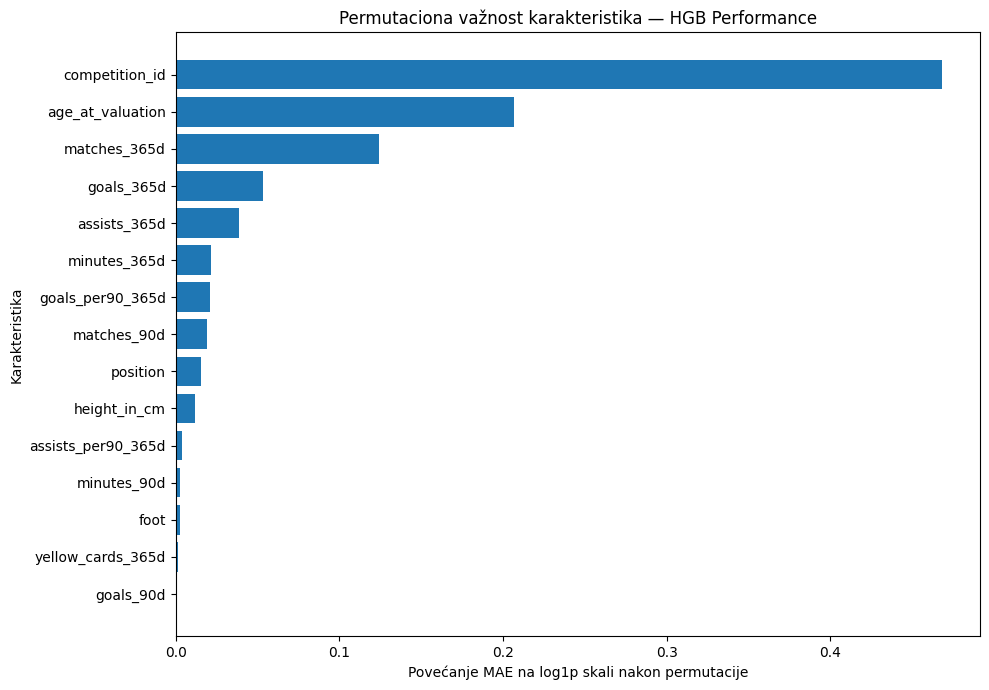

In [39]:
# VIZUELIZACIJA VAŽNOSTI

import matplotlib.pyplot as plt

top_features = feature_importance.head(15).iloc[::-1]

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["importance_mean"]
)

plt.xlabel("Povećanje MAE na log1p skali nakon permutacije")
plt.ylabel("Karakteristika")
plt.title("Permutaciona važnost karakteristika — HGB Performance")

plt.tight_layout()
plt.show()


In [40]:
# GRUPNA PERMUTACIONA VAŽNOST

rng = np.random.default_rng(42)

baseline_log_pred = hgb_performance.predict(X_sample)

baseline_log_mae = mean_absolute_error(
    y_sample_log,
    baseline_log_pred
)

grouped_increases = []

for repeat in range(10):
    shuffled = X_sample.copy()

    permutation = rng.permutation(len(shuffled))

    shuffled.loc[:, performance_numeric] = (
        X_sample[performance_numeric]
        .iloc[permutation]
        .to_numpy()
    )

    shuffled_log_pred = hgb_performance.predict(shuffled)

    shuffled_log_mae = mean_absolute_error(
        y_sample_log,
        shuffled_log_pred
    )

    grouped_increases.append(
        shuffled_log_mae - baseline_log_mae
    )

group_importance = pd.DataFrame([{
    "baseline_log_mae": baseline_log_mae,
    "mean_increase": np.mean(grouped_increases),
    "std_increase": np.std(grouped_increases),
    "relative_increase_pct": (
        100 * np.mean(grouped_increases) / baseline_log_mae
    )
}])

print("Zajednička važnost karakteristika učinka:")
display(group_importance.round(4))


Zajednička važnost karakteristika učinka:


,baseline_log_mae,mean_increase,std_increase,relative_increase_pct
0,0.6125,0.3993,0.0068,65.1937


In [41]:
# ABLACIJA TAKMIČENJA

# Iste numeričke karakteristike kao ranije
no_league_numeric = full_numeric.copy()

# Uklanjam samo competition_id
no_league_categorical = [
    "position",
    "foot"
]

no_league_features = (
    no_league_numeric + no_league_categorical
)

hgb_no_league = build_hgb_model(
    no_league_numeric,
    no_league_categorical
)

hgb_no_league.fit(
    exp_train[no_league_features],
    np.log1p(y_exp_train)
)

pred_no_league = np.maximum(
    np.expm1(
        hgb_no_league.predict(
            exp_val[no_league_features]
        )
    ),
    0
)

print("Model bez competition_id je treniran.")


Model bez competition_id je treniran.


In [42]:
# EVALUACIJA ABLACIJE

no_league_result = pd.DataFrame([
    evaluate_predictions(
        y_exp_val,
        pred_no_league,
        "HGB Performance - no league",
        "Same performance subset"
    )
])

ablation_comparison = pd.concat([
    controlled_results,
    no_league_result
], ignore_index=True)

print("Poređenje modela:")
display(ablation_comparison.round({
    "MAE_EUR": 0,
    "RMSE_EUR": 0,
    "R2": 4,
    "MAE_log1p": 4
}))

original_mae = controlled_results.loc[
    controlled_results["model"] == "HGB Performance",
    "MAE_EUR"
].iloc[0]

new_mae = no_league_result["MAE_EUR"].iloc[0]

print(
    "Povećanje MAE bez takmičenja (%):",
    round(
        100 * (new_mae - original_mae) / original_mae,
        2
    )
)


Poređenje modela:


,model,sample,observations,MAE_EUR,RMSE_EUR,R2,MAE_log1p
0,HGB Basic,Same performance subset,20986,5474297.0,12649713.0,0.1490,0.8118
1,HGB Performance,Same performance subset,20986,4133200.0,9315868.0,0.5385,0.6140
2,HGB Performance - no league,Same performance subset,20986,5377716.0,11480758.0,0.2990,0.8823


Povećanje MAE bez takmičenja (%): 30.11


In [43]:
# INSTALACIJA I PRIPREMA CATBOOST MODELA

%pip -q install catboost

import numpy as np
import pandas as pd

from catboost import CatBoostRegressor

# Koristim iste karakteristike i isti uzorak kao HGB Performance
cat_features = basic_categorical.copy()
cat_all_features = full_numeric + cat_features

X_cat_train = exp_train[cat_all_features].copy()
X_cat_val = exp_val[cat_all_features].copy()

# CatBoost kategorijske karakteristike očekuje kao stringove bez nedostajućih vrednosti.
for col in cat_features:
    X_cat_train[col] = X_cat_train[col].fillna("Unknown").astype(str)
    X_cat_val[col] = X_cat_val[col].fillna("Unknown").astype(str)

# Numeričke kolone pretvaram u numerički format.
# CatBoost može direktno da obradi NaN u numeričkim kolonama.
for col in full_numeric:
    X_cat_train[col] = pd.to_numeric(
        X_cat_train[col], errors="coerce"
    )
    X_cat_val[col] = pd.to_numeric(
        X_cat_val[col], errors="coerce"
    )

y_cat_train_log = np.log1p(y_exp_train)
y_cat_val_log = np.log1p(y_exp_val)

print("Trening opažanja:", len(X_cat_train))
print("Validacionih opažanja:", len(X_cat_val))
print("Broj karakteristika:", len(cat_all_features))
print("Kategorijske karakteristike:", cat_features)


Trening opažanja: 75904
Validacionih opažanja: 20986
Broj karakteristika: 17
Kategorijske karakteristike: ['position', 'foot', 'competition_id']


In [44]:
# TRENIRANJE CATBOOST MODELA

catboost_model = CatBoostRegressor(
    iterations=1200,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    eval_metric="MAE",
    l2_leaf_reg=5,
    random_seed=42,
    verbose=200,
    thread_count=2
)

catboost_model.fit(
    X_cat_train,
    y_cat_train_log,
    cat_features=cat_features,
    eval_set=(X_cat_val, y_cat_val_log),
    early_stopping_rounds=100,
    use_best_model=True
)

cat_pred_log = catboost_model.predict(X_cat_val)

cat_pred_eur = np.maximum(
    np.expm1(cat_pred_log),
    0
)

print("\nCatBoost model je treniran.")
print("Najbolja iteracija:", catboost_model.get_best_iteration())


0:	learn: 1.1363060	test: 1.1967742	best: 1.1967742 (0)	total: 147ms	remaining: 2m 55s
200:	learn: 0.6195968	test: 0.6254262	best: 0.6254262 (200)	total: 26.7s	remaining: 2m 12s
400:	learn: 0.6036225	test: 0.6188748	best: 0.6188329 (398)	total: 51.8s	remaining: 1m 43s
600:	learn: 0.5930090	test: 0.6167614	best: 0.6167484 (599)	total: 1m 5s	remaining: 1m 5s
800:	learn: 0.5852865	test: 0.6156535	best: 0.6156092 (788)	total: 1m 18s	remaining: 39.1s
1000:	learn: 0.5788846	test: 0.6151207	best: 0.6151145 (994)	total: 1m 31s	remaining: 18.2s
1199:	learn: 0.5736056	test: 0.6143859	best: 0.6143612 (1189)	total: 1m 44s	remaining: 0us

bestTest = 0.6143611827
bestIteration = 1189

Shrink model to first 1190 iterations.

CatBoost model je treniran.
Najbolja iteracija: 1189


In [45]:
# EVALUACIJA CATBOOST MODELA

catboost_results = pd.DataFrame([
    evaluate_predictions(
        y_exp_val,
        cat_pred_eur,
        "CatBoost Performance",
        "Same performance subset"
    )
])

model_comparison = pd.concat([
    controlled_results,
    catboost_results
], ignore_index=True)

print("Poređenje modela na istom validacionom uzorku:")
display(model_comparison.round({
    "MAE_EUR": 0,
    "RMSE_EUR": 0,
    "R2": 4,
    "MAE_log1p": 4
}))

hgb_mae = controlled_results.loc[
    controlled_results["model"] == "HGB Performance",
    "MAE_EUR"
].iloc[0]

cat_mae = catboost_results["MAE_EUR"].iloc[0]

print(
    "\nPromena MAE u odnosu na HGB (%):",
    round(100 * (hgb_mae - cat_mae) / hgb_mae, 2)
)


Poređenje modela na istom validacionom uzorku:


,model,sample,observations,MAE_EUR,RMSE_EUR,R2,MAE_log1p
0,HGB Basic,Same performance subset,20986,5474297.0,12649713.0,0.1490,0.8118
1,HGB Performance,Same performance subset,20986,4133200.0,9315868.0,0.5385,0.6140
2,CatBoost Performance,Same performance subset,20986,4116465.0,9274803.0,0.5425,0.6144



Promena MAE u odnosu na HGB (%): 0.4


In [46]:
# RASPODELA PREDIKCIJA

cat_prediction_summary = pd.DataFrame({
    "actual_eur": y_exp_val,
    "hgb_eur": pred_performance,
    "catboost_eur": cat_pred_eur
})

print("Raspodela stvarnih i predviđenih vrednosti:")
display(
    cat_prediction_summary.agg([
        "min", "median", "mean", "max"
    ]).round(0)
)


Raspodela stvarnih i predviđenih vrednosti:


,actual_eur,hgb_eur,catboost_eur
min,25000.0,60904.0,68615.0
median,2800000.0,2426108.0,2423609.0
mean,7950215.0,5087264.0,5074840.0
max,180000000.0,139610174.0,122176499.0


In [47]:
# DATUMI VALIDACIONIH OPAŽANJA

# Uzimam datume iz modeling_split, istim redosledom
# kojim je kreiran exp_val.

validation_dates = con.execute("""
    SELECT
        valuation_date
    FROM modeling_split
    WHERE eligible_performance_model = 1
      AND dataset_split = 'validation'
    ORDER BY player_id, valuation_date
""").df()

# Za bezbedno povezivanje podataka neću se oslanjati
# na podrazumevani redosled redova iz DuckDB.
# Zato eksplicitno izdvajam identifikatore iz exp_val,
# ako su dostupni, ili ih povezujem pomoću stabilnog ključa.

print("Broj validacionih datuma:", len(validation_dates))
print("Broj validacionih predikcija:", len(cat_pred_eur))


Broj validacionih datuma: 20986
Broj validacionih predikcija: 20986


In [48]:
# GODIŠNJA EVALUACIJA

yearly_data = con.execute("""
    SELECT
        player_id,
        valuation_date,
        market_value_in_eur,
        age_at_valuation,
        height_in_cm,
        position,
        foot,
        competition_id,
        matches_90d,
        minutes_90d,
        goals_90d,
        assists_90d,
        matches_365d,
        minutes_365d,
        goals_365d,
        assists_365d,
        yellow_cards_365d,
        red_cards_365d,
        goals_per90_365d,
        assists_per90_365d
    FROM modeling_split
    WHERE eligible_performance_model = 1
      AND dataset_split = 'validation'
    ORDER BY player_id, valuation_date
""").df()

# Predikcije već treniranih modela na istim karakteristikama
X_yearly_hgb = yearly_data[full_features].copy()

X_yearly_cat = yearly_data[cat_all_features].copy()

for col in cat_features:
    X_yearly_cat[col] = (
        X_yearly_cat[col]
        .fillna("Unknown")
        .astype(str)
    )

for col in full_numeric:
    X_yearly_cat[col] = pd.to_numeric(
        X_yearly_cat[col],
        errors="coerce"
    )

yearly_data["hgb_pred"] = np.maximum(
    np.expm1(
        hgb_performance.predict(X_yearly_hgb)
    ),
    0
)

yearly_data["catboost_pred"] = np.maximum(
    np.expm1(
        catboost_model.predict(X_yearly_cat)
    ),
    0
)

yearly_data["year"] = pd.to_datetime(
    yearly_data["valuation_date"]
).dt.year

yearly_results = []

for year, group in yearly_data.groupby("year"):

    y_true = group["market_value_in_eur"].to_numpy()

    yearly_results.append(
        evaluate_predictions(
            y_true,
            group["hgb_pred"].to_numpy(),
            "HGB Performance",
            str(year)
        )
    )

    yearly_results.append(
        evaluate_predictions(
            y_true,
            group["catboost_pred"].to_numpy(),
            "CatBoost Performance",
            str(year)
        )
    )

yearly_results_df = pd.DataFrame(yearly_results)

print("Rezultati po godinama:")
display(yearly_results_df.round({
    "MAE_EUR": 0,
    "RMSE_EUR": 0,
    "R2": 4,
    "MAE_log1p": 4
}))


Rezultati po godinama:


,model,sample,observations,MAE_EUR,RMSE_EUR,R2,MAE_log1p
0,HGB Performance,2022,10501,3795166.0,8445900.0,0.5732,0.5978
1,CatBoost Performance,2022,10501,3777723.0,8406978.0,0.5771,0.5964
2,HGB Performance,2023,10485,4471749.0,10112426.0,0.5098,0.6303
3,CatBoost Performance,2023,10485,4455725.0,10069264.0,0.5140,0.6323


In [49]:
# KONTROLA KONZISTENTNOSTI

from sklearn.metrics import mean_absolute_error

y_yearly = yearly_data["market_value_in_eur"].to_numpy()

print(
    "HGB MAE:",
    round(
        mean_absolute_error(
            y_yearly,
            yearly_data["hgb_pred"]
        ),
        2
    )
)

print(
    "CatBoost MAE:",
    round(
        mean_absolute_error(
            y_yearly,
            yearly_data["catboost_pred"]
        ),
        2
    )
)

print("\nOčekivane vrednosti približno:")
print("HGB: 4133200")
print("CatBoost: 4109283")


HGB MAE: 4133199.78
CatBoost MAE: 4116465.28

Očekivane vrednosti približno:
HGB: 4133200
CatBoost: 4109283


In [50]:
# FINALNI TRENING I TEST PODACI

final_data = con.execute("""
    SELECT
        player_id,
        valuation_date,
        dataset_split,
        market_value_in_eur,
        age_at_valuation,
        height_in_cm,
        position,
        foot,
        competition_id,
        matches_90d,
        minutes_90d,
        goals_90d,
        assists_90d,
        matches_365d,
        minutes_365d,
        goals_365d,
        assists_365d,
        yellow_cards_365d,
        red_cards_365d,
        goals_per90_365d,
        assists_per90_365d
    FROM modeling_split
    WHERE eligible_performance_model = 1
    ORDER BY player_id, valuation_date
""").df()

final_train = final_data[
    final_data["dataset_split"].isin(["train", "validation"])
].copy()

final_test = final_data[
    final_data["dataset_split"] == "test"
].copy()

X_final_train = final_train[cat_all_features].copy()
X_final_test = final_test[cat_all_features].copy()

for col in cat_features:
    X_final_train[col] = (
        X_final_train[col].fillna("Unknown").astype(str)
    )
    X_final_test[col] = (
        X_final_test[col].fillna("Unknown").astype(str)
    )

for col in full_numeric:
    X_final_train[col] = pd.to_numeric(
        X_final_train[col], errors="coerce"
    )
    X_final_test[col] = pd.to_numeric(
        X_final_test[col], errors="coerce"
    )

y_final_train = final_train["market_value_in_eur"].to_numpy()
y_final_test = final_test["market_value_in_eur"].to_numpy()

print("Finalni trening:", len(final_train))
print("Test:", len(final_test))

print(
    "Trening period:",
    final_train["valuation_date"].min(),
    "do",
    final_train["valuation_date"].max()
)

print(
    "Test period:",
    final_test["valuation_date"].min(),
    "do",
    final_test["valuation_date"].max()
)


Finalni trening: 96890
Test: 20563
Trening period: 2014-01-02 00:00:00 do 2023-12-29 00:00:00
Test period: 2024-01-08 00:00:00 do 2025-12-30 00:00:00


In [51]:
# KONAČNI CATBOOST MODEL

from catboost import CatBoostRegressor

final_catboost = CatBoostRegressor(
    iterations=1156,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    l2_leaf_reg=5,
    random_seed=42,
    verbose=200,
    thread_count=2
)

final_catboost.fit(
    X_final_train,
    np.log1p(y_final_train),
    cat_features=cat_features
)

final_test_pred_log = final_catboost.predict(
    X_final_test
)

final_test_pred_eur = np.maximum(
    np.expm1(final_test_pred_log),
    0
)

print("Konačni CatBoost model je treniran.")


0:	learn: 1.3845328	total: 140ms	remaining: 2m 41s
200:	learn: 0.7859033	total: 36.2s	remaining: 2m 52s
400:	learn: 0.7693597	total: 1m 4s	remaining: 2m
600:	learn: 0.7595714	total: 1m 18s	remaining: 1m 12s
800:	learn: 0.7521239	total: 1m 45s	remaining: 46.8s
1000:	learn: 0.7451546	total: 2m 2s	remaining: 19s
1155:	learn: 0.7407534	total: 2m 13s	remaining: 0us
Konačni CatBoost model je treniran.


In [52]:
# TEST REZULTATI

final_test_results = pd.DataFrame([
    evaluate_predictions(
        y_final_test,
        final_test_pred_eur,
        "CatBoost Final",
        "Test 2024-2025"
    )
])

print("Konačni test rezultati:")
display(final_test_results.round({
    "MAE_EUR": 0,
    "RMSE_EUR": 0,
    "R2": 4,
    "MAE_log1p": 4
}))


Konačni test rezultati:


,model,sample,observations,MAE_EUR,RMSE_EUR,R2,MAE_log1p
0,CatBoost Final,Test 2024-2025,20563,4606235.0,10333031.0,0.575,0.6389


In [53]:
# TEST PO GODINAMA

test_analysis = final_test[
    ["player_id", "valuation_date", "market_value_in_eur", "position"]
].copy()

test_analysis["predicted_eur"] = final_test_pred_eur

test_analysis["year"] = pd.to_datetime(
    test_analysis["valuation_date"]
).dt.year

test_year_results = []

for year, group in test_analysis.groupby("year"):
    test_year_results.append(
        evaluate_predictions(
            group["market_value_in_eur"].to_numpy(),
            group["predicted_eur"].to_numpy(),
            "CatBoost Final",
            str(year)
        )
    )

test_year_results_df = pd.DataFrame(test_year_results)

print("Test rezultati po godinama:")
display(test_year_results_df.round({
    "MAE_EUR": 0,
    "RMSE_EUR": 0,
    "R2": 4,
    "MAE_log1p": 4
}))

Test rezultati po godinama:


,model,sample,observations,MAE_EUR,RMSE_EUR,R2,MAE_log1p
0,CatBoost Final,2024,10226,4555112.0,10361613.0,0.5575,0.6398
1,CatBoost Final,2025,10337,4656808.0,10304677.0,0.5907,0.6380


In [54]:
# STVARNE I PREDVIĐENE VREDNOSTI

test_distribution = pd.DataFrame({
    "actual_eur": y_final_test,
    "predicted_eur": final_test_pred_eur
})

print("Raspodela vrednosti na test skupu:")
display(
    test_distribution.agg([
        "min", "median", "mean", "max"
    ]).round(0)
)

Raspodela vrednosti na test skupu:


,actual_eur,predicted_eur
min,25000.0,82849.0
median,3000000.0,2438985.0
mean,9182691.0,5728434.0
max,200000000.0,154160285.0


In [55]:
# PRIPREMA RETROSPEKTIVNE ANALIZE

# test_analysis već sadrži:
# player_id, valuation_date, market_value_in_eur,
# position, predicted_eur, year

con.register(
    "test_predictions_for_analysis",
    test_analysis[
        [
            "player_id",
            "valuation_date",
            "market_value_in_eur",
            "position",
            "predicted_eur"
        ]
    ]
)

future_analysis = con.execute("""
    SELECT
        t.player_id,
        t.valuation_date,
        t.position,
        t.market_value_in_eur AS initial_value_eur,
        t.predicted_eur,

        t.predicted_eur - t.market_value_in_eur
            AS residual_eur,

        t.predicted_eur
            / NULLIF(t.market_value_in_eur, 0) - 1
            AS residual_ratio,

        f.future_date,
        f.future_value_eur,

        DATE_DIFF(
            'day',
            CAST(t.valuation_date AS DATE),
            f.future_date
        ) AS days_to_future,

        f.future_value_eur
            / NULLIF(t.market_value_in_eur, 0) - 1
            AS future_return

    FROM test_predictions_for_analysis t

    LEFT JOIN LATERAL (
        SELECT
            v.date AS future_date,
            v.market_value_in_eur AS future_value_eur
        FROM player_valuations v
        WHERE v.player_id = t.player_id
          AND v.date >= CAST(t.valuation_date AS DATE)
                         + INTERVAL '180 days'
          AND v.date <= CAST(t.valuation_date AS DATE)
                         + INTERVAL '450 days'
          AND v.market_value_in_eur > 0
        ORDER BY
            ABS(
                DATE_DIFF(
                    'day',
                    CAST(t.valuation_date AS DATE)
                        + INTERVAL '365 days',
                    v.date
                )
            ),
            v.date
        LIMIT 1
    ) f ON TRUE
""").df()

print("Ukupan broj test opažanja:", len(future_analysis))

print(
    "Opažanja sa budućom vrednošću:",
    future_analysis["future_value_eur"].notna().sum()
)

print(
    "Opažanja bez buduće vrednosti:",
    future_analysis["future_value_eur"].isna().sum()
)

display(future_analysis.head())


Ukupan broj test opažanja: 20563
Opažanja sa budućom vrednošću: 15468
Opažanja bez buduće vrednosti: 5095


,player_id,valuation_date,position,initial_value_eur,predicted_eur,residual_eur,residual_ratio,future_date,future_value_eur,days_to_future,future_return
0,11530,2024-03-15,Defender,650000,513966.933130,-1.360331e+05,-0.209282,2025-03-20,400000,370,-0.384615
1,14086,2024-05-27,Defender,500000,893050.940668,3.930509e+05,0.786102,2025-05-30,500000,368,0.000000
2,16136,2024-12-10,Defender,500000,334008.057583,-1.659919e+05,-0.331984,2025-12-15,500000,370,0.000000
3,17259,2025-06-05,Goalkeeper,4000000,957593.769026,-3.042406e+06,-0.760602,2026-05-27,4000000,356,0.000000
4,30321,2024-03-21,Midfield,1500000,641798.301132,-8.582017e+05,-0.572134,2025-06-09,500000,445,-0.666667


In [56]:
# POKRIVENOST BUDUĆIM VREDNOSTIMA

future_analysis["year"] = pd.to_datetime(
    future_analysis["valuation_date"]
).dt.year

future_coverage = (
    future_analysis.groupby("year")
    .agg(
        observations=("player_id", "size"),
        with_future_value=("future_value_eur", "count"),
        median_initial_value=("initial_value_eur", "median"),
        median_future_return=("future_return", "median")
    )
    .reset_index()
)

future_coverage["coverage_pct"] = (
    100
    * future_coverage["with_future_value"]
    / future_coverage["observations"]
)

print("Pokrivenost budućim procenama:")
display(future_coverage.round(3))


Pokrivenost budućim procenama:


,year,observations,with_future_value,median_initial_value,median_future_return,coverage_pct
0,2024,10226,9408,3000000.0,-0.143,92.001
1,2025,10337,6060,3200000.0,-0.125,58.624


In [57]:
# RASPODELA REZIDUALA

residual_summary = pd.DataFrame([{
    "observations": len(future_analysis),
    "positive_residuals": int(
        (future_analysis["residual_eur"] > 0).sum()
    ),
    "negative_residuals": int(
        (future_analysis["residual_eur"] < 0).sum()
    ),
    "positive_pct": round(
        100 * (future_analysis["residual_eur"] > 0).mean(),
        2
    ),
    "median_residual_eur": future_analysis[
        "residual_eur"
    ].median(),
    "median_residual_ratio": future_analysis[
        "residual_ratio"
    ].median()
}])

print("Raspodela modelskih reziduala:")
display(residual_summary.round(3))


Raspodela modelskih reziduala:


,observations,positive_residuals,negative_residuals,positive_pct,median_residual_eur,median_residual_ratio
0,20563,8607,11956,41.86,-353988.934,-0.154


In [58]:
# POKRIVENOST U UŽEM VREMENSKOM PROZORU

import numpy as np
import pandas as pd

window_check = future_analysis.copy()

window_check["eligible_1y"] = (
    (window_check["days_to_future"] >= 330)
    & (window_check["days_to_future"] <= 400)
)

coverage_by_year = (
    window_check.groupby("year")
    .agg(
        total_observations=("player_id", "size"),
        with_1y_value=("eligible_1y", "sum")
    )
    .reset_index()
)

coverage_by_year["coverage_pct"] = (
    100
    * coverage_by_year["with_1y_value"]
    / coverage_by_year["total_observations"]
)

print("Preliminarna pokrivenost oko 365. dana:")
display(coverage_by_year.round(2))


Preliminarna pokrivenost oko 365. dana:


,year,total_observations,with_1y_value,coverage_pct
0,2024,10226,7975,77.99
1,2025,10337,3828,37.03


In [59]:
# JEDNOGODIŠNJI ISHOD ZA 2024.

future_2024 = con.execute("""
    SELECT
        t.player_id,
        t.valuation_date,
        t.position,

        t.market_value_in_eur AS initial_value_eur,
        t.predicted_eur,

        t.predicted_eur - t.market_value_in_eur
            AS residual_eur,

        t.predicted_eur
            / NULLIF(t.market_value_in_eur, 0) - 1
            AS residual_ratio,

        f.future_date,
        f.future_value_eur,

        DATE_DIFF(
            'day',
            CAST(t.valuation_date AS DATE),
            f.future_date
        ) AS days_to_future,

        f.future_value_eur
            / NULLIF(t.market_value_in_eur, 0) - 1
            AS future_return

    FROM test_predictions_for_analysis t

    LEFT JOIN LATERAL (
        SELECT
            v.date AS future_date,
            v.market_value_in_eur AS future_value_eur
        FROM player_valuations v
        WHERE v.player_id = t.player_id

          AND v.date >= CAST(t.valuation_date AS DATE)
                         + INTERVAL '330 days'

          AND v.date <= CAST(t.valuation_date AS DATE)
                         + INTERVAL '400 days'

          AND v.market_value_in_eur > 0

        ORDER BY
            ABS(
                DATE_DIFF(
                    'day',
                    CAST(t.valuation_date AS DATE)
                        + INTERVAL '365 days',
                    v.date
                )
            ),
            v.date
        LIMIT 1
    ) f ON TRUE

    WHERE CAST(t.valuation_date AS DATE) >= DATE '2024-01-01'
      AND CAST(t.valuation_date AS DATE) < DATE '2025-01-01'
""").df()

print("Ukupno početnih procena iz 2024:", len(future_2024))

print(
    "Sa jednogodišnjom budućom procenom:",
    future_2024["future_value_eur"].notna().sum()
)

print(
    "Pokrivenost (%):",
    round(
        100 * future_2024["future_value_eur"].notna().mean(),
        2
    )
)

print("\nRaspodela vremenskog razmaka:")
display(
    future_2024["days_to_future"]
    .dropna()
    .describe()
    .round(2)
)

Ukupno početnih procena iz 2024: 10226
Sa jednogodišnjom budućom procenom: 7975
Pokrivenost (%): 77.99

Raspodela vremenskog razmaka:


,days_to_future
count,7975.0
mean,366.2
std,8.81
min,332.0
25%,361.0
50%,367.0
75%,371.0
max,399.0


In [60]:
# BROJ IGRAČA I PONOVLJENIH PROCENA

valid_future_2024 = future_2024[
    future_2024["future_value_eur"].notna()
].copy()

print(
    "Broj opažanja:",
    len(valid_future_2024)
)

print(
    "Broj jedinstvenih igrača:",
    valid_future_2024["player_id"].nunique()
)

print(
    "Prosečan broj procena po igraču:",
    round(
        len(valid_future_2024)
        / valid_future_2024["player_id"].nunique(),
        2
    )
)

print("\nBroj igrača prema broju procena:")

display(
    valid_future_2024.groupby("player_id")
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("valuations_per_player")
    .reset_index(name="players")
)


Broj opažanja: 7975
Broj jedinstvenih igrača: 4255
Prosečan broj procena po igraču: 1.87

Broj igrača prema broju procena:


,valuations_per_player,players
0,1,1292
1,2,2330
2,3,510
3,4,122
4,5,1


In [61]:
# JEDNA POČETNA PROCENA PO IGRAČU

import numpy as np
import pandas as pd

# Polazim od SVIH početnih procena iz 2024, uključujući i one bez buduće vrednosti.
# Najraniju procenu biram nezavisno od dostupnosti budućeg ishoda.

analysis_2024 = future_2024.copy()

analysis_2024["valuation_date"] = pd.to_datetime(
    analysis_2024["valuation_date"]
)

analysis_2024 = analysis_2024.sort_values(
    ["player_id", "valuation_date"]
)

player_cohort = (
    analysis_2024
    .drop_duplicates(subset=["player_id"], keep="first")
    .copy()
    .reset_index(drop=True)
)

print("Jedinstveni igrači u početnoj kohorti:",
      len(player_cohort))

print(
    "Sa budućom procenom:",
    player_cohort["future_value_eur"].notna().sum()
)

print(
    "Bez buduće procene:",
    player_cohort["future_value_eur"].isna().sum()
)

print(
    "Pokrivenost (%):",
    round(
        100 * player_cohort["future_value_eur"].notna().mean(),
        2
    )
)

assert player_cohort["player_id"].is_unique


Jedinstveni igrači u početnoj kohorti: 4961
Sa budućom procenom: 3586
Bez buduće procene: 1375
Pokrivenost (%): 72.28


In [62]:
# PRIPREMA BUDUĆEG ISHODA

cohort_with_outcome = player_cohort[
    player_cohort["future_value_eur"].notna()
].copy()

cohort_with_outcome["future_growth"] = (
    cohort_with_outcome["future_value_eur"]
    / cohort_with_outcome["initial_value_eur"]
    - 1
)

cohort_with_outcome["future_log_growth"] = (
    np.log(cohort_with_outcome["future_value_eur"])
    - np.log(cohort_with_outcome["initial_value_eur"])
)

cohort_with_outcome["value_increased"] = (
    cohort_with_outcome["future_value_eur"]
    > cohort_with_outcome["initial_value_eur"]
).astype(int)

cohort_with_outcome["positive_residual"] = (
    cohort_with_outcome["residual_eur"] > 0
).astype(int)

print("Broj igrača za analizu:",
      len(cohort_with_outcome))

print(
    "Udeo igrača sa rastom vrednosti (%):",
    round(
        100 * cohort_with_outcome["value_increased"].mean(),
        2
    )
)

print(
    "Medijalna buduća promena (%):",
    round(
        100 * cohort_with_outcome["future_growth"].median(),
        2
    )
)

print(
    "Udeo pozitivnih reziduala (%):",
    round(
        100 * cohort_with_outcome["positive_residual"].mean(),
        2
    )
)


Broj igrača za analizu: 3586
Udeo igrača sa rastom vrednosti (%): 32.96
Medijalna buduća promena (%): -12.5
Udeo pozitivnih reziduala (%): 43.59


In [63]:
# REZIDUALI I BUDUĆI RAST

residual_groups = (
    cohort_with_outcome
    .groupby("positive_residual")
    .agg(
        players=("player_id", "nunique"),
        median_initial_value=("initial_value_eur", "median"),
        median_future_growth=("future_growth", "median"),
        mean_future_log_growth=("future_log_growth", "mean"),
        share_value_increased=("value_increased", "mean"),
        median_residual_ratio=("residual_ratio", "median")
    )
    .reset_index()
)

residual_groups["group"] = residual_groups[
    "positive_residual"
].map({
    0: "Negative or zero residual",
    1: "Positive residual"
})

residual_groups["median_future_growth_pct"] = (
    100 * residual_groups["median_future_growth"]
)

residual_groups["share_value_increased_pct"] = (
    100 * residual_groups["share_value_increased"]
)

print("Poređenje prema znaku reziduala:")

display(
    residual_groups[
        [
            "group",
            "players",
            "median_initial_value",
            "median_future_growth_pct",
            "mean_future_log_growth",
            "share_value_increased_pct",
            "median_residual_ratio"
        ]
    ].round(3)
)


Poređenje prema znaku reziduala:


,group,players,median_initial_value,median_future_growth_pct,mean_future_log_growth,share_value_increased_pct,median_residual_ratio
0,Negative or zero residual,2023,5000000.0,-12.5,-0.083,33.564,-0.449
1,Positive residual,1563,900000.0,-11.111,-0.044,32.182,0.599


In [64]:
# KONTROLNE KARAKTERISTIKE

controls_2024 = con.execute("""
    SELECT
        player_id,
        valuation_date,
        age_at_valuation,
        competition_id
    FROM modeling_split
    WHERE eligible_performance_model = 1
      AND dataset_split = 'test'
      AND valuation_date >= DATE '2024-01-01'
      AND valuation_date < DATE '2025-01-01'
""").df()

controls_2024["valuation_date"] = pd.to_datetime(
    controls_2024["valuation_date"]
)

analysis_controls = cohort_with_outcome.merge(
    controls_2024,
    on=["player_id", "valuation_date"],
    how="left",
    validate="one_to_one"
)

print("Broj igrača:", len(analysis_controls))
print(
    "Nedostaje starost:",
    analysis_controls["age_at_valuation"].isna().sum()
)
print(
    "Nedostaje takmičenje:",
    analysis_controls["competition_id"].isna().sum()
)


Broj igrača: 3586
Nedostaje starost: 1
Nedostaje takmičenje: 0


In [65]:
# PROMENLJIVE ZA REGRESIJU

analysis_controls["log_initial_value"] = np.log(
    analysis_controls["initial_value_eur"]
)

analysis_controls["log_prediction_ratio"] = np.log(
    analysis_controls["predicted_eur"]
    / analysis_controls["initial_value_eur"]
)

analysis_controls["position"] = (
    analysis_controls["position"]
    .fillna("Unknown")
    .astype(str)
)

analysis_controls["competition_id"] = (
    analysis_controls["competition_id"]
    .fillna("UNKNOWN")
    .astype(str)
)

regression_data = analysis_controls.dropna(
    subset=[
        "age_at_valuation",
        "log_initial_value",
        "log_prediction_ratio",
        "future_log_growth",
        "value_increased"
    ]
).copy()

print("Broj igrača za regresiju:", len(regression_data))

print("\nOpis relativnog modelskog odstupanja:")
display(
    regression_data["log_prediction_ratio"]
    .describe()
    .round(3)
)


Broj igrača za regresiju: 3585

Opis relativnog modelskog odstupanja:


,log_prediction_ratio
count,3585.000
mean,-0.169
std,0.763
min,-3.252
25%,-0.666
50%,-0.133
75%,0.402
max,2.256


In [66]:
# LOGISTIČKA REGRESIJA

import statsmodels.formula.api as smf

top_competitions = (
    regression_data["competition_id"]
    .value_counts()
    .head(15)
    .index
)

regression_data["competition_group"] = (
    regression_data["competition_id"]
    .where(
        regression_data["competition_id"].isin(
            top_competitions
        ),
        "OTHER"
    )
)

logit_model = smf.logit(
    formula="""
        value_increased
        ~ log_prediction_ratio
        + log_initial_value
        + age_at_valuation
        + C(position)
        + C(competition_group)
    """,
    data=regression_data
).fit(disp=False, maxiter=200)

print("Logistička regresija:")
print(
    logit_model.summary2().tables[1]
    .loc[
        [
            "log_prediction_ratio",
            "log_initial_value",
            "age_at_valuation"
        ]
    ]
)


Logistička regresija:
                         Coef.  Std.Err.          z          P>|z|    [0.025  \
log_prediction_ratio  0.230655  0.088146   2.616747   8.877205e-03  0.057893   
log_initial_value    -0.031911  0.065928  -0.484019   6.283726e-01 -0.161128   
age_at_valuation     -0.305638  0.013421 -22.772898  8.512814e-115 -0.331943   

                        0.975]  
log_prediction_ratio  0.403418  
log_initial_value     0.097307  
age_at_valuation     -0.279333  


In [67]:
# LINEARNA REGRESIJA

ols_model = smf.ols(
    formula="""
        future_log_growth
        ~ log_prediction_ratio
        + log_initial_value
        + age_at_valuation
        + C(position)
        + C(competition_group)
    """,
    data=regression_data
).fit(cov_type="HC3")

print("Linearna regresija:")
print(
    ols_model.summary2().tables[1]
    .loc[
        [
            "log_prediction_ratio",
            "log_initial_value",
            "age_at_valuation"
        ]
    ]
)

print("\nR²:", round(ols_model.rsquared, 4))
print(
    "Prilagođeni R²:",
    round(ols_model.rsquared_adj, 4)
)


Linearna regresija:
                         Coef.  Std.Err.          z          P>|z|    [0.025  \
log_prediction_ratio  0.040590  0.015759   2.575626   1.000589e-02  0.009702   
log_initial_value    -0.056051  0.011762  -4.765214   1.886531e-06 -0.079104   
age_at_valuation     -0.071020  0.002444 -29.060193  1.143951e-185 -0.075810   

                        0.975]  
log_prediction_ratio  0.071478  
log_initial_value    -0.032997  
age_at_valuation     -0.066230  

R²: 0.2681
Prilagođeni R²: 0.2637


In [68]:

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge

from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    log_loss,
    mean_absolute_error,
    mean_squared_error
)

# Koristimo podatke pripremljene u Koraku 28
cv_data = regression_data.copy().reset_index(drop=True)

base_numeric = [
    "log_initial_value",
    "age_at_valuation"
]

extra_numeric = [
    "log_prediction_ratio"
]

categorical = [
    "position",
    "competition_group"
]

X_base = cv_data[base_numeric + categorical].copy()
X_plus = cv_data[
    base_numeric + extra_numeric + categorical
].copy()

y_binary = cv_data["value_increased"].to_numpy()
y_growth = cv_data["future_log_growth"].to_numpy()

def make_preprocessor(numeric_features):
    return ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())
                ]),
                numeric_features
            ),
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore"),
                categorical
            )
        ]
    )

def make_classifier(numeric_features):
    return Pipeline([
        (
            "preprocess",
            make_preprocessor(numeric_features)
        ),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                C=1.0,
                random_state=42
            )
        )
    ])

def make_regressor(numeric_features):
    return Pipeline([
        (
            "preprocess",
            make_preprocessor(numeric_features)
        ),
        (
            "model",
            Ridge(alpha=10.0)
        )
    ])

print("Broj igrača:", len(cv_data))
print("Jedinstveni igrači:", cv_data["player_id"].nunique())
print("Udeo igrača sa rastom:", round(y_binary.mean() * 100, 2), "%")

assert cv_data["player_id"].is_unique


Broj igrača: 3585
Jedinstveni igrači: 3585
Udeo igrača sa rastom: 32.97 %


In [69]:
# VEROVATNOĆA RASTA VREDNOSTI

cv_classification = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_base_prob = np.zeros(len(cv_data))
oof_plus_prob = np.zeros(len(cv_data))

for train_idx, valid_idx in cv_classification.split(
    X_base, y_binary
):

    base_clf = make_classifier(base_numeric)

    plus_clf = make_classifier(
        base_numeric + extra_numeric
    )

    base_clf.fit(
        X_base.iloc[train_idx],
        y_binary[train_idx]
    )

    plus_clf.fit(
        X_plus.iloc[train_idx],
        y_binary[train_idx]
    )

    oof_base_prob[valid_idx] = (
        base_clf.predict_proba(
            X_base.iloc[valid_idx]
        )[:, 1]
    )

    oof_plus_prob[valid_idx] = (
        plus_clf.predict_proba(
            X_plus.iloc[valid_idx]
        )[:, 1]
    )

classification_results = pd.DataFrame([
    {
        "model": "A - Without residual",
        "AUC": roc_auc_score(
            y_binary, oof_base_prob
        ),
        "Brier": brier_score_loss(
            y_binary, oof_base_prob
        ),
        "LogLoss": log_loss(
            y_binary, oof_base_prob
        )
    },
    {
        "model": "B - With residual",
        "AUC": roc_auc_score(
            y_binary, oof_plus_prob
        ),
        "Brier": brier_score_loss(
            y_binary, oof_plus_prob
        ),
        "LogLoss": log_loss(
            y_binary, oof_plus_prob
        )
    }
])

print("KLASIFIKACIJA BUDUĆEG RASTA")
display(classification_results.round(5))


KLASIFIKACIJA BUDUĆEG RASTA


,model,AUC,Brier,LogLoss
0,A - Without residual,0.77205,0.17950,0.52663
1,B - With residual,0.77173,0.17949,0.52658


In [70]:
# VELIČINA BUDUĆE PROMENE

cv_regression = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_base_growth = np.zeros(len(cv_data))
oof_plus_growth = np.zeros(len(cv_data))

for train_idx, valid_idx in cv_regression.split(X_base):

    base_reg = make_regressor(base_numeric)

    plus_reg = make_regressor(
        base_numeric + extra_numeric
    )

    base_reg.fit(
        X_base.iloc[train_idx],
        y_growth[train_idx]
    )

    plus_reg.fit(
        X_plus.iloc[train_idx],
        y_growth[train_idx]
    )

    oof_base_growth[valid_idx] = (
        base_reg.predict(
            X_base.iloc[valid_idx]
        )
    )

    oof_plus_growth[valid_idx] = (
        plus_reg.predict(
            X_plus.iloc[valid_idx]
        )
    )

growth_results = pd.DataFrame([
    {
        "model": "A - Without residual",
        "MAE_log_growth": mean_absolute_error(
            y_growth, oof_base_growth
        ),
        "RMSE_log_growth": np.sqrt(
            mean_squared_error(
                y_growth, oof_base_growth
            )
        )
    },
    {
        "model": "B - With residual",
        "MAE_log_growth": mean_absolute_error(
            y_growth, oof_plus_growth
        ),
        "RMSE_log_growth": np.sqrt(
            mean_squared_error(
                y_growth, oof_plus_growth
            )
        )
    }
])

print("REGRESIJA BUDUĆE PROMENE")
display(growth_results.round(5))


REGRESIJA BUDUĆE PROMENE


,model,MAE_log_growth,RMSE_log_growth
0,A - Without residual,0.35479,0.47573
1,B - With residual,0.35414,0.47538


In [71]:
# POBOLJŠANJE DODAVANJEM REZIDUALA

a_cls = classification_results.iloc[0]
b_cls = classification_results.iloc[1]

a_reg = growth_results.iloc[0]
b_reg = growth_results.iloc[1]

print("PROMENA NAKON DODAVANJA REZIDUALA")
print()

print(
    "AUC razlika:",
    round(b_cls["AUC"] - a_cls["AUC"], 5)
)

print(
    "Brier poboljšanje (%):",
    round(
        100 * (
            a_cls["Brier"] - b_cls["Brier"]
        ) / a_cls["Brier"],
        3
    )
)

print(
    "LogLoss poboljšanje (%):",
    round(
        100 * (
            a_cls["LogLoss"] - b_cls["LogLoss"]
        ) / a_cls["LogLoss"],
        3
    )
)

print(
    "MAE log growth poboljšanje (%):",
    round(
        100 * (
            a_reg["MAE_log_growth"]
            - b_reg["MAE_log_growth"]
        ) / a_reg["MAE_log_growth"],
        3
    )
)

print(
    "RMSE log growth poboljšanje (%):",
    round(
        100 * (
            a_reg["RMSE_log_growth"]
            - b_reg["RMSE_log_growth"]
        ) / a_reg["RMSE_log_growth"],
        3
    )
)


PROMENA NAKON DODAVANJA REZIDUALA

AUC razlika: -0.00032
Brier poboljšanje (%): 0.008
LogLoss poboljšanje (%): 0.01
MAE log growth poboljšanje (%): 0.183
RMSE log growth poboljšanje (%): 0.073


In [72]:
# KANDIDATI SA POZITIVNIM REZIDUALOM

candidate_data = player_cohort.copy()

candidate_data["log_prediction_ratio"] = np.log(
    candidate_data["predicted_eur"]
    / candidate_data["initial_value_eur"]
)

candidate_data["residual_pct"] = (
    100 * candidate_data["residual_ratio"]
)

candidates = candidate_data[
    (candidate_data["initial_value_eur"] >= 500_000)
    & (candidate_data["residual_eur"] > 0)
].copy()

candidates = candidates.sort_values(
    "log_prediction_ratio",
    ascending=False
)

print("Ukupan broj igrača:", len(candidate_data))
print("Broj kandidata:", len(candidates))

print("\nTop 20 kandidata:")
display(
    candidates[
        [
            "player_id",
            "valuation_date",
            "position",
            "initial_value_eur",
            "predicted_eur",
            "residual_eur",
            "residual_pct",
            "future_value_eur",
            "future_return"
        ]
    ].head(20).round(2)
)


Ukupan broj igrača: 4961
Broj kandidata: 1745

Top 20 kandidata:


,player_id,valuation_date,position,initial_value_eur,predicted_eur,residual_eur,residual_pct,future_value_eur,future_return
4412,701011,2024-03-07,Defender,1000000,9239877.51,8239877.51,823.99,<NA>,NaN
1609,268427,2024-06-04,Midfield,700000,5136745.76,4436745.76,633.82,900000,0.29
4907,985441,2024-06-04,Midfield,800000,5557321.17,4757321.17,594.67,<NA>,NaN
2593,387191,2024-05-27,Defender,2000000,13434920.68,11434920.68,571.75,1800000,-0.10
577,128909,2024-05-27,Defender,1000000,6658335.74,5658335.74,565.83,<NA>,NaN
3945,598101,2024-06-04,Defender,1000000,6444772.59,5444772.59,544.48,1200000,0.20
2635,392569,2024-06-05,Defender,2500000,15023458.74,12523458.74,500.94,4000000,0.60
2210,343184,2024-05-31,Attack,700000,4188185.97,3488185.97,498.31,<NA>,NaN
4871,941869,2024-12-27,Midfield,1000000,5932562.06,4932562.06,493.26,900000,-0.10
4387,693352,2024-06-05,Midfield,900000,5336596.71,4436596.71,492.96,<NA>,NaN


In [73]:
# IMENA I TAKMIČENJA

player_info = con.execute("""
    SELECT
        player_id,
        valuation_date,
        player_name,
        competition_id
    FROM modeling_split
    WHERE eligible_performance_model = 1
      AND dataset_split = 'test'
      AND valuation_date >= DATE '2024-01-01'
      AND valuation_date < DATE '2025-01-01'
""").df()

player_info["valuation_date"] = pd.to_datetime(
    player_info["valuation_date"]
)

candidates_named = candidates.merge(
    player_info,
    on=["player_id", "valuation_date"],
    how="left",
    validate="one_to_one"
)

print("Top 20 kandidata sa imenima:")
display(
    candidates_named[
        [
            "player_name",
            "valuation_date",
            "position",
            "competition_id",
            "initial_value_eur",
            "predicted_eur",
            "residual_pct",
            "future_value_eur",
            "future_return"
        ]
    ].head(20).round(2)
)


Top 20 kandidata sa imenima:


,player_name,valuation_date,position,competition_id,initial_value_eur,predicted_eur,residual_pct,future_value_eur,future_return
0,Brodie Spencer,2024-03-07,Defender,GB1,1000000,9239877.51,823.99,<NA>,NaN
1,Maksim Kuzmin,2024-06-04,Midfield,RU1,700000,5136745.76,633.82,900000,0.29
2,Ilya Ishkov,2024-06-04,Midfield,RU1,800000,5557321.17,594.67,<NA>,NaN
3,Daiki Hashioka,2024-05-27,Defender,GB1,2000000,13434920.68,571.75,1800000,-0.10
4,Jack Robinson,2024-05-27,Defender,GB1,1000000,6658335.74,565.83,<NA>,NaN
5,Roberto Fernández,2024-06-04,Defender,RU1,1000000,6444772.59,544.48,1200000,0.20
6,Gabriele Zappa,2024-06-05,Defender,IT1,2500000,15023458.74,500.94,4000000,0.60
7,Sylla Sow,2024-05-31,Attack,NL1,700000,4188185.97,498.31,<NA>,NaN
8,Yellu Santiago,2024-12-27,Midfield,ES1,1000000,5932562.06,493.26,900000,-0.10
9,Iron Gomis,2024-06-05,Midfield,IT1,900000,5336596.71,492.96,<NA>,NaN


In [74]:
# REZIDUALI PO TAKMIČENJIMA

league_analysis = player_cohort.merge(
    player_info,
    on=["player_id", "valuation_date"],
    how="left",
    validate="one_to_one"
)

league_analysis["residual_pct"] = (
    100 * league_analysis["residual_ratio"]
)

league_analysis["positive_residual"] = (
    league_analysis["residual_eur"] > 0
).astype(int)

league_summary = (
    league_analysis
    .groupby("competition_id", dropna=False)
    .agg(
        players=("player_id", "nunique"),
        median_initial_value=("initial_value_eur", "median"),
        median_residual_pct=("residual_pct", "median"),
        mean_residual_pct=("residual_pct", "mean"),
        positive_share=("positive_residual", "mean"),
        median_absolute_residual_eur=(
            "residual_eur",
            lambda x: np.median(np.abs(x))
        )
    )
    .reset_index()
)

league_summary["positive_share_pct"] = (
    100 * league_summary["positive_share"]
)

# Zadržavam lige sa najmanje 50 igrača,
# kako bih izbegli zaključke na osnovu
# veoma malih grupa.

league_summary_50 = league_summary[
    league_summary["players"] >= 50
].copy()

league_summary_50 = league_summary_50.sort_values(
    "median_residual_pct",
    ascending=False
)

print("Reziduali po ligama (najmanje 50 igrača):")

display(
    league_summary_50[
        [
            "competition_id",
            "players",
            "median_initial_value",
            "median_residual_pct",
            "positive_share_pct",
            "median_absolute_residual_eur"
        ]
    ].round(2)
)

Reziduali po ligama (najmanje 50 igrača):


,competition_id,players,median_initial_value,median_residual_pct,positive_share_pct,median_absolute_residual_eur
26,UKR1,317,500000.0,54.89,74.76,299268.50
19,RU1,366,1200000.0,25.86,61.75,805498.63
24,TR1,409,1300000.0,19.30,57.21,733695.91
21,SC1,231,500000.0,14.37,55.84,227464.47
9,GR1,278,600000.0,12.61,54.68,341725.27
17,PO1,343,1500000.0,-0.51,49.85,660830.48
15,NL1,369,1000000.0,-3.48,48.78,537470.05
6,ES1,451,5000000.0,-4.83,47.23,2052204.20
10,IT1,423,6000000.0,-5.96,47.04,2320093.03
12,L1,361,6000000.0,-9.86,44.04,2097308.75


In [75]:
# KONCENTRACIJA TOP 100 KANDIDATA

top100 = candidates_named.head(100).copy()

top100_leagues = (
    top100["competition_id"]
    .value_counts(dropna=False)
    .rename_axis("competition_id")
    .reset_index(name="top100_players")
)

all_leagues = (
    league_analysis["competition_id"]
    .value_counts(dropna=False)
    .rename_axis("competition_id")
    .reset_index(name="all_players")
)

concentration = top100_leagues.merge(
    all_leagues,
    on="competition_id",
    how="left"
)

concentration["top100_share_pct"] = (
    100 * concentration["top100_players"] / len(top100)
)

concentration["cohort_share_pct"] = (
    100 * concentration["all_players"] / len(league_analysis)
)

concentration["representation_ratio"] = (
    concentration["top100_share_pct"]
    / concentration["cohort_share_pct"]
)

print("Zastupljenost liga među Top 100 kandidatima:")

display(concentration.round(2))


Zastupljenost liga među Top 100 kandidatima:


,competition_id,top100_players,all_players,top100_share_pct,cohort_share_pct,representation_ratio
0,RU1,22,366,22.0,7.38,2.98
1,GB1,14,427,14.0,8.61,1.63
2,TR1,12,409,12.0,8.24,1.46
3,ES1,11,451,11.0,9.09,1.21
4,IT1,9,423,9.0,8.53,1.06
5,PO1,8,343,8.0,6.91,1.16
6,L1,6,361,6.0,7.28,0.82
7,NL1,4,369,4.0,7.44,0.54
8,UKR1,4,317,4.0,6.39,0.63
9,FR1,4,358,4.0,7.22,0.55


In [76]:
# REZIDUALI PO POZICIJAMA

position_summary = (
    league_analysis
    .groupby("position", dropna=False)
    .agg(
        players=("player_id", "nunique"),
        median_initial_value=("initial_value_eur", "median"),
        median_residual_pct=("residual_pct", "median"),
        positive_share=("positive_residual", "mean")
    )
    .reset_index()
)

position_summary["positive_share_pct"] = (
    100 * position_summary["positive_share"]
)

print("Reziduali po pozicijama:")

display(
    position_summary[
        [
            "position",
            "players",
            "median_initial_value",
            "median_residual_pct",
            "positive_share_pct"
        ]
    ].round(2)
)


Reziduali po pozicijama:


,position,players,median_initial_value,median_residual_pct,positive_share_pct
0,Attack,1249,3000000.0,-8.90,45.08
1,Defender,1879,2000000.0,-1.45,49.49
2,Goalkeeper,407,1500000.0,-9.36,45.95
3,Midfield,1426,2800000.0,-5.67,46.28


In [77]:
# REZIDUAL PRILAGOĐEN LIGI

adjusted_data = league_analysis.copy()

adjusted_data["log_prediction_ratio"] = np.log(
    adjusted_data["predicted_eur"]
    / adjusted_data["initial_value_eur"]
)

league_stats = (
    adjusted_data
    .groupby("competition_id")
    .agg(
        league_players=("player_id", "count"),
        league_median_log_residual=(
            "log_prediction_ratio", "median"
        )
    )
    .reset_index()
)

adjusted_data = adjusted_data.merge(
    league_stats,
    on="competition_id",
    how="left",
    validate="many_to_one"
)

adjusted_data["adjusted_log_residual"] = (
    adjusted_data["log_prediction_ratio"]
    - adjusted_data["league_median_log_residual"]
)

adjusted_data["adjusted_residual_pct"] = (
    100 * (
        np.exp(adjusted_data["adjusted_log_residual"]) - 1
    )
)

print("Ukupan broj igrača:", len(adjusted_data))
print(
    "Lige sa najmanje 50 igrača:",
    (league_stats["league_players"] >= 50).sum()
)


Ukupan broj igrača: 4961
Lige sa najmanje 50 igrača: 14


In [79]:
# ISPRAVKA DUPLIRANE KOLONE player_name

# adjusted_candidates je već napravljen pre greške.
# Vraćam naziv kolone bez ponovnog spajanja.
adjusted_candidates = adjusted_data.copy()
if "player_name" not in adjusted_candidates.columns:
    if "player_name_x" in adjusted_candidates.columns:
        adjusted_candidates = adjusted_candidates.rename(
            columns={"player_name_x": "player_name"}
        )
    elif "player_name_y" in adjusted_candidates.columns:
        adjusted_candidates = adjusted_candidates.rename(
            columns={"player_name_y": "player_name"}
        )

# Uklanjam eventualnu suvišnu kolonu
adjusted_candidates = adjusted_candidates.drop(
    columns=["player_name_y", "player_name_x"],
    errors="ignore"
)

print("Broj kandidata:", len(adjusted_candidates))

display(
    adjusted_candidates[
        [
            "player_name",
            "competition_id",
            "position",
            "initial_value_eur",
            "predicted_eur",
            "residual_pct",
            "adjusted_residual_pct",
            "future_value_eur",
            "future_return"
        ]
    ].head(20).round(2)
)


Broj kandidata: 4961


,player_name,competition_id,position,initial_value_eur,predicted_eur,residual_pct,adjusted_residual_pct,future_value_eur,future_return
0,James Milner,GB1,Midfield,1000000,580145.31,-41.99,-19.48,1000000,0.00
1,Anastasios Tsokanis,GR1,Midfield,400000,305496.54,-23.63,-32.17,250000,-0.38
2,Jonas Hofmann,L1,Midfield,10000000,14975156.24,49.75,66.14,2000000,-0.80
3,Pepe Reina,ES1,Goalkeeper,600000,314856.35,-47.52,-44.86,<NA>,NaN
4,David Marshall,SC1,Goalkeeper,50000,397065.21,694.13,594.35,<NA>,NaN
5,Lionel Carole,TR1,Defender,650000,513966.93,-20.93,-33.72,400000,-0.38
6,Daley Blind,ES1,Defender,3000000,1674141.19,-44.20,-41.36,1500000,-0.50
7,Craig Gordon,SC1,Goalkeeper,100000,271409.97,171.41,137.31,50000,-0.50
8,Ashley Young,GB1,Defender,500000,893050.94,78.61,147.91,500000,0.00
9,Pepe,PO1,Defender,500000,269773.70,-46.05,-45.77,<NA>,NaN


In [80]:
# KONCENTRACIJA TOP 100 POSLE KOREKCIJE

adjusted_top100 = adjusted_candidates.head(100)

adjusted_league_counts = (
    adjusted_top100["competition_id"]
    .value_counts()
    .rename_axis("competition_id")
    .reset_index(name="adjusted_top100_players")
)

comparison = concentration[
    ["competition_id", "top100_players", "representation_ratio"]
].merge(
    adjusted_league_counts,
    on="competition_id",
    how="outer"
).fillna(0)

comparison = comparison.sort_values(
    "adjusted_top100_players",
    ascending=False
)

print("Poređenje liga pre i posle korekcije:")

display(comparison.round(2))


Poređenje liga pre i posle korekcije:


,competition_id,top100_players,representation_ratio,adjusted_top100_players
2,ES1,11.0,1.21,12.0
6,IT1,9.0,1.06,12.0
7,L1,6.0,0.82,11.0
14,TR1,12.0,1.46,11.0
10,PO1,8.0,1.16,9.0
4,GB1,14.0,1.63,7.0
13,SC1,0.0,0.00,7.0
0,BE1,1.0,0.16,6.0
11,RU1,22.0,2.98,6.0
9,NL1,4.0,0.54,5.0


In [81]:
# EVALUACIJA SIROVOG I PRILAGOĐENOG RANGIRANJA

rank_eval = adjusted_data[
    (adjusted_data["league_players"] >= 50)
    & (adjusted_data["initial_value_eur"] >= 500_000)
].copy()

# Rangiranje radim na svim dostupnim igračima,
# bez obzira na to da li postoji buduća procena.
# Zadržavam gornjih 10% po svakom kriterijumu.

rank_eval["raw_top10"] = (
    rank_eval["log_prediction_ratio"]
    >= rank_eval["log_prediction_ratio"].quantile(0.90)
)

rank_eval["adjusted_top10"] = (
    rank_eval["adjusted_log_residual"]
    >= rank_eval["adjusted_log_residual"].quantile(0.90)
)

# Tek sada izdvajam igrače sa poznatim ishodom.
rank_outcome = rank_eval[
    rank_eval["future_value_eur"].notna()
].copy()

rank_outcome["value_increased"] = (
    rank_outcome["future_value_eur"]
    > rank_outcome["initial_value_eur"]
).astype(int)

rank_outcome["future_log_growth"] = np.log(
    rank_outcome["future_value_eur"]
    / rank_outcome["initial_value_eur"]
)

def evaluate_group(df, flag, label):
    selected = df[df[flag]]
    other = df[~df[flag]]

    return [
        {
            "ranking": label,
            "group": "Top 10%",
            "players": len(selected),
            "increase_share_pct": (
                100 * selected["value_increased"].mean()
            ),
            "median_growth_pct": (
                100 * selected["future_return"].median()
            ),
            "mean_log_growth": (
                selected["future_log_growth"].mean()
            )
        },
        {
            "ranking": label,
            "group": "Other 90%",
            "players": len(other),
            "increase_share_pct": (
                100 * other["value_increased"].mean()
            ),
            "median_growth_pct": (
                100 * other["future_return"].median()
            ),
            "mean_log_growth": (
                other["future_log_growth"].mean()
            )
        }
    ]

results = (
    evaluate_group(
        rank_outcome, "raw_top10", "Raw residual"
    )
    +
    evaluate_group(
        rank_outcome, "adjusted_top10", "League-adjusted residual"
    )
)

ranking_results = pd.DataFrame(results)

print("Ukupno rangiranih igrača:", len(rank_eval))
print("Sa poznatim budućim ishodom:", len(rank_outcome))

display(ranking_results.round(3))


Ukupno rangiranih igrača: 4238
Sa poznatim budućim ishodom: 3143


,ranking,group,players,increase_share_pct,median_growth_pct,mean_log_growth
0,Raw residual,Top 10%,276,35.507,-10.000,0.001
1,Raw residual,Other 90%,2867,33.554,-11.765,-0.064
2,League-adjusted residual,Top 10%,282,32.979,-12.500,-0.029
3,League-adjusted residual,Other 90%,2861,33.799,-11.111,-0.061


In [82]:
# DOSTUPNOST BUDUĆIH ISHODA PO GRUPAMA

coverage_results = []

for ranking_name, column in [
    ("Raw residual", "raw_top10"),
    ("League-adjusted residual", "adjusted_top10")
]:
    for group_value, group_name in [
        (True, "Top 10%"),
        (False, "Other 90%")
    ]:
        subset = rank_eval[
            rank_eval[column] == group_value
        ]

        coverage_results.append({
            "ranking": ranking_name,
            "group": group_name,
            "total_players": len(subset),
            "players_with_outcome": (
                subset["future_value_eur"].notna().sum()
            ),
            "coverage_pct": (
                100 * subset["future_value_eur"].notna().mean()
            ),
            "median_initial_value_eur": (
                subset["initial_value_eur"].median()
            )
        })

coverage_table = pd.DataFrame(coverage_results)

display(coverage_table.round(2))


,ranking,group,total_players,players_with_outcome,coverage_pct,median_initial_value_eur
0,Raw residual,Top 10%,424,276,65.09,1000000.0
1,Raw residual,Other 90%,3814,2867,75.17,3500000.0
2,League-adjusted residual,Top 10%,424,282,66.51,1500000.0
3,League-adjusted residual,Other 90%,3814,2861,75.01,3500000.0


In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Sačuvane predikcije iz završne evaluacije
diagnostics = test_analysis.copy()

diagnostics["actual_eur"] = pd.to_numeric(
    diagnostics["market_value_in_eur"],
    errors="coerce"
)

diagnostics["predicted_eur"] = pd.to_numeric(
    diagnostics["predicted_eur"],
    errors="coerce"
)

diagnostics = diagnostics.dropna(
    subset=["actual_eur", "predicted_eur"]
).copy()

diagnostics = diagnostics[
    (diagnostics["actual_eur"] > 0)
    & (diagnostics["predicted_eur"] >= 0)
].copy()

diagnostics["error_eur"] = (
    diagnostics["predicted_eur"]
    - diagnostics["actual_eur"]
)

diagnostics["absolute_error_eur"] = (
    diagnostics["error_eur"].abs()
)

diagnostics["absolute_log_error"] = np.abs(
    np.log1p(diagnostics["predicted_eur"])
    - np.log1p(diagnostics["actual_eur"])
)

print("Test opažanja:", len(diagnostics))
print("Jedinstveni igrači:", diagnostics["player_id"].nunique())

print("\nCatBoost:")
print(
    "MAE:",
    round(mean_absolute_error(
        diagnostics["actual_eur"],
        diagnostics["predicted_eur"]
    ), 2)
)
print(
    "R²:",
    round(r2_score(
        diagnostics["actual_eur"],
        diagnostics["predicted_eur"]
    ), 4)
)


Test opažanja: 20563
Jedinstveni igrači: 6243

CatBoost:
MAE: 4606234.65
R²: 0.575


In [84]:
# KVALITET MODELA PO TRŽIŠNOJ VREDNOSTI

bins = [
    0,
    500_000,
    2_000_000,
    5_000_000,
    15_000_000,
    50_000_000,
    np.inf
]

labels = [
    "Do 0.5m",
    "0.5m–2m",
    "2m–5m",
    "5m–15m",
    "15m–50m",
    "50m+"
]

diagnostics["value_segment"] = pd.cut(
    diagnostics["actual_eur"],
    bins=bins,
    labels=labels,
    include_lowest=True,
    right=False
)

segment_results = (
    diagnostics
    .groupby("value_segment", observed=True)
    .agg(
        observations=("actual_eur", "size"),
        median_actual_eur=("actual_eur", "median"),
        median_predicted_eur=("predicted_eur", "median"),
        MAE_EUR=("absolute_error_eur", "mean"),
        median_absolute_error_eur=(
            "absolute_error_eur", "median"
        ),
        MAE_log1p=("absolute_log_error", "mean"),
        mean_signed_error_eur=("error_eur", "mean")
    )
    .reset_index()
)

display(segment_results.round(3))


,value_segment,observations,median_actual_eur,median_predicted_eur,MAE_EUR,median_absolute_error_eur,MAE_log1p,mean_signed_error_eur
0,Do 0.5m,1988,300000.0,5.550774e+05,3.543717e+05,2.531836e+05,0.727,3.452390e+05
1,0.5m–2m,5610,900000.0,1.139788e+06,6.566502e+05,4.218676e+05,0.500,4.061459e+05
2,2m–5m,4534,3000000.0,2.330152e+06,1.549590e+06,1.270042e+06,0.582,-1.146832e+05
3,5m–15m,4426,8000000.0,4.761174e+06,3.839579e+06,3.445523e+06,0.693,-2.542235e+06
4,15m–50m,3330,23000000.0,1.207452e+07,1.192245e+07,1.083137e+07,0.775,-1.081935e+07
5,50m+,675,65000000.0,3.108956e+07,3.941947e+07,3.643303e+07,0.889,-3.880647e+07


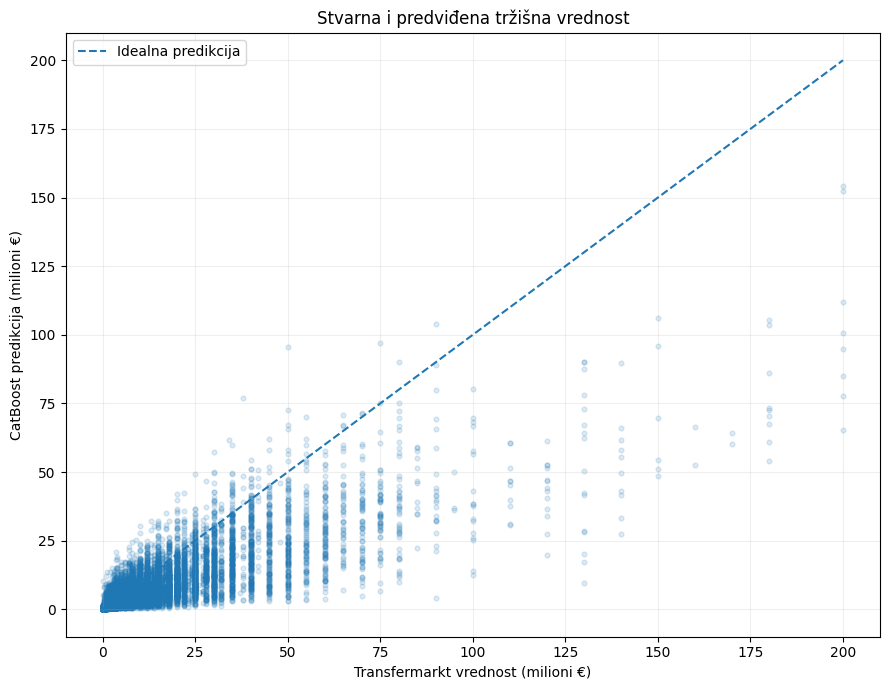

In [85]:
# STVARNA NASPRAM PREDVIĐENE VREDNOSTI

fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    diagnostics["actual_eur"] / 1_000_000,
    diagnostics["predicted_eur"] / 1_000_000,
    alpha=0.15,
    s=12
)

max_value = max(
    diagnostics["actual_eur"].max(),
    diagnostics["predicted_eur"].max()
) / 1_000_000

ax.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    linewidth=1.5,
    label="Idealna predikcija"
)

ax.set_xlabel("Transfermarkt vrednost (milioni €)")
ax.set_ylabel("CatBoost predikcija (milioni €)")
ax.set_title("Stvarna i predviđena tržišna vrednost")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


,value_segment,observations,median_prediction_ratio,median_log_ratio,share_overpredicted
0,Do 0.5m,1988,1.928,0.656,92.807
1,0.5m–2m,5610,1.281,0.248,66.132
2,2m–5m,4534,0.795,-0.230,38.906
3,5m–15m,4426,0.610,-0.494,21.306
4,15m–50m,3330,0.517,-0.661,9.760
5,50m+,675,0.439,-0.822,2.963


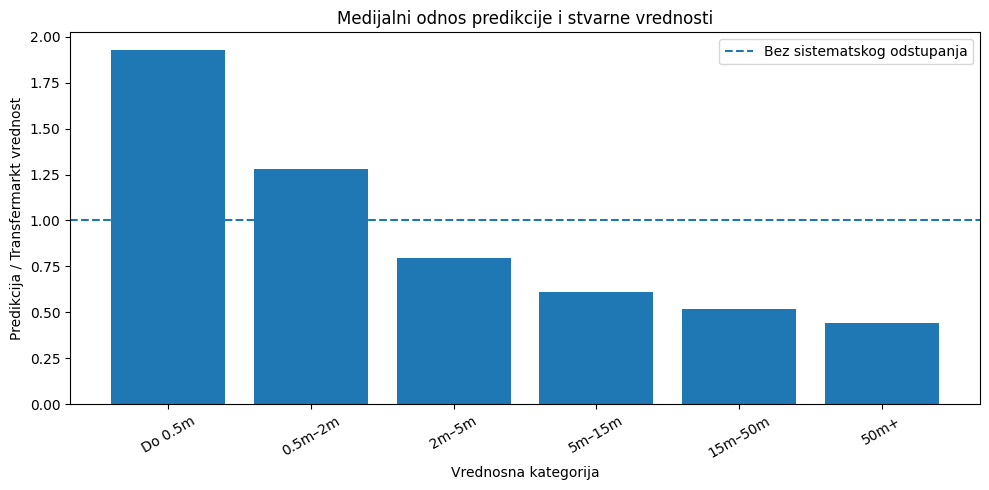

In [86]:
# ODNOS PREDIKCIJE I STVARNE VREDNOSTI

diagnostics["prediction_ratio"] = (
    diagnostics["predicted_eur"]
    / diagnostics["actual_eur"]
)

diagnostics["log_prediction_ratio"] = np.log(
    np.maximum(diagnostics["prediction_ratio"], 1e-12)
)

ratio_summary = (
    diagnostics
    .groupby("value_segment", observed=True)
    .agg(
        observations=("player_id", "size"),
        median_prediction_ratio=(
            "prediction_ratio", "median"
        ),
        median_log_ratio=(
            "log_prediction_ratio", "median"
        ),
        share_overpredicted=(
            "error_eur",
            lambda x: 100 * (x > 0).mean()
        )
    )
    .reset_index()
)

display(ratio_summary.round(3))

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    ratio_summary["value_segment"].astype(str),
    ratio_summary["median_prediction_ratio"]
)

ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1.5,
    label="Bez sistematskog odstupanja"
)

ax.set_title(
    "Medijalni odnos predikcije i stvarne vrednosti"
)
ax.set_ylabel("Predikcija / Transfermarkt vrednost")
ax.set_xlabel("Vrednosna kategorija")
ax.tick_params(axis="x", rotation=30)
ax.legend()

plt.tight_layout()
plt.show()


In [87]:
# KVALITET MODELA PO POZICIJAMA

position_metrics = (
    diagnostics
    .groupby("position", dropna=False)
    .agg(
        observations=("actual_eur", "size"),
        median_actual_eur=("actual_eur", "median"),
        MAE_EUR=("absolute_error_eur", "mean"),
        MAE_log1p=("absolute_log_error", "mean"),
        median_prediction_ratio=(
            "prediction_ratio", "median"
        )
    )
    .reset_index()
)

display(position_metrics.round(3))


,position,observations,median_actual_eur,MAE_EUR,MAE_log1p,median_prediction_ratio
0,Attack,5308,4000000.0,5588963.627,0.610,0.831
1,Defender,7522,2800000.0,3944287.999,0.659,0.850
2,Goalkeeper,1664,2000000.0,2768707.094,0.644,0.879
3,Midfield,6069,3500000.0,5070970.702,0.638,0.845


In [88]:
# REFERENTNI MODELI NA TEST SKUPU

# Trening podaci iz završnog eksperimenta
baseline_train = final_train.copy()

# Test podaci sa sačuvanim CatBoost predikcijama
baseline_test = diagnostics.copy()

# Medijana svih trening vrednosti
global_median = baseline_train[
    "market_value_in_eur"
].median()

baseline_test["global_median_pred"] = global_median

# Medijana po takmičenju iz trening skupa
league_medians = (
    baseline_train
    .groupby("competition_id")["market_value_in_eur"]
    .median()
)

# Dodajem competition_id test opažanjima
test_leagues = final_test[
    ["player_id", "valuation_date", "competition_id"]
].copy()

test_leagues["valuation_date"] = pd.to_datetime(
    test_leagues["valuation_date"]
)

baseline_test["valuation_date"] = pd.to_datetime(
    baseline_test["valuation_date"]
)

baseline_test = baseline_test.merge(
    test_leagues,
    on=["player_id", "valuation_date"],
    how="left",
    validate="one_to_one"
)

baseline_test["league_median_pred"] = (
    baseline_test["competition_id"]
    .map(league_medians)
    .fillna(global_median)
)

def evaluate_model(y_true, y_pred, name):
    return {
        "model": name,
        "MAE_EUR": mean_absolute_error(
            y_true, y_pred
        ),
        "RMSE_EUR": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred),
        "MAE_log1p": mean_absolute_error(
            np.log1p(y_true),
            np.log1p(y_pred)
        )
    }

baseline_comparison = pd.DataFrame([
    evaluate_model(
        baseline_test["actual_eur"],
        baseline_test["global_median_pred"],
        "Global median"
    ),
    evaluate_model(
        baseline_test["actual_eur"],
        baseline_test["league_median_pred"],
        "League median"
    ),
    evaluate_model(
        baseline_test["actual_eur"],
        baseline_test["predicted_eur"],
        "CatBoost"
    )
])

display(baseline_comparison.round(4))


,model,MAE_EUR,RMSE_EUR,R2,MAE_log1p
0,Global median,7.980690e+06,1.723969e+07,-0.1831,1.2589
1,League median,6.778635e+06,1.548264e+07,0.0457,0.9559
2,CatBoost,4.606235e+06,1.033303e+07,0.5750,0.6389


In [89]:
# DIJAGNOSTIKA NA VALIDACIJI 2022–2023

import numpy as np
import pandas as pd

# Proveravam postojeće promenljive
assert "catboost_model" in globals()
assert "exp_val" in globals()
assert "cat_all_features" in globals()

validation_data = exp_val.copy()

X_validation = validation_data[
    cat_all_features
].copy()

# Ista priprema kao pri treniranju CatBoost modela
for col in cat_features:
    X_validation[col] = (
        X_validation[col]
        .fillna("Unknown")
        .astype(str)
    )

for col in full_numeric:
    X_validation[col] = pd.to_numeric(
        X_validation[col],
        errors="coerce"
    )

validation_pred_log = catboost_model.predict(
    X_validation
)

validation_pred_eur = np.maximum(
    np.expm1(validation_pred_log),
    0
)

validation_diagnostics = pd.DataFrame({
    "actual_eur": validation_data[
        "market_value_in_eur"
    ].to_numpy(),
    "predicted_eur": validation_pred_eur
})

validation_diagnostics["prediction_ratio"] = (
    validation_diagnostics["predicted_eur"]
    / validation_diagnostics["actual_eur"]
)

validation_diagnostics["error_eur"] = (
    validation_diagnostics["predicted_eur"]
    - validation_diagnostics["actual_eur"]
)

bins = [
    0, 500_000, 2_000_000, 5_000_000,
    15_000_000, 50_000_000, np.inf
]

labels = [
    "Do 0.5m", "0.5m–2m", "2m–5m",
    "5m–15m", "15m–50m", "50m+"
]

validation_diagnostics["value_segment"] = pd.cut(
    validation_diagnostics["actual_eur"],
    bins=bins,
    labels=labels,
    right=False,
    include_lowest=True
)

validation_segment_results = (
    validation_diagnostics
    .groupby("value_segment", observed=True)
    .agg(
        observations=("actual_eur", "size"),
        median_prediction_ratio=(
            "prediction_ratio", "median"
        ),
        share_overpredicted=(
            "error_eur",
            lambda x: 100 * (x > 0).mean()
        ),
        MAE_EUR=(
            "error_eur",
            lambda x: x.abs().mean()
        )
    )
    .reset_index()
)

print("VALIDACIJA 2022–2023")
display(validation_segment_results.round(3))


VALIDACIJA 2022–2023


,value_segment,observations,median_prediction_ratio,share_overpredicted,MAE_EUR
0,Do 0.5m,2417,1.707,89.657,3.255280e+05
1,0.5m–2m,6108,1.346,69.581,7.019262e+05
2,2m–5m,4634,0.948,46.526,1.557512e+06
3,5m–15m,4303,0.669,24.890,3.654744e+06
4,15m–50m,2983,0.489,8.381,1.240188e+07
5,50m+,541,0.409,2.773,3.951072e+07


In [90]:
# VALIDACIJA NASPRAM TESTA

test_segment_comparison = (
    diagnostics
    .groupby("value_segment", observed=True)
    .agg(
        test_observations=("actual_eur", "size"),
        test_median_ratio=(
            "prediction_ratio", "median"
        )
    )
    .reset_index()
)

comparison_37 = validation_segment_results[
    [
        "value_segment",
        "observations",
        "median_prediction_ratio"
    ]
].rename(columns={
    "observations": "validation_observations",
    "median_prediction_ratio": "validation_median_ratio"
}).merge(
    test_segment_comparison,
    on="value_segment",
    how="outer"
)

display(comparison_37.round(3))


,value_segment,validation_observations,validation_median_ratio,test_observations,test_median_ratio
0,Do 0.5m,2417,1.707,1988,1.928
1,0.5m–2m,6108,1.346,5610,1.281
2,2m–5m,4634,0.948,4534,0.795
3,5m–15m,4303,0.669,4426,0.610
4,15m–50m,2983,0.489,3330,0.517
5,50m+,541,0.409,675,0.439


,prediction_decile,observations,median_predicted_eur,median_actual_eur,mean_predicted_eur,mean_actual_eur,median_ratio
0,1,2057,4.620530e+05,400000.0,4.386848e+05,7.188260e+05,1.155
1,2,2056,7.508457e+05,700000.0,7.500487e+05,1.286029e+06,1.073
2,3,2056,1.057529e+06,1000000.0,1.058920e+06,1.856214e+06,1.058
3,4,2056,1.438609e+06,1600000.0,1.450881e+06,2.526921e+06,0.899
4,5,2057,2.027400e+06,2500000.0,2.043662e+06,3.504266e+06,0.811
5,6,2056,2.966111e+06,3500000.0,2.990729e+06,5.119686e+06,0.847
6,7,2056,4.289142e+06,5000000.0,4.322805e+06,7.396680e+06,0.858
7,8,2056,6.347592e+06,8000000.0,6.405006e+06,1.093371e+07,0.793
8,9,2056,1.046411e+07,15000000.0,1.070075e+07,1.799189e+07,0.698
9,10,2057,2.248248e+07,35000000.0,2.711682e+07,4.048435e+07,0.642


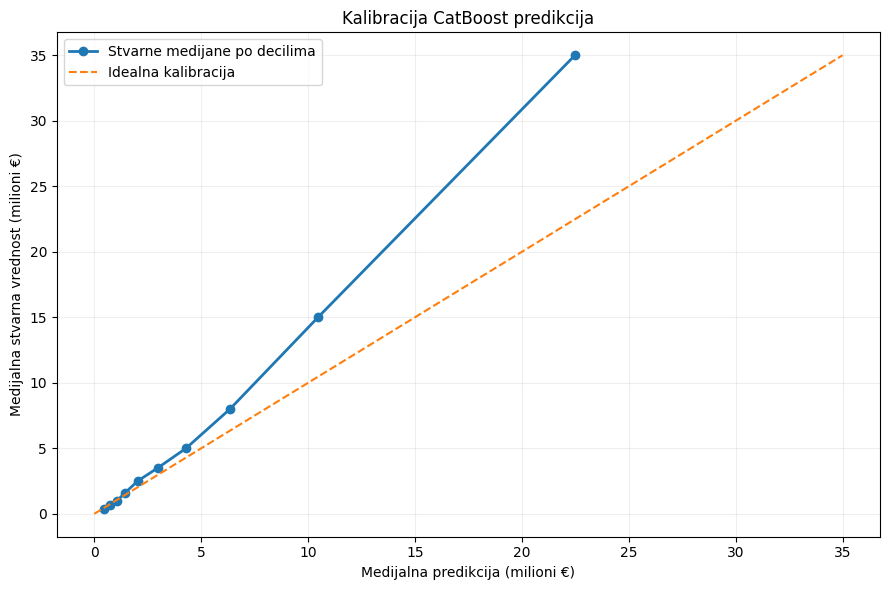

In [91]:
# KALIBRACIJA PREMA PREDVIĐENOJ VREDNOSTI

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

calibration = diagnostics.copy()

# Decili prema predikciji, ne prema stvarnoj vrednosti
calibration["prediction_decile"] = pd.qcut(
    calibration["predicted_eur"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1

calibration_summary = (
    calibration
    .groupby("prediction_decile")
    .agg(
        observations=("actual_eur", "size"),
        median_predicted_eur=("predicted_eur", "median"),
        median_actual_eur=("actual_eur", "median"),
        mean_predicted_eur=("predicted_eur", "mean"),
        mean_actual_eur=("actual_eur", "mean")
    )
    .reset_index()
)

calibration_summary["median_ratio"] = (
    calibration_summary["median_predicted_eur"]
    / calibration_summary["median_actual_eur"]
)

display(calibration_summary.round(3))

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    calibration_summary["median_predicted_eur"] / 1e6,
    calibration_summary["median_actual_eur"] / 1e6,
    marker="o",
    linewidth=2,
    label="Stvarne medijane po decilima"
)

max_val = max(
    calibration_summary["median_predicted_eur"].max(),
    calibration_summary["median_actual_eur"].max()
) / 1e6

ax.plot(
    [0, max_val],
    [0, max_val],
    linestyle="--",
    label="Idealna kalibracija"
)

ax.set_xlabel("Medijalna predikcija (milioni €)")
ax.set_ylabel("Medijalna stvarna vrednost (milioni €)")
ax.set_title("Kalibracija CatBoost predikcija")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()


In [92]:
import numpy as np
import pandas as pd

# Učitavam podatke iz postojeće DuckDB tabele
calibration_source = con.execute("""
    SELECT *
    FROM modeling_split
    WHERE eligible_performance_model = 1
      AND valuation_date >= '2014-01-01'
      AND valuation_date < '2024-01-01'
""").df()

calibration_source["valuation_date"] = pd.to_datetime(
    calibration_source["valuation_date"]
)

calibration_source["year"] = (
    calibration_source["valuation_date"].dt.year
)

# Provera da li imam sve karakteristike
required_columns = (
    ["valuation_date", "market_value_in_eur"]
    + cat_all_features
)

missing = [
    col for col in required_columns
    if col not in calibration_source.columns
]

if missing:
    raise ValueError(
        f"Nedostaju kolone: {missing}"
    )

# Vremenska podela
train_2014_2021 = calibration_source[
    calibration_source["year"].between(2014, 2021)
].copy()

calibrate_2022 = calibration_source[
    calibration_source["year"] == 2022
].copy()

validate_2023 = calibration_source[
    calibration_source["year"] == 2023
].copy()

print("Trening 2014–2021:", len(train_2014_2021))
print("Kalibracija 2022:", len(calibrate_2022))
print("Validacija 2023:", len(validate_2023))

print(
    "Ukupno:",
    len(train_2014_2021)
    + len(calibrate_2022)
    + len(validate_2023)
)


Trening 2014–2021: 75904
Kalibracija 2022: 10501
Validacija 2023: 10485
Ukupno: 96890


In [93]:
# CATBOOST TRENIRAN SAMO NA 2014–2021

from catboost import CatBoostRegressor

def prepare_catboost_features(df):
    X = df[cat_all_features].copy()

    for col in cat_features:
        X[col] = X[col].fillna("Unknown").astype(str)

    for col in full_numeric:
        X[col] = pd.to_numeric(
            X[col],
            errors="coerce"
        )

    return X

X_train_early = prepare_catboost_features(
    train_2014_2021
)

y_train_early = np.log1p(
    train_2014_2021["market_value_in_eur"]
)

calibration_base_model = CatBoostRegressor(
    iterations=1156,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    l2_leaf_reg=5,
    random_seed=42,
    verbose=200,
    thread_count=2
)

calibration_base_model.fit(
    X_train_early,
    y_train_early,
    cat_features=cat_features
)

print("Osnovni model treniran.")


0:	learn: 1.3701427	total: 77.3ms	remaining: 1m 29s
200:	learn: 0.7869829	total: 14.4s	remaining: 1m 8s
400:	learn: 0.7689260	total: 34.8s	remaining: 1m 5s
600:	learn: 0.7563611	total: 47.2s	remaining: 43.6s
800:	learn: 0.7472270	total: 57.3s	remaining: 25.4s
1000:	learn: 0.7396581	total: 1m 9s	remaining: 10.7s
1155:	learn: 0.7348108	total: 1m 19s	remaining: 0us
Osnovni model treniran.


In [94]:
# KALIBRACIJA NA 2022

from sklearn.linear_model import LinearRegression

X_cal_2022 = prepare_catboost_features(
    calibrate_2022
)

pred_log_2022 = calibration_base_model.predict(
    X_cal_2022
)

actual_log_2022 = np.log1p(
    calibrate_2022["market_value_in_eur"].to_numpy()
)

linear_calibrator = LinearRegression()

linear_calibrator.fit(
    pred_log_2022.reshape(-1, 1),
    actual_log_2022
)

print(
    "Intercept:",
    round(linear_calibrator.intercept_, 4)
)
print(
    "Slope:",
    round(linear_calibrator.coef_[0], 4)
)


Intercept: -0.7306
Slope: 1.0545


In [95]:
# POREĐENJE NA 2023

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

X_val_2023 = prepare_catboost_features(
    validate_2023
)

actual_2023 = validate_2023[
    "market_value_in_eur"
].to_numpy()

raw_log_2023 = calibration_base_model.predict(
    X_val_2023
)

raw_pred_2023 = np.maximum(
    np.expm1(raw_log_2023), 0
)

calibrated_log_2023 = linear_calibrator.predict(
    raw_log_2023.reshape(-1, 1)
)

calibrated_pred_2023 = np.maximum(
    np.expm1(calibrated_log_2023), 0
)

def model_metrics(name, actual, predicted):
    return {
        "model": name,
        "MAE_EUR": mean_absolute_error(
            actual, predicted
        ),
        "RMSE_EUR": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted),
        "MAE_log1p": mean_absolute_error(
            np.log1p(actual),
            np.log1p(predicted)
        )
    }

calibration_comparison = pd.DataFrame([
    model_metrics(
        "CatBoost original",
        actual_2023,
        raw_pred_2023
    ),
    model_metrics(
        "CatBoost calibrated",
        actual_2023,
        calibrated_pred_2023
    )
])

display(calibration_comparison.round(4))

mae_raw = calibration_comparison.loc[
    0, "MAE_EUR"
]

mae_cal = calibration_comparison.loc[
    1, "MAE_EUR"
]

print(
    "Promena MAE (%):",
    round(100 * (mae_cal / mae_raw - 1), 2)
)


,model,MAE_EUR,RMSE_EUR,R2,MAE_log1p
0,CatBoost original,4.456067e+06,1.006585e+07,0.5143,0.6325
1,CatBoost calibrated,4.187322e+06,9.168210e+06,0.5971,0.6184


Promena MAE (%): -6.03


In [96]:
# POBOLJŠANJE PO VREDNOSNIM SEGMENTIMA

segment_check = pd.DataFrame({
    "actual_eur": actual_2023,
    "raw_pred_eur": raw_pred_2023,
    "calibrated_pred_eur": calibrated_pred_2023
})

segment_check["value_segment"] = pd.cut(
    segment_check["actual_eur"],
    bins=[
        0, 500_000, 2_000_000, 5_000_000,
        15_000_000, 50_000_000, np.inf
    ],
    labels=[
        "Do 0.5m", "0.5m–2m", "2m–5m",
        "5m–15m", "15m–50m", "50m+"
    ],
    right=False
)

segment_check["raw_abs_error"] = (
    segment_check["raw_pred_eur"]
    - segment_check["actual_eur"]
).abs()

segment_check["cal_abs_error"] = (
    segment_check["calibrated_pred_eur"]
    - segment_check["actual_eur"]
).abs()

segment_check["raw_log_error"] = np.abs(
    np.log1p(segment_check["raw_pred_eur"])
    - np.log1p(segment_check["actual_eur"])
)

segment_check["cal_log_error"] = np.abs(
    np.log1p(segment_check["calibrated_pred_eur"])
    - np.log1p(segment_check["actual_eur"])
)

segment_comparison = (
    segment_check
    .groupby("value_segment", observed=True)
    .agg(
        players=("actual_eur", "size"),
        raw_MAE=("raw_abs_error", "mean"),
        calibrated_MAE=("cal_abs_error", "mean"),
        raw_log_MAE=("raw_log_error", "mean"),
        calibrated_log_MAE=("cal_log_error", "mean")
    )
    .reset_index()
)

segment_comparison["MAE_improvement_pct"] = (
    100 * (
        1
        - segment_comparison["calibrated_MAE"]
        / segment_comparison["raw_MAE"]
    )
)

segment_comparison["log_MAE_improvement_pct"] = (
    100 * (
        1
        - segment_comparison["calibrated_log_MAE"]
        / segment_comparison["raw_log_MAE"]
    )
)

display(segment_comparison.round(3))


,value_segment,players,raw_MAE,calibrated_MAE,raw_log_MAE,calibrated_log_MAE,MAE_improvement_pct,log_MAE_improvement_pct
0,Do 0.5m,1208,3.295558e+05,3.380945e+05,0.625,0.626,-2.591,-0.041
1,0.5m–2m,2918,6.919514e+05,7.673214e+05,0.534,0.565,-10.892,-5.899
2,2m–5m,2271,1.524135e+06,1.728307e+06,0.544,0.568,-13.396,-4.310
3,5m–15m,2248,3.654781e+06,3.711363e+06,0.649,0.618,-1.548,4.678
4,15m–50m,1551,1.315398e+07,1.192712e+07,0.859,0.747,9.327,13.003
5,50m+,289,4.230299e+07,3.629589e+07,1.014,0.832,14.200,17.951


In [97]:
# PROFIL ISTORIJSKOG SKUPA PODATAKA

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

eda = con.execute("""
    SELECT
        player_id,
        valuation_date,
        market_value_in_eur,
        age_at_valuation,
        position,
        competition_id,
        eligible_performance_model,
        minutes_365d,
        goals_365d,
        assists_365d
    FROM modeling_split
    WHERE market_value_in_eur > 0
""").df()

eda["valuation_date"] = pd.to_datetime(
    eda["valuation_date"]
)

eda["year"] = eda["valuation_date"].dt.year

eda["value_million_eur"] = (
    eda["market_value_in_eur"] / 1_000_000
)

eda["log_market_value"] = np.log1p(
    eda["market_value_in_eur"]
)

print("Broj procena:", len(eda))
print("Broj jedinstvenih igrača:", eda["player_id"].nunique())
print(
    "Vremenski period:",
    eda["valuation_date"].min(),
    "do",
    eda["valuation_date"].max()
)

print("\nRaspodela tržišnih vrednosti:")
display(
    eda["market_value_in_eur"].describe(
        percentiles=[
            0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99
        ]
    ).to_frame("EUR")
)

print("\nPokrivenost prethodnim nastupima:")
display(
    eda.groupby("eligible_performance_model")
    .agg(
        observations=("player_id", "size"),
        unique_players=("player_id", "nunique"),
        median_value_eur=(
            "market_value_in_eur", "median"
        )
    )
)

Broj procena: 527106
Broj jedinstvenih igrača: 40408
Vremenski period: 2014-01-01 00:00:00 do 2025-12-31 00:00:00

Raspodela tržišnih vrednosti:


,EUR
count,5.271060e+05
mean,2.277399e+06
std,6.975717e+06
min,1.000000e+04
10%,1.000000e+05
25%,2.000000e+05
50%,4.500000e+05
75%,1.500000e+06
90%,5.000000e+06
95%,1.000000e+07



Pokrivenost prethodnim nastupima:


,observations,unique_players,median_value_eur
eligible_performance_model,,,
0,409653,39997,325000.0
1,117453,15216,2500000.0


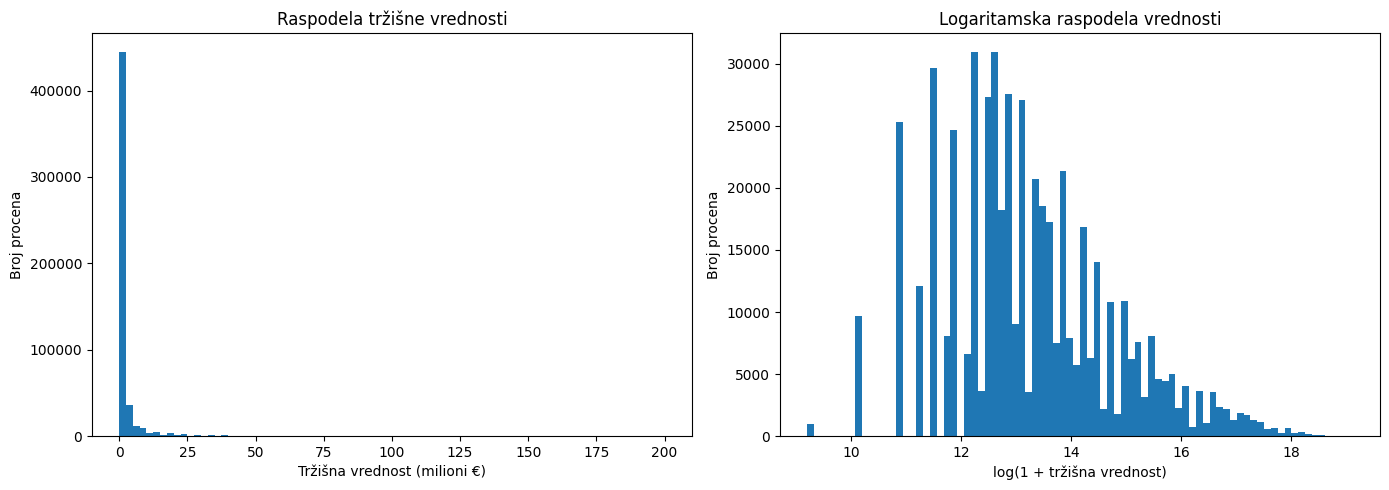

In [98]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    eda["value_million_eur"],
    bins=80
)

axes[0].set_title("Raspodela tržišne vrednosti")
axes[0].set_xlabel("Tržišna vrednost (milioni €)")
axes[0].set_ylabel("Broj procena")

axes[1].hist(
    eda["log_market_value"],
    bins=80
)

axes[1].set_title("Logaritamska raspodela vrednosti")
axes[1].set_xlabel("log(1 + tržišna vrednost)")
axes[1].set_ylabel("Broj procena")

plt.tight_layout()
plt.show()


,year,observations,unique_players,median_value_eur,mean_value_eur
0,2014,23707,13904,500000.0,1792280.97
1,2015,30479,16473,500000.0,1697561.60
2,2016,34653,17794,425000.0,1732431.39
3,2017,35923,19155,400000.0,1836578.24
4,2018,41097,20162,450000.0,2658393.68
5,2019,46088,22116,400000.0,2327907.92
6,2020,48749,22807,475000.0,2298331.15
7,2021,58412,25650,400000.0,2206414.69
8,2022,59564,26848,400000.0,1970480.16
9,2023,57576,27890,400000.0,2259024.85


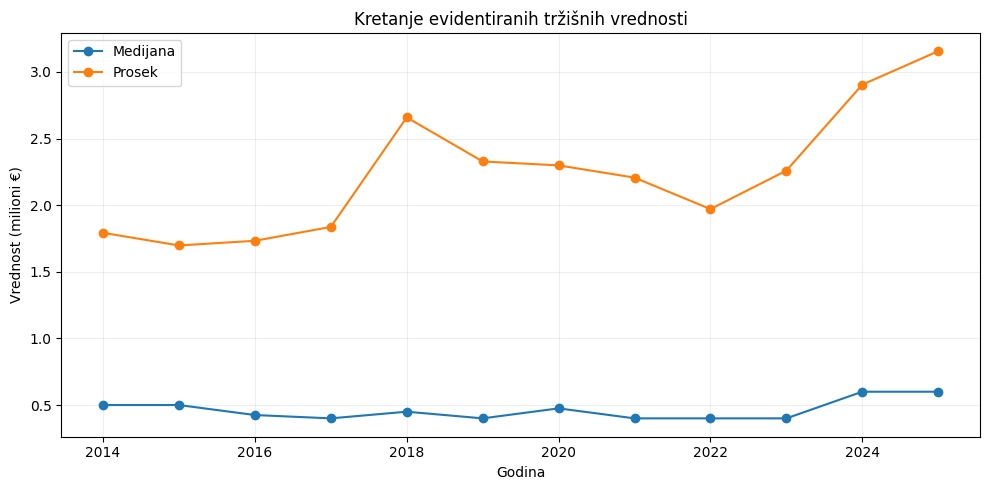

In [99]:

yearly_summary = (
    eda.groupby("year")
    .agg(
        observations=("player_id", "size"),
        unique_players=("player_id", "nunique"),
        median_value_eur=(
            "market_value_in_eur", "median"
        ),
        mean_value_eur=(
            "market_value_in_eur", "mean"
        )
    )
    .reset_index()
)

display(yearly_summary.round(2))

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    yearly_summary["year"],
    yearly_summary["median_value_eur"] / 1e6,
    marker="o",
    label="Medijana"
)

ax.plot(
    yearly_summary["year"],
    yearly_summary["mean_value_eur"] / 1e6,
    marker="o",
    label="Prosek"
)

ax.set_title("Kretanje evidentiranih tržišnih vrednosti")
ax.set_xlabel("Godina")
ax.set_ylabel("Vrednost (milioni €)")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


,age,observations,unique_players,median_value_eur,mean_value_eur,p75_value_eur
0,16,921,887,75000.0,446943.54,200000.0
1,17,3887,3651,100000.0,727078.72,225000.0
2,18,8974,8565,100000.0,770587.81,300000.0
3,19,15119,14299,150000.0,945821.15,400000.0
4,20,18492,17402,200000.0,1201595.83,550000.0
5,21,19576,18490,300000.0,1563895.59,800000.0
6,22,19944,18765,350000.0,2015975.48,1000000.0
7,23,19462,18408,400000.0,2254162.98,1200000.0
8,24,18955,17819,500000.0,2443187.81,1500000.0
9,25,17977,16938,525000.0,2634696.83,1500000.0


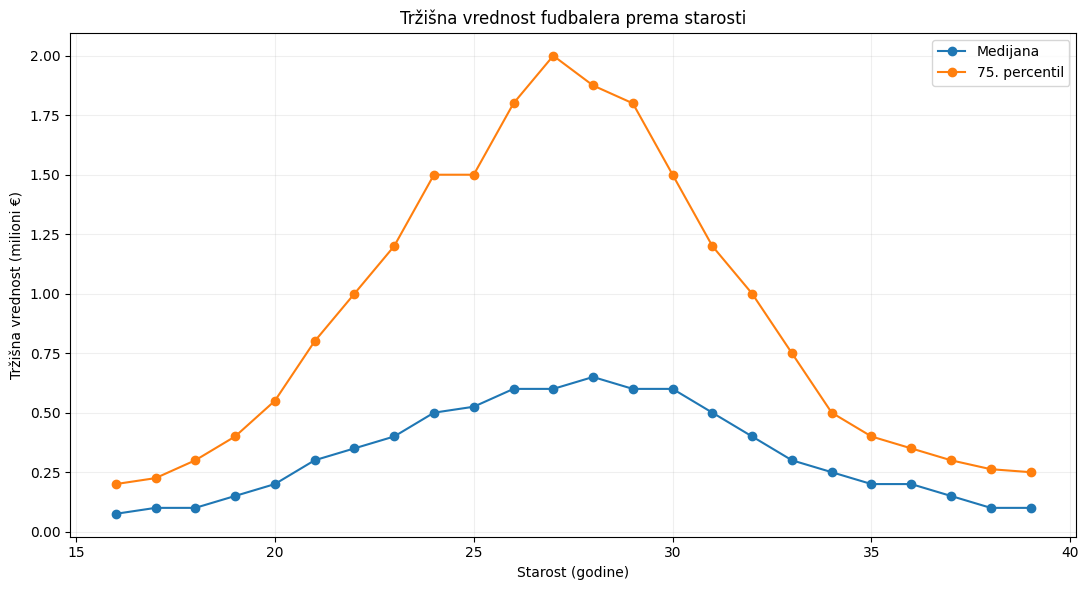

Broj opažanja u analizi: 250863


In [100]:
# STAROST I TRŽIŠNA VREDNOST

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Polazim od već pripremljenog EDA skupa
eda_annual = (
    eda.sort_values("valuation_date")
       .drop_duplicates(
           subset=["player_id", "year"],
           keep="last"
       )
       .copy()
)

# Ograničavam analizu na uzrast 16–40 godina
age_data = eda_annual[
    eda_annual["age_at_valuation"].between(16, 40)
].copy()

age_data["age"] = (
    np.floor(age_data["age_at_valuation"]).astype(int)
)

age_summary = (
    age_data.groupby("age")
    .agg(
        observations=("player_id", "size"),
        unique_players=("player_id", "nunique"),
        median_value_eur=(
            "market_value_in_eur", "median"
        ),
        mean_value_eur=(
            "market_value_in_eur", "mean"
        ),
        p75_value_eur=(
            "market_value_in_eur",
            lambda x: x.quantile(0.75)
        )
    )
    .reset_index()
)

display(age_summary.round(2))

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    age_summary["age"],
    age_summary["median_value_eur"] / 1e6,
    marker="o",
    label="Medijana"
)

ax.plot(
    age_summary["age"],
    age_summary["p75_value_eur"] / 1e6,
    marker="o",
    label="75. percentil"
)

ax.set_title(
    "Tržišna vrednost fudbalera prema starosti"
)
ax.set_xlabel("Starost (godine)")
ax.set_ylabel("Tržišna vrednost (milioni €)")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print(
    "Broj opažanja u analizi:",
    len(age_data)
)

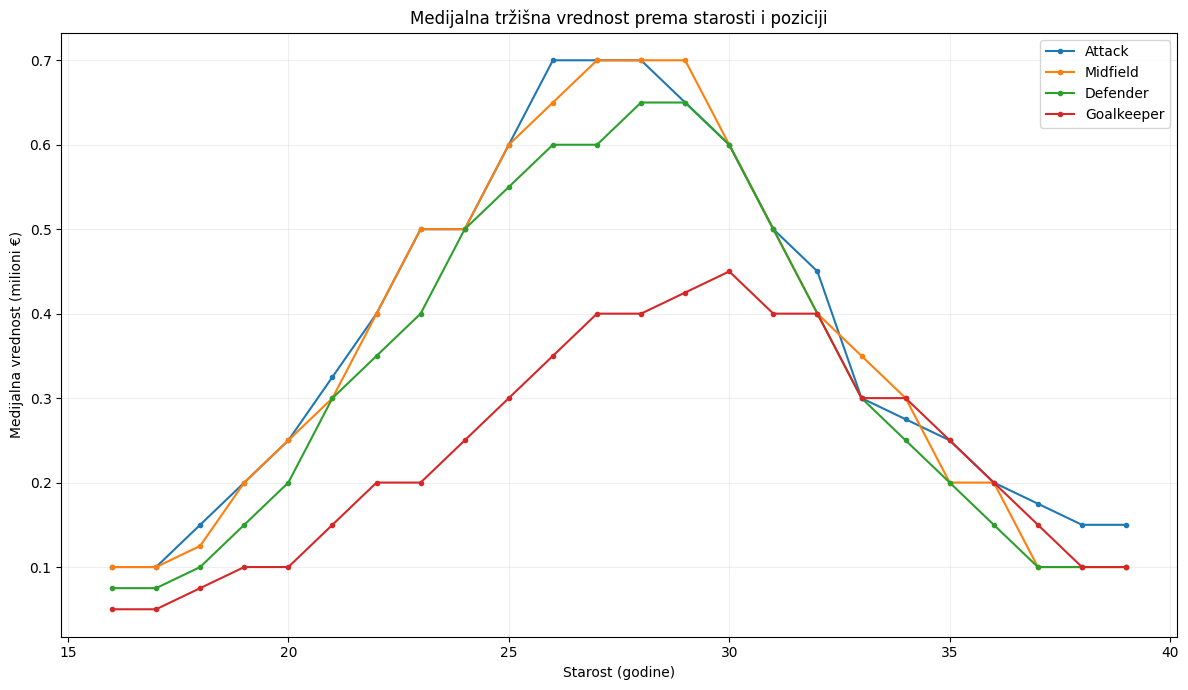

Medijalne vrednosti u milionima evra:


age_group,16–20,21–24,25–28,29–32,33–40
position,,,,,
Attack,0.20,0.4,0.65,0.55,0.25
Defender,0.15,0.4,0.60,0.50,0.25
Goalkeeper,0.10,0.2,0.35,0.40,0.25
Midfield,0.20,0.4,0.65,0.60,0.25


In [101]:
# STAROST PO POZICIJAMA

valid_positions = [
    "Attack", "Midfield", "Defender", "Goalkeeper"
]

position_age_data = age_data[
    age_data["position"].isin(valid_positions)
].copy()

age_position_summary = (
    position_age_data
    .groupby(["position", "age"])
    .agg(
        observations=("player_id", "size"),
        median_value_eur=(
            "market_value_in_eur", "median"
        )
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 7))

for position in valid_positions:
    subset = age_position_summary[
        (age_position_summary["position"] == position)
        & (age_position_summary["observations"] >= 30)
    ]

    ax.plot(
        subset["age"],
        subset["median_value_eur"] / 1e6,
        marker="o",
        markersize=3,
        label=position
    )

ax.set_title(
    "Medijalna tržišna vrednost prema starosti i poziciji"
)
ax.set_xlabel("Starost (godine)")
ax.set_ylabel("Medijalna vrednost (milioni €)")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Pregled po širim starosnim grupama
position_age_data["age_group"] = pd.cut(
    position_age_data["age_at_valuation"],
    bins=[16, 21, 25, 29, 33, 41],
    labels=[
        "16–20", "21–24", "25–28",
        "29–32", "33–40"
    ],
    right=False
)

age_position_table = (
    position_age_data
    .groupby(
        ["position", "age_group"],
        observed=True
    )["market_value_in_eur"]
    .median()
    .unstack()
    / 1e6
)

print("Medijalne vrednosti u milionima evra:")
display(age_position_table.round(3))


In [102]:
# VREDNOSTI PO LIGAMA

league_data = eda_annual.copy()

league_data["competition_id"] = (
    league_data["competition_id"]
    .fillna("UNKNOWN")
    .astype(str)
)

league_summary_eda = (
    league_data
    .groupby("competition_id")
    .agg(
        observations=("player_id", "size"),
        unique_players=("player_id", "nunique"),
        median_value_eur=(
            "market_value_in_eur", "median"
        ),
        mean_value_eur=(
            "market_value_in_eur", "mean"
        ),
        p75_value_eur=(
            "market_value_in_eur",
            lambda x: x.quantile(0.75)
        ),
        share_above_5m=(
            "market_value_in_eur",
            lambda x: 100 * (x >= 5_000_000).mean()
        )
    )
    .reset_index()
)

# Zadržavam lige sa dovoljno istorijskih opažanja
league_summary_eda = league_summary_eda[
    league_summary_eda["observations"] >= 500
].sort_values(
    "median_value_eur",
    ascending=False
)

display(
    league_summary_eda.head(20).round(2)
)


,competition_id,observations,unique_players,median_value_eur,mean_value_eur,p75_value_eur,share_above_5m
10,GB1,11943,2742,2500000.0,8812897.09,10000000.0,38.06
16,MEX1,2313,627,1500000.0,2279420.67,3000000.0,11.67
4,BRA1,3596,1066,1500000.0,2841903.50,3500000.0,17.58
17,MLS1,3656,1091,1000000.0,1930169.58,2000000.0,7.93
8,ES1,12813,2535,900000.0,4590086.63,3000000.0,19.20
1,ARG1,3835,1089,800000.0,1641975.23,2000000.0,7.25
9,FR1,11604,2810,800000.0,3238959.41,2500000.0,16.29
15,L1,12105,2446,800000.0,3984759.19,3000000.0,19.08
5,C1,1793,592,700000.0,1221441.72,1500000.0,3.74
0,A1,1782,583,575000.0,1507104.38,1500000.0,6.00


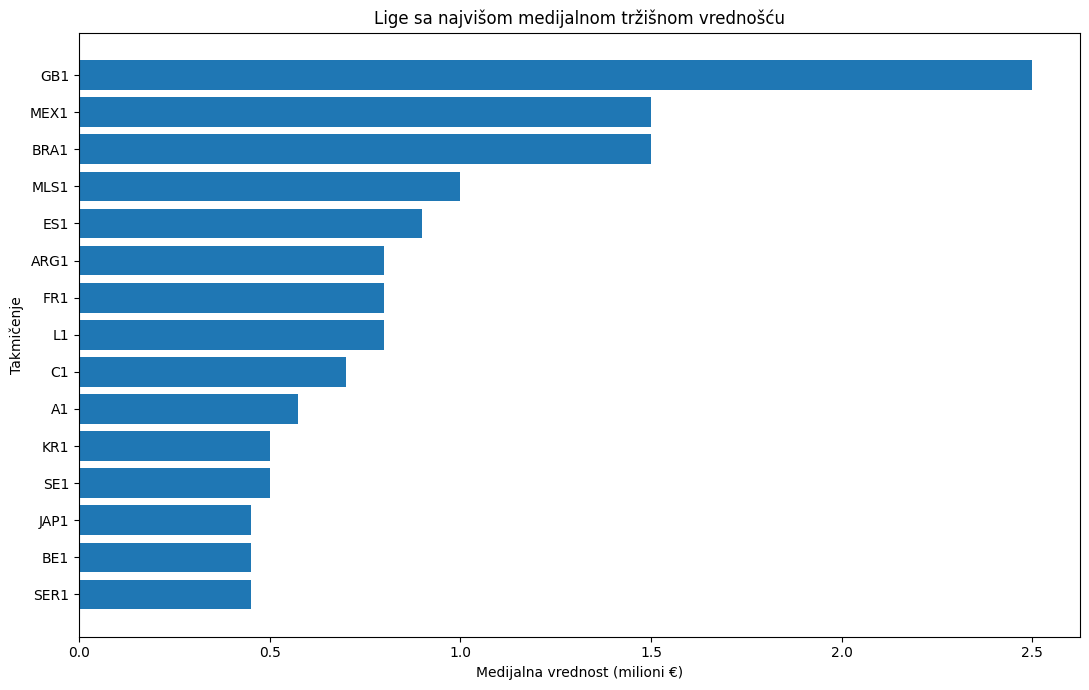

In [103]:
# GRAFIK MEDIJALNIH VREDNOSTI

top_leagues = league_summary_eda.head(15).copy()

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    top_leagues["competition_id"],
    top_leagues["median_value_eur"] / 1e6
)

ax.invert_yaxis()

ax.set_title(
    "Lige sa najvišom medijalnom tržišnom vrednošću"
)
ax.set_xlabel("Medijalna vrednost (milioni €)")
ax.set_ylabel("Takmičenje")

plt.tight_layout()
plt.show()


In [104]:
# STAROST I VREDNOST PO LIGAMA

league_age_summary = (
    league_data
    .groupby("competition_id")
    .agg(
        observations=("player_id", "size"),
        median_age=("age_at_valuation", "median"),
        median_value_eur=(
            "market_value_in_eur", "median"
        )
    )
    .reset_index()
)

league_age_summary = league_age_summary[
    league_age_summary["observations"] >= 500
].sort_values(
    "median_value_eur",
    ascending=False
)

display(
    league_age_summary.head(20).round(2)
)


,competition_id,observations,median_age,median_value_eur
10,GB1,11943,26.40,2500000.0
16,MEX1,2313,25.68,1500000.0
4,BRA1,3596,25.14,1500000.0
17,MLS1,3656,25.00,1000000.0
8,ES1,12813,26.92,900000.0
1,ARG1,3835,24.77,800000.0
9,FR1,11604,25.62,800000.0
15,L1,12105,25.50,800000.0
5,C1,1793,23.44,700000.0
0,A1,1782,22.97,575000.0


In [105]:
# PROVERA ISTORIJSKE PRIPADNOSTI LIGI

league_audit = con.execute("""
    SELECT
        m.competition_id AS model_league,
        v.player_club_domestic_competition_id
            AS historical_league,
        COUNT(*) AS observations
    FROM modeling_split m
    LEFT JOIN player_valuations v
        ON m.player_id = v.player_id
       AND CAST(m.valuation_date AS DATE)
           = CAST(v.date AS DATE)
    GROUP BY 1, 2
    ORDER BY observations DESC
""").df()

total = league_audit["observations"].sum()

matched = league_audit.loc[
    league_audit["model_league"].fillna("MISSING")
    == league_audit["historical_league"].fillna("MISSING"),
    "observations"
].sum()

print("Ukupno spojenih redova:", total)
print("Udeo poklapanja liga:", round(100 * matched / total, 2), "%")

print("\nNajčešća nepoklapanja:")
display(
    league_audit[
        league_audit["model_league"].fillna("MISSING")
        != league_audit["historical_league"].fillna("MISSING")
    ].head(20)
)


Ukupno spojenih redova: 527106
Udeo poklapanja liga: 83.71 %

Najčešća nepoklapanja:


,model_league,historical_league,observations
0,UNKNOWN,None,85886


Spearmanova korelacija sa logaritmom tržišne vrednosti:


,spearman_correlation
minutes_365d,0.382
assists_365d,0.321
goals_365d,0.303


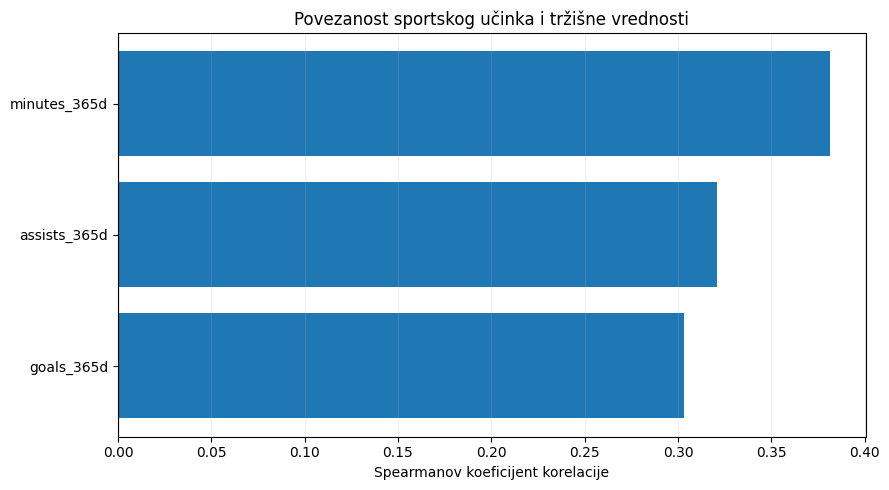

In [106]:
# SPORTSKI UČINAK I TRŽIŠNA VREDNOST

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

performance_eda = eda[
    eda["eligible_performance_model"] == 1
].copy()

performance_eda = (
    performance_eda
    .sort_values("valuation_date")
    .drop_duplicates(
        subset=["player_id", "year"],
        keep="last"
    )
    .copy()
)

performance_eda["log_value"] = np.log1p(
    performance_eda["market_value_in_eur"]
)

performance_columns = [
    "minutes_365d",
    "goals_365d",
    "assists_365d"
]

correlations = (
    performance_eda[
        performance_columns + ["log_value"]
    ]
    .corr(method="spearman")["log_value"]
    .drop("log_value")
    .sort_values(ascending=False)
)

print("Spearmanova korelacija sa logaritmom tržišne vrednosti:")
display(
    correlations.to_frame("spearman_correlation").round(3)
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    correlations.index[::-1],
    correlations.values[::-1]
)

ax.set_title(
    "Povezanost sportskog učinka i tržišne vrednosti"
)
ax.set_xlabel("Spearmanov koeficijent korelacije")
ax.axvline(0, color="black", linewidth=0.8)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


,minutes_group,observations,median_value_eur,mean_value_eur
0,900–1499,22162,1000000.0,2867550.31
1,1500–1999,12446,1500000.0,4046000.72
2,2000–2499,9046,2500000.0,6036220.43
3,2500–2999,6924,3500000.0,8707770.08
4,3000+,6088,10000000.0,18658730.29


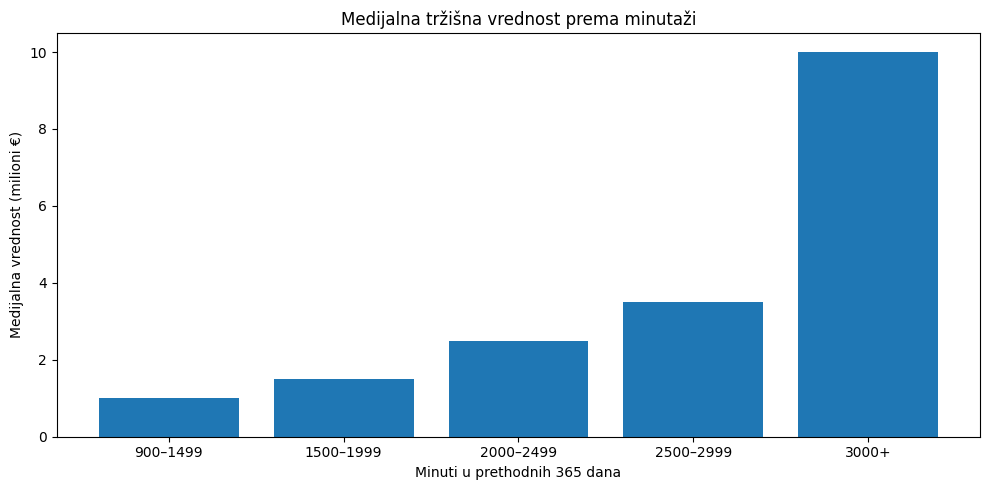

In [107]:
# MINUTAŽA I TRŽIŠNA VREDNOST

performance_eda["minutes_group"] = pd.cut(
    performance_eda["minutes_365d"],
    bins=[900, 1500, 2000, 2500, 3000, np.inf],
    labels=[
        "900–1499",
        "1500–1999",
        "2000–2499",
        "2500–2999",
        "3000+"
    ],
    right=False
)

minutes_summary = (
    performance_eda
    .groupby("minutes_group", observed=True)
    .agg(
        observations=("player_id", "size"),
        median_value_eur=(
            "market_value_in_eur", "median"
        ),
        mean_value_eur=(
            "market_value_in_eur", "mean"
        )
    )
    .reset_index()
)

display(minutes_summary.round(2))

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    minutes_summary["minutes_group"].astype(str),
    minutes_summary["median_value_eur"] / 1e6
)

ax.set_title(
    "Medijalna tržišna vrednost prema minutaži"
)
ax.set_xlabel("Minuti u prethodnih 365 dana")
ax.set_ylabel("Medijalna vrednost (milioni €)")

plt.tight_layout()
plt.show()


In [108]:
# UČINAK PREMA POZICIJAMA

performance_position_summary = (
    performance_eda
    .groupby("position")
    .agg(
        observations=("player_id", "size"),
        median_minutes=("minutes_365d", "median"),
        median_goals=("goals_365d", "median"),
        median_assists=("assists_365d", "median"),
        median_value_eur=(
            "market_value_in_eur", "median"
        )
    )
    .sort_values(
        "median_value_eur",
        ascending=False
    )
)

display(performance_position_summary.round(2))

position_correlations = []

for position, group in performance_eda.groupby("position"):
    if len(group) < 100:
        continue

    for feature in performance_columns:
        corr = group[
            [feature, "log_value"]
        ].corr(method="spearman").iloc[0, 1]

        position_correlations.append({
            "position": position,
            "feature": feature,
            "spearman": corr,
            "observations": len(group)
        })

position_corr_df = pd.DataFrame(
    position_correlations
)

display(
    position_corr_df.pivot(
        index="position",
        columns="feature",
        values="spearman"
    ).round(3)
)


,observations,median_minutes,median_goals,median_assists,median_value_eur
position,,,,,
Attack,13904,1584.5,5.0,3.0,2500000.0
Midfield,16804,1726.5,2.0,2.0,2000000.0
Defender,21250,1795.0,1.0,1.0,1500000.0
Goalkeeper,4672,1918.5,0.0,0.0,1200000.0
Unknown,36,1433.0,2.0,3.0,1000000.0


feature,assists_365d,goals_365d,minutes_365d
position,,,
Attack,0.423,0.457,0.413
Defender,0.229,0.228,0.383
Goalkeeper,0.064,0.007,0.465
Midfield,0.344,0.321,0.402


,feature,mean_abs_shap
16,competition_id,0.6414
0,age_at_valuation,0.3038
6,matches_365d,0.2565
8,goals_365d,0.1259
9,assists_365d,0.1080
7,minutes_365d,0.1002
14,position,0.0782
12,goals_per90_365d,0.0663
2,matches_90d,0.0533
1,height_in_cm,0.0518


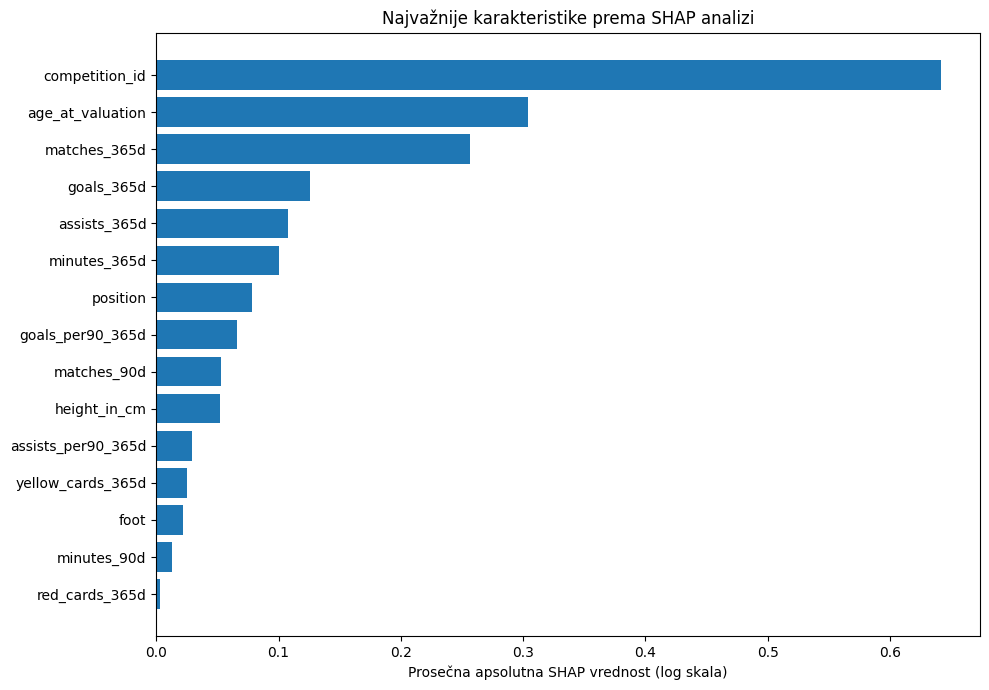

Najveća razlika pri rekonstrukciji predikcije: 1.0658141036401503e-14


In [109]:
# GLOBALNA SHAP ANALIZA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import Pool

# Test podaci iz istorijske DuckDB tabele
shap_source = con.execute("""
    SELECT *
    FROM modeling_split
    WHERE eligible_performance_model = 1
      AND valuation_date >= '2024-01-01'
      AND valuation_date < '2026-01-01'
""").df()

# Reproduktivno uzorkovanje
shap_sample = shap_source.sample(
    n=min(1000, len(shap_source)),
    random_state=42
).copy()

# Ista priprema karakteristika kao tokom treniranja
X_shap = prepare_catboost_features(shap_sample)

shap_pool = Pool(
    X_shap,
    cat_features=cat_features
)

# Poslednja kolona predstavlja osnovnu SHAP vrednost
shap_values = final_catboost.get_feature_importance(
    shap_pool,
    type="ShapValues"
)

feature_shap = shap_values[:, :-1]
base_values = shap_values[:, -1]

shap_importance = pd.DataFrame({
    "feature": X_shap.columns,
    "mean_abs_shap": np.abs(feature_shap).mean(axis=0)
}).sort_values(
    "mean_abs_shap",
    ascending=False
)

display(shap_importance.round(4))

top_shap = shap_importance.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_shap["feature"],
    top_shap["mean_abs_shap"]
)

ax.set_title(
    "Najvažnije karakteristike prema SHAP analizi"
)
ax.set_xlabel(
    "Prosečna apsolutna SHAP vrednost (log skala)"
)

plt.tight_layout()
plt.show()

# Provera SHAP aditivnosti
model_log_pred = final_catboost.predict(X_shap)

reconstructed_log_pred = (
    base_values + feature_shap.sum(axis=1)
)

print(
    "Najveća razlika pri rekonstrukciji predikcije:",
    np.max(
        np.abs(
            model_log_pred - reconstructed_log_pred
        )
    )
)


In [110]:
# PROVERA PODATAKA ZA STUDIJE SLUČAJA

for name in [
    "player_cohort",
    "cohort_with_outcome",
    "test_analysis",
    "adjusted_candidates"
]:
    obj = globals().get(name)

    if isinstance(obj, pd.DataFrame):
        print(f"\n{name}: {len(obj)} redova")
        print("Kolone:")
        print(obj.columns.tolist())
    else:
        print(f"\n{name}: nije dostupan kao DataFrame")



player_cohort: 4961 redova
Kolone:
['player_id', 'valuation_date', 'position', 'initial_value_eur', 'predicted_eur', 'residual_eur', 'residual_ratio', 'future_date', 'future_value_eur', 'days_to_future', 'future_return']

cohort_with_outcome: 3586 redova
Kolone:
['player_id', 'valuation_date', 'position', 'initial_value_eur', 'predicted_eur', 'residual_eur', 'residual_ratio', 'future_date', 'future_value_eur', 'days_to_future', 'future_return', 'future_growth', 'future_log_growth', 'value_increased', 'positive_residual']

test_analysis: 20563 redova
Kolone:
['player_id', 'valuation_date', 'market_value_in_eur', 'position', 'predicted_eur', 'year']

adjusted_candidates: 4961 redova
Kolone:
['player_id', 'valuation_date', 'position', 'initial_value_eur', 'predicted_eur', 'residual_eur', 'residual_ratio', 'future_date', 'future_value_eur', 'days_to_future', 'future_return', 'player_name', 'competition_id', 'residual_pct', 'positive_residual', 'log_prediction_ratio', 'league_players', 'le

In [111]:
# PET STUDIJA SLUČAJA

import numpy as np
import pandas as pd

# Imena iz istorijske baze
player_names = con.execute("""
    SELECT
        player_id,
        name AS player_name
    FROM players
""").df()

# Dodajem imena kohorti
cases_source = player_cohort.merge(
    player_names,
    on="player_id",
    how="left",
    validate="many_to_one"
)

case_names = [
    "Arthur Atta",
    "Tamerlan Musaev",
    "Jayden Bogle",
    "Gabriele Zappa",
    "Daiki Hashioka"
]

# Koristim case-insensitive poređenje
selected_cases = cases_source[
    cases_source["player_name"]
    .fillna("")
    .str.casefold()
    .isin([name.casefold() for name in case_names])
].copy()

print("Pronađeni igrači:")
display(
    selected_cases[
        [
            "player_id",
            "player_name",
            "valuation_date",
            "initial_value_eur",
            "predicted_eur",
            "future_value_eur",
            "future_return"
        ]
    ].sort_values("player_name")
)

missing_names = (
    set(name.casefold() for name in case_names)
    - set(
        selected_cases["player_name"]
        .dropna()
        .str.casefold()
    )
)

if missing_names:
    print("Nisu pronađena imena:", missing_names)


Pronađeni igrači:


,player_id,player_name,valuation_date,initial_value_eur,predicted_eur,future_value_eur,future_return
4754,855308,Arthur Atta,2024-06-03,1000000,3.987127e+06,8000000,7.000000
2593,387191,Daiki Hashioka,2024-05-27,2000000,1.343492e+07,1800000,-0.100000
2635,392569,Gabriele Zappa,2024-06-05,2500000,1.502346e+07,4000000,0.600000
3146,465717,Jayden Bogle,2024-05-27,3800000,1.890541e+07,9000000,1.368421
4218,654117,Tamerlan Musaev,2024-06-04,1200000,6.805793e+06,3500000,1.916667


In [112]:
# POJEDINAČNA SHAP OBJAŠNJENJA

from catboost import Pool

# Uzimam tačne istorijske karakteristike
historical_features = con.execute("""
    SELECT *
    FROM modeling_split
    WHERE eligible_performance_model = 1
      AND valuation_date >= '2024-01-01'
      AND valuation_date < '2025-01-01'
""").df()

historical_features["valuation_date"] = pd.to_datetime(
    historical_features["valuation_date"]
)

selected_cases["valuation_date"] = pd.to_datetime(
    selected_cases["valuation_date"]
)

# Spajanje po igraču i tačnom datumu procene
case_features = selected_cases.merge(
    historical_features,
    on=["player_id", "valuation_date"],
    how="left",
    suffixes=("", "_features"),
    validate="one_to_one"
)

# Proveravam da li su karakteristike pronađene
print("Broj pronađenih slučajeva:", len(case_features))
print(
    "Broj slučajeva sa poznatom starošću:",
    case_features["age_at_valuation"].notna().sum()
)

# Izdvajam samo kompletno povezane redove
case_features = case_features[
    case_features["age_at_valuation"].notna()
].copy()

X_cases = prepare_catboost_features(case_features)

case_pool = Pool(
    X_cases,
    cat_features=cat_features
)

case_shap = final_catboost.get_feature_importance(
    case_pool,
    type="ShapValues"
)

case_contributions = case_shap[:, :-1]
case_baseline = case_shap[:, -1]

# Pravim pregled najvećih doprinosa za svakog igrača
shap_case_rows = []

for i, (_, player) in enumerate(case_features.iterrows()):
    contributions = pd.Series(
        case_contributions[i],
        index=X_cases.columns
    )

    top_features = contributions.reindex(
        contributions.abs().sort_values(
            ascending=False
        ).index
    ).head(8)

    for feature, contribution in top_features.items():
        shap_case_rows.append({
            "player_name": player["player_name"],
            "feature": feature,
            "feature_value": X_cases.iloc[i][feature],
            "shap_contribution": contribution
        })

shap_case_table = pd.DataFrame(shap_case_rows)

for player_name in case_features["player_name"]:
    print("\n" + "=" * 55)
    print(player_name)
    print("=" * 55)

    player_row = case_features[
        case_features["player_name"] == player_name
    ].iloc[0]

    print(
        "Evidentirana vrednost:",
        f'{player_row["initial_value_eur"] / 1e6:.2f} mil. €'
    )
    print(
        "Predikcija modela:",
        f'{player_row["predicted_eur"] / 1e6:.2f} mil. €'
    )

    display(
        shap_case_table[
            shap_case_table["player_name"] == player_name
        ].round(4)
    )


Broj pronađenih slučajeva: 5
Broj slučajeva sa poznatom starošću: 5

Daiki Hashioka
Evidentirana vrednost: 2.00 mil. €
Predikcija modela: 13.43 mil. €


,player_name,feature,feature_value,shap_contribution
0,Daiki Hashioka,competition_id,GB1,1.3927
1,Daiki Hashioka,age_at_valuation,25.029946,0.2324
2,Daiki Hashioka,position,Defender,0.1064
3,Daiki Hashioka,assists_365d,2.0,-0.0540
4,Daiki Hashioka,goals_365d,2.0,-0.0281
5,Daiki Hashioka,foot,right,0.0274
6,Daiki Hashioka,minutes_365d,2129.0,0.0249
7,Daiki Hashioka,minutes_90d,623.0,0.0229



Gabriele Zappa
Evidentirana vrednost: 2.50 mil. €
Predikcija modela: 15.02 mil. €


,player_name,feature,feature_value,shap_contribution
8,Gabriele Zappa,matches_365d,41,0.7133
9,Gabriele Zappa,competition_id,IT1,0.6311
10,Gabriele Zappa,age_at_valuation,24.454985,0.2663
11,Gabriele Zappa,minutes_365d,2799.0,0.1311
12,Gabriele Zappa,position,Defender,0.0904
13,Gabriele Zappa,goals_365d,1.0,-0.0815
14,Gabriele Zappa,height_in_cm,187,0.0496
15,Gabriele Zappa,foot,right,0.0237



Jayden Bogle
Evidentirana vrednost: 3.80 mil. €
Predikcija modela: 18.91 mil. €


,player_name,feature,feature_value,shap_contribution
16,Jayden Bogle,competition_id,GB1,1.2917
17,Jayden Bogle,age_at_valuation,23.83348,0.3459
18,Jayden Bogle,matches_365d,36,0.2763
19,Jayden Bogle,minutes_365d,2946.0,0.1267
20,Jayden Bogle,height_in_cm,178,-0.0908
21,Jayden Bogle,position,Defender,0.0748
22,Jayden Bogle,assists_365d,1.0,-0.0708
23,Jayden Bogle,goals_365d,3.0,0.0420



Tamerlan Musaev
Evidentirana vrednost: 1.20 mil. €
Predikcija modela: 6.81 mil. €


,player_name,feature,feature_value,shap_contribution
24,Tamerlan Musaev,matches_365d,42,0.5667
25,Tamerlan Musaev,age_at_valuation,22.850572,0.3169
26,Tamerlan Musaev,competition_id,RU1,-0.3097
27,Tamerlan Musaev,goals_365d,10.0,0.2681
28,Tamerlan Musaev,matches_90d,16,0.2107
29,Tamerlan Musaev,position,Attack,-0.1775
30,Tamerlan Musaev,assists_365d,5.0,0.1128
31,Tamerlan Musaev,goals_per90_365d,0.407978,0.1049



Arthur Atta
Evidentirana vrednost: 1.00 mil. €
Predikcija modela: 3.99 mil. €


,player_name,feature,feature_value,shap_contribution
32,Arthur Atta,competition_id,FR1,0.5618
33,Arthur Atta,age_at_valuation,21.385792,0.3457
34,Arthur Atta,matches_365d,21,-0.2773
35,Arthur Atta,minutes_365d,917.0,-0.2386
36,Arthur Atta,height_in_cm,189,0.0825
37,Arthur Atta,position,Midfield,0.0798
38,Arthur Atta,goals_365d,1.0,-0.0736
39,Arthur Atta,yellow_cards_365d,0.0,0.0674


In [113]:
# PROVERA DOSLEDNOSTI PREDIKCIJA

case_features["shap_model_prediction_eur"] = np.maximum(
    np.expm1(final_catboost.predict(X_cases)),
    0
)

case_features["prediction_difference_eur"] = (
    case_features["shap_model_prediction_eur"]
    - case_features["predicted_eur"]
)

display(
    case_features[
        [
            "player_name",
            "initial_value_eur",
            "predicted_eur",
            "shap_model_prediction_eur",
            "prediction_difference_eur",
            "future_value_eur"
        ]
    ].round(2)
)


,player_name,initial_value_eur,predicted_eur,shap_model_prediction_eur,prediction_difference_eur,future_value_eur
0,Daiki Hashioka,2000000,13434920.68,13434920.68,0.0,1800000
1,Gabriele Zappa,2500000,15023458.74,15023458.74,0.0,4000000
2,Jayden Bogle,3800000,18905408.48,18905408.48,0.0,9000000
3,Tamerlan Musaev,1200000,6805792.98,6805792.98,0.0,3500000
4,Arthur Atta,1000000,3987126.74,3987126.74,0.0,8000000


In [114]:
# KONAČNA RANG-LISTA KANDIDATA

import numpy as np
import pandas as pd

shortlist = adjusted_candidates.copy()

shortlist["valuation_date"] = pd.to_datetime(
    shortlist["valuation_date"]
)

# Ograničavam se na početnu kohortu iz 2024.
shortlist = shortlist[
    shortlist["valuation_date"].dt.year == 2024
].copy()

# Unapred definisani kriterijumi
shortlist = shortlist[
    (shortlist["initial_value_eur"] >= 500_000)
    & (shortlist["league_players"] >= 50)
    & (shortlist["residual_eur"] > 0)
    & (shortlist["adjusted_log_residual"] > 0)
].copy()

# Jedan red po igraču
shortlist = (
    shortlist
    .sort_values(["player_id", "valuation_date"])
    .drop_duplicates("player_id", keep="first")
)

# Ishod dodajem samo za naknadni prikaz,
# ne za izbor ili rangiranje kandidata.
outcome_columns = [
    "player_id",
    "future_value_eur",
    "future_return",
    "days_to_future"
]

outcomes = (
    cohort_with_outcome[outcome_columns]
    .drop_duplicates("player_id")
)

# Uklanjam postojeće kolone ishoda da izbegnem sufikse
shortlist = shortlist.drop(
    columns=[
        "future_value_eur",
        "future_return",
        "days_to_future"
    ],
    errors="ignore"
)

shortlist = shortlist.merge(
    outcomes,
    on="player_id",
    how="left",
    validate="one_to_one"
)

shortlist["model_to_market_ratio"] = (
    shortlist["predicted_eur"]
    / shortlist["initial_value_eur"]
)

shortlist["future_growth_pct"] = (
    100 * shortlist["future_return"]
)

# Rangiranje isključivo po informacijama iz 2024.
shortlist = shortlist.sort_values(
    "adjusted_log_residual",
    ascending=False
).reset_index(drop=True)

shortlist.insert(
    0,
    "rank",
    np.arange(1, len(shortlist) + 1)
)

print("Broj kandidata:", len(shortlist))

print("\nTOP 20 — liga-korigovani rezidual:")
display(
    shortlist[
        [
            "rank",
            "player_name",
            "competition_id",
            "position",
            "initial_value_eur",
            "predicted_eur",
            "model_to_market_ratio",
            "adjusted_residual_pct",
            "future_value_eur",
            "future_growth_pct"
        ]
    ].head(20).round(2)
)

print("\nPokrivenost budućim procenama među TOP 20:")
print(
    shortlist.head(20)["future_value_eur"]
    .notna()
    .sum(),
    "/ 20"
)


Broj kandidata: 1585

TOP 20 — liga-korigovani rezidual:


,rank,player_name,competition_id,position,initial_value_eur,predicted_eur,model_to_market_ratio,adjusted_residual_pct,future_value_eur,future_growth_pct
0,1,Brodie Spencer,GB1,Defender,1000000,9239877.51,9.24,1182.49,<NA>,NaN
1,2,Daiki Hashioka,GB1,Defender,2000000,13434920.68,6.72,832.38,1800000,-10.00
2,3,Jack Robinson,GB1,Defender,1000000,6658335.74,6.66,824.17,<NA>,NaN
3,4,Jordan Clark,GB1,Midfield,1000000,5857356.24,5.86,713.00,<NA>,NaN
4,5,Ben Osborn,GB1,Midfield,1000000,5774683.99,5.77,701.52,<NA>,NaN
5,6,Reece Burke,GB1,Defender,1800000,9976118.59,5.54,669.27,<NA>,NaN
6,7,Jayden Bogle,GB1,Defender,3800000,18905408.48,4.98,590.54,9000000,136.84
7,8,Arthur Atta,FR1,Midfield,1000000,3987126.74,3.99,549.70,8000000,700.00
8,9,Gabriele Zappa,IT1,Defender,2500000,15023458.74,6.01,539.01,4000000,60.00
9,10,Iron Gomis,IT1,Midfield,900000,5336596.71,5.93,530.52,<NA>,NaN



Pokrivenost budućim procenama među TOP 20:
9 / 20


In [115]:
# ROBUSNOST RANG-LISTE

import numpy as np
import pandas as pd

# shortlist je već sortiran po adjusted_log_residual
# i sadrži samo kandidate iz 2024.

ranking_summary = []

for top_n in [20, 50, 100, 200, len(shortlist)]:
    group = shortlist.head(top_n).copy()

    known = group[
        group["future_return"].notna()
    ]

    ranking_summary.append({
        "top_n": top_n,
        "players": len(group),
        "share_GB1_pct": round(
            100 * group["competition_id"].eq("GB1").mean(),
            2
        ),
        "outcome_coverage_pct": round(
            100 * group["future_return"].notna().mean(),
            2
        ),
        "known_outcomes": len(known),
        "increase_rate_known_pct": round(
            100 * (known["future_return"] > 0).mean(),
            2
        ) if len(known) else np.nan,
        "median_future_growth_known_pct": round(
            100 * known["future_return"].median(),
            2
        ) if len(known) else np.nan
    })

ranking_summary = pd.DataFrame(ranking_summary)

print("Kvalitet rang-liste prema veličini vrha:")
display(ranking_summary)

print("\nRaspodela pozicija među TOP 50:")
display(
    shortlist.head(50)["position"]
    .value_counts()
    .rename_axis("position")
    .reset_index(name="players")
)

print("\nRaspodela liga među TOP 50:")
display(
    shortlist.head(50)["competition_id"]
    .value_counts()
    .head(15)
    .rename_axis("competition_id")
    .reset_index(name="players")
)


Kvalitet rang-liste prema veličini vrha:


,top_n,players,share_GB1_pct,outcome_coverage_pct,known_outcomes,increase_rate_known_pct,median_future_growth_known_pct
0,20,20,45.00,45.0,9,55.56,28.57
1,50,50,28.00,56.0,28,50.00,7.14
2,100,100,21.00,56.0,56,44.64,0.00
3,200,200,16.50,61.5,123,43.90,0.00
4,1585,1585,8.45,67.7,1073,34.11,-10.00



Raspodela pozicija među TOP 50:


,position,players
0,Midfield,21
1,Defender,20
2,Attack,8
3,Goalkeeper,1



Raspodela liga među TOP 50:


,competition_id,players
0,GB1,14
1,FR1,14
2,IT1,6
3,ES1,6
4,RU1,4
5,NL1,2
6,GR1,1
7,PO1,1
8,L1,1
9,BE1,1


In [116]:
# INVENTAR PODATAKA U DUCKDB BAZI

import pandas as pd

tables = con.execute("""
    SELECT table_name
    FROM information_schema.tables
    WHERE table_schema = 'main'
    ORDER BY table_name
""").df()

print("TABELE U BAZI:")
display(tables)

interesting_tables = [
    "players",
    "appearances",
    "game_lineups",
    "games",
    "club_games",
    "game_events",
    "transfers",
    "clubs"
]

available_tables = set(tables["table_name"])

for table_name in interesting_tables:
    if table_name not in available_tables:
        print(f"\n{table_name}: tabela nije dostupna")
        continue

    print(f"\n{'=' * 60}")
    print(f"TABELA: {table_name}")
    print(f"{'=' * 60}")

    row_count = con.execute(
        f'SELECT COUNT(*) FROM "{table_name}"'
    ).fetchone()[0]

    print("Broj redova:", f"{row_count:,}")

    columns = con.execute(
        f'DESCRIBE "{table_name}"'
    ).df()

    display(columns[["column_name", "column_type"]])


TABELE U BAZI:


,table_name
0,appearances
1,base_valuations
2,club_games
3,clubs
4,competitions
5,countries
6,game_events
7,game_lineups
8,games
9,modeling_data



TABELA: players
Broj redova: 50,149


,column_name,column_type
0,player_id,INTEGER
1,first_name,VARCHAR
2,last_name,VARCHAR
3,name,VARCHAR
4,last_season,VARCHAR
5,current_club_id,VARCHAR
6,player_code,VARCHAR
7,country_of_birth,VARCHAR
8,city_of_birth,VARCHAR
9,country_of_citizenship,VARCHAR



TABELA: appearances
Broj redova: 1,894,350


...

,column_name,column_type
0,game_event_id,VARCHAR
1,date,DATE
2,game_id,VARCHAR
3,minute,INTEGER
4,type,VARCHAR
5,club_id,INTEGER
6,club_name,VARCHAR
7,player_id,INTEGER
8,description,VARCHAR
9,player_in_id,INTEGER



TABELA: transfers
Broj redova: 175,165


,column_name,column_type
0,player_id,INTEGER
1,transfer_date,DATE
2,transfer_season,VARCHAR
3,from_club_id,INTEGER
4,to_club_id,INTEGER
5,from_club_name,VARCHAR
6,to_club_name,VARCHAR
7,transfer_fee,"DECIMAL(18,3)"
8,market_value_in_eur,"DECIMAL(18,3)"
9,player_name,VARCHAR



TABELA: clubs
Broj redova: 796


,column_name,column_type
0,club_id,VARCHAR
1,club_code,VARCHAR
2,name,VARCHAR
3,domestic_competition_id,VARCHAR
4,total_market_value,FLOAT
5,squad_size,INTEGER
6,average_age,FLOAT
7,foreigners_number,INTEGER
8,foreigners_percentage,FLOAT
9,national_team_players,INTEGER


In [117]:
# POREĐENJE ALTERNATIVNIH MODELA

import numpy as np
import pandas as pd
import time

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Iste karakteristike kao u CatBoost eksperimentu
numeric_features = full_numeric.copy()
categorical_features = cat_features.copy()
features = numeric_features + categorical_features

# Podaci za modelovanje
comparison_data = con.execute("""
    SELECT *
    FROM modeling_split
    WHERE eligible_performance_model = 1
      AND market_value_in_eur > 0
      AND valuation_date >= '2014-01-01'
      AND valuation_date < '2024-01-01'
""").df()

comparison_data["valuation_date"] = pd.to_datetime(
    comparison_data["valuation_date"]
)

train_mask = (
    comparison_data["valuation_date"].dt.year <= 2021
)

valid_mask = (
    comparison_data["valuation_date"].dt.year.between(
        2022, 2023
    )
)

train_df = comparison_data.loc[train_mask].copy()
valid_df = comparison_data.loc[valid_mask].copy()

X_train = train_df[features].copy()
X_valid = valid_df[features].copy()

for col in numeric_features:
    X_train[col] = pd.to_numeric(
        X_train[col], errors="coerce"
    )
    X_valid[col] = pd.to_numeric(
        X_valid[col], errors="coerce"
    )

for col in categorical_features:
    X_train[col] = (
        X_train[col].fillna("UNKNOWN").astype(str)
    )
    X_valid[col] = (
        X_valid[col].fillna("UNKNOWN").astype(str)
    )

y_train = np.log1p(
    train_df["market_value_in_eur"].to_numpy()
)

y_valid_eur = (
    valid_df["market_value_in_eur"].to_numpy()
)

y_valid_log = np.log1p(y_valid_eur)

print("Trening:", len(train_df))
print("Validacija:", len(valid_df))

# Predobrada
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="UNKNOWN"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

models = {
    "Ridge": Ridge(alpha=100.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=18,
        min_samples_leaf=5,
        max_features=0.8,
        n_jobs=-1,
        random_state=42
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=350,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=5.0,
        random_state=42
    )
}

results = []
trained_models = {}

for model_name, estimator in models.items():
    print(f"\nTreniranje: {model_name}")
    start = time.time()

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)

    pred_log = pipeline.predict(X_valid)
    pred_eur = np.maximum(np.expm1(pred_log), 0)

    results.append({
        "model": model_name,
        "MAE_eur": mean_absolute_error(
            y_valid_eur, pred_eur
        ),
        "RMSE_eur": np.sqrt(
            mean_squared_error(y_valid_eur, pred_eur)
        ),
        "R2": r2_score(y_valid_eur, pred_eur),
        "log_MAE": mean_absolute_error(
            y_valid_log, pred_log
        ),
        "training_seconds": round(
            time.time() - start, 1
        )
    })

    trained_models[model_name] = pipeline

    print("Završeno.")

comparison_results = pd.DataFrame(results)

comparison_results = comparison_results.sort_values(
    "MAE_eur"
).reset_index(drop=True)

print("\nREZULTATI NA VALIDACIJI 2022–2023:")
display(comparison_results.round(4))


Trening: 75904
Validacija: 20986

Treniranje: Ridge
Završeno.

Treniranje: Random Forest
Završeno.

Treniranje: HistGradientBoosting
Završeno.

REZULTATI NA VALIDACIJI 2022–2023:


,model,MAE_eur,RMSE_eur,R2,log_MAE,training_seconds
0,HistGradientBoosting,4.178891e+06,9.449530e+06,0.5251,0.6202,14.1
1,Random Forest,4.319808e+06,9.874076e+06,0.4815,0.6451,135.2
2,Ridge,4.363600e+06,9.715921e+06,0.4980,0.6612,1.0


In [118]:
# KVALITET PODATAKA O SASTAVIMA TIMOVA

import pandas as pd

lineup_types = con.execute("""
    SELECT
        type,
        COUNT(*) AS observations,
        COUNT(DISTINCT player_id) AS players,
        COUNT(DISTINCT game_id) AS games,
        MIN(date) AS first_date,
        MAX(date) AS last_date
    FROM game_lineups
    GROUP BY type
    ORDER BY observations DESC
""").df()

print("TIPOVI ZAPISA U GAME_LINEUPS:")
display(lineup_types)

lineup_coverage = con.execute("""
    SELECT
        YEAR(date) AS year,
        COUNT(*) AS lineup_rows,
        COUNT(DISTINCT player_id) AS players,
        COUNT(DISTINCT game_id) AS games
    FROM game_lineups
    WHERE date >= '2014-01-01'
      AND date < '2026-01-01'
    GROUP BY 1
    ORDER BY 1
""").df()

print("\nPOKRIVENOST PO GODINAMA:")
display(lineup_coverage)

lineup_duplicates = con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT (
            player_id,
            game_id,
            type
        )) AS unique_player_game_type
    FROM game_lineups
""").df()

print("\nPROVERA DUPLIKATA:")
display(lineup_duplicates)


TIPOVI ZAPISA U GAME_LINEUPS:


,type,observations,players,games,first_date,last_date
0,starting_lineup,1780759,82098,81197,2013-07-02,2026-07-06
1,substitutes,1398257,94550,81169,2013-07-02,2026-07-06



POKRIVENOST PO GODINAMA:


,year,lineup_rows,players,games
0,2014,205844,22979,5636
1,2015,212481,22661,5810
2,2016,207836,22870,5661
3,2017,216507,23203,5828
4,2018,203808,23762,5487
5,2019,208903,25551,5594
6,2020,185537,25101,4729
7,2021,252896,28682,6287
8,2022,217957,27073,5342
9,2023,252778,28851,6131



PROVERA DUPLIKATA:


,total_rows,unique_player_game_type
0,3179016,3179004


In [119]:
# ISTORIJA POČETNIH POSTAVA, BEZ CURENJA

# Jedinstveni istorijski zapisi o sastavima
con.execute("""
CREATE OR REPLACE TEMP TABLE lineup_history AS
SELECT DISTINCT
    player_id,
    game_id,
    date,
    type
FROM game_lineups
WHERE type IN ('starting_lineup', 'substitutes')
  AND player_id IS NOT NULL
  AND date IS NOT NULL
""")

# Agregacija za svaku procenu iz modeling_split
# Koristimo interval [datum - 365 dana, datum),
# dakle utakmica na sam datum procene nije uključena.

con.execute("""
CREATE OR REPLACE TEMP TABLE lineup_features AS
SELECT
    m.player_id,
    m.valuation_date,

    COUNT(*) FILTER (
        WHERE l.type = 'starting_lineup'
    ) AS starts_365d,

    COUNT(*) FILTER (
        WHERE l.type = 'substitutes'
    ) AS bench_365d

FROM (
    SELECT DISTINCT
        player_id,
        valuation_date
    FROM modeling_split
    WHERE eligible_performance_model = 1
) m

LEFT JOIN lineup_history l
    ON m.player_id = l.player_id
   AND l.date >= CAST(m.valuation_date AS DATE)
                - INTERVAL 365 DAY
   AND l.date < CAST(m.valuation_date AS DATE)

GROUP BY
    m.player_id,
    m.valuation_date
""")

lineup_quality = con.execute("""
SELECT
    COUNT(*) AS valuations,
    COUNT(*) FILTER (
        WHERE starts_365d + bench_365d > 0
    ) AS with_lineup_data,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE starts_365d + bench_365d > 0
        ) / COUNT(*),
        2
    ) AS coverage_pct,

    ROUND(AVG(starts_365d), 2) AS avg_starts,
    ROUND(AVG(bench_365d), 2) AS avg_bench

FROM lineup_features
""").df()

print("POKRIVENOST NOVIH KARAKTERISTIKA:")
display(lineup_quality)

# Provera da svaka procena ima tačno jedan red
duplicate_check = con.execute("""
SELECT
    COUNT(*) AS rows,
    COUNT(DISTINCT (player_id, valuation_date))
        AS unique_valuations
FROM lineup_features
""").df()

print("\nPROVERA JEDINSTVENOSTI:")
display(duplicate_check)

# Pokrivenost po godinama
yearly_quality = con.execute("""
SELECT
    YEAR(m.valuation_date) AS year,
    COUNT(*) AS valuations,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE f.starts_365d + f.bench_365d > 0
        ) / COUNT(*),
        2
    ) AS lineup_coverage_pct,

    ROUND(AVG(f.starts_365d), 2) AS avg_starts

FROM modeling_split m
JOIN lineup_features f
    ON m.player_id = f.player_id
   AND m.valuation_date = f.valuation_date

WHERE m.eligible_performance_model = 1

GROUP BY 1
ORDER BY 1
""").df()

print("\nPOKRIVENOST PO GODINAMA:")
display(yearly_quality)


POKRIVENOST NOVIH KARAKTERISTIKA:


,valuations,with_lineup_data,coverage_pct,avg_starts,avg_bench
0,117453,117396,99.95,22.72,9.26



PROVERA JEDINSTVENOSTI:


,rows,unique_valuations
0,117453,117453



POKRIVENOST PO GODINAMA:


,year,valuations,lineup_coverage_pct,avg_starts
0,2014,7715,99.26,19.65
1,2015,8408,100.00,23.01
2,2016,8861,100.00,23.62
3,2017,9311,100.00,23.01
4,2018,10936,100.00,23.12
5,2019,9245,100.00,22.35
6,2020,9853,100.00,21.51
7,2021,11575,100.00,23.54
8,2022,10501,100.00,23.01
9,2023,10485,100.00,22.75


In [120]:
# CATBOOST: OSNOVNI VS PROŠIRENI MODEL

import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Spajanje postojećih i novih karakteristika

extended_data = con.execute("""
    SELECT
        m.*,
        COALESCE(f.starts_365d, 0) AS starts_365d,
        COALESCE(f.bench_365d, 0) AS bench_365d,

        CASE
            WHEN COALESCE(f.starts_365d, 0)
               + COALESCE(f.bench_365d, 0) > 0
            THEN
                1.0 * f.starts_365d
                / (f.starts_365d + f.bench_365d)
            ELSE 0
        END AS start_share_365d

    FROM modeling_split m

    LEFT JOIN lineup_features f
        ON m.player_id = f.player_id
       AND m.valuation_date = f.valuation_date

    WHERE m.eligible_performance_model = 1
      AND m.market_value_in_eur > 0
      AND m.valuation_date < '2024-01-01'
""").df()

extended_data["valuation_date"] = pd.to_datetime(
    extended_data["valuation_date"]
)

train = extended_data[
    extended_data["valuation_date"].dt.year <= 2021
].copy()

valid = extended_data[
    extended_data["valuation_date"].dt.year.between(2022, 2023)
].copy()

print("Trening:", len(train))
print("Validacija:", len(valid))

# 2. Skupovi karakteristika

base_features = full_numeric + cat_features

new_features = [
    "starts_365d",
    "bench_365d",
    "start_share_365d"
]

extended_features = base_features + new_features

# 3. Priprema kategorijskih vrednosti

for df in [train, valid]:
    for col in cat_features:
        df[col] = df[col].fillna("UNKNOWN").astype(str)

    for col in full_numeric + new_features:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        ).fillna(0)

# 4. Treniranje

def train_and_evaluate(feature_names, model_name):

    model = CatBoostRegressor(
        iterations=1156,
        depth=6,
        learning_rate=0.05,
        loss_function="RMSE",
        l2_leaf_reg=5,
        random_seed=42,
        verbose=False,
        thread_count=-1
    )

    y_train = np.log1p(
        train["market_value_in_eur"]
    )

    model.fit(
        train[feature_names],
        y_train,
        cat_features=cat_features
    )

    pred_log = model.predict(
        valid[feature_names]
    )

    pred_eur = np.maximum(
        np.expm1(pred_log), 0
    )

    actual_eur = valid[
        "market_value_in_eur"
    ].to_numpy()

    metrics = {
        "model": model_name,
        "MAE_eur": mean_absolute_error(
            actual_eur, pred_eur
        ),
        "RMSE_eur": np.sqrt(
            mean_squared_error(actual_eur, pred_eur)
        ),
        "R2": r2_score(
            actual_eur, pred_eur
        ),
        "log_MAE": mean_absolute_error(
            np.log1p(actual_eur),
            pred_log
        )
    }

    return model, metrics

print("\nTreniranje osnovnog modela...")
catboost_base_new, metrics_base = train_and_evaluate(
    base_features,
    "CatBoost — osnovni"
)

print("Treniranje proširenog modela...")
catboost_extended, metrics_extended = train_and_evaluate(
    extended_features,
    "CatBoost — prošireni"
)

results_lineup = pd.DataFrame([
    metrics_base,
    metrics_extended
])

print("\nREZULTATI:")
display(results_lineup.round(4))

print("\nPROMENA MAE:")
mae_change_pct = (
    (
        metrics_extended["MAE_eur"]
        / metrics_base["MAE_eur"]
    ) - 1
) * 100

print(f"{mae_change_pct:+.2f}%")


Trening: 75904
Validacija: 20986

Treniranje osnovnog modela...
Treniranje proširenog modela...

REZULTATI:


,model,MAE_eur,RMSE_eur,R2,log_MAE
0,CatBoost — osnovni,4.110843e+06,9.245362e+06,0.5454,0.6147
1,CatBoost — prošireni,4.061430e+06,9.146681e+06,0.5551,0.6056



PROMENA MAE:
-1.20%


In [121]:
# KVALITET ISTORIJE TRANSFERA

import pandas as pd

transfer_quality = con.execute("""
    SELECT
        COUNT(*) AS transfers,
        COUNT(DISTINCT player_id) AS players,
        COUNT(*) FILTER (
            WHERE transfer_fee IS NOT NULL
        ) AS transfers_with_fee,
        COUNT(*) FILTER (
            WHERE transfer_fee > 0
        ) AS transfers_with_positive_fee,
        MIN(transfer_date) AS first_transfer,
        MAX(transfer_date) AS last_transfer
    FROM transfers
""").df()

print("OSNOVNI PODACI O TRANSFERIMA:")
display(transfer_quality)

transfer_yearly = con.execute("""
    SELECT
        YEAR(transfer_date) AS year,
        COUNT(*) AS transfers,
        COUNT(*) FILTER (
            WHERE transfer_fee > 0
        ) AS positive_fee_transfers
    FROM transfers
    WHERE transfer_date >= '2014-01-01'
      AND transfer_date < '2026-01-01'
    GROUP BY 1
    ORDER BY 1
""").df()

print("\nTRANSFERI PO GODINAMA:")
display(transfer_yearly)

transfer_coverage = con.execute("""
    SELECT
        COUNT(*) AS valuations,

        COUNT(*) FILTER (
            WHERE EXISTS (
                SELECT 1
                FROM transfers t
                WHERE t.player_id = m.player_id
                  AND t.transfer_date <
                      CAST(m.valuation_date AS DATE)
            )
        ) AS with_prior_transfer,

        COUNT(*) FILTER (
            WHERE EXISTS (
                SELECT 1
                FROM transfers t
                WHERE t.player_id = m.player_id
                  AND t.transfer_date <
                      CAST(m.valuation_date AS DATE)
                  AND t.transfer_fee > 0
            )
        ) AS with_prior_paid_transfer

    FROM modeling_split m
    WHERE m.eligible_performance_model = 1
""").df()

transfer_coverage["prior_transfer_pct"] = (
    100
    * transfer_coverage["with_prior_transfer"]
    / transfer_coverage["valuations"]
)

transfer_coverage["prior_paid_transfer_pct"] = (
    100
    * transfer_coverage["with_prior_paid_transfer"]
    / transfer_coverage["valuations"]
)

print("\nPOKRIVENOST PRETHODNIM TRANSFERIMA:")
display(transfer_coverage.round(2))


OSNOVNI PODACI O TRANSFERIMA:


,transfers,players,transfers_with_fee,transfers_with_positive_fee,first_transfer,last_transfer
0,175165,23379,113639,17554,1993-07-01,2030-06-30



TRANSFERI PO GODINAMA:


,year,transfers,positive_fee_transfers
0,2014,5579,423
1,2015,6890,580
2,2016,7984,697
3,2017,9503,912
4,2018,10956,1018
5,2019,12598,1302
6,2020,13085,1148
7,2021,14163,1143
8,2022,15951,1694
9,2023,16657,1956



POKRIVENOST PRETHODNIM TRANSFERIMA:


,valuations,with_prior_transfer,with_prior_paid_transfer,prior_transfer_pct,prior_paid_transfer_pct
0,117453,76593,52025,65.21,44.29


In [122]:
# TRANSFERNE KARAKTERISTIKE BEZ BUDUĆIH PODATAKA

import pandas as pd
import numpy as np

con.execute("""
CREATE OR REPLACE TEMP TABLE transfer_features AS
WITH valuations AS (
    SELECT DISTINCT
        player_id,
        valuation_date
    FROM modeling_split
    WHERE eligible_performance_model = 1
),

historical_transfers AS (
    SELECT
        v.player_id,
        v.valuation_date,
        t.transfer_date,
        t.transfer_fee,

        ROW_NUMBER() OVER (
            PARTITION BY v.player_id, v.valuation_date
            ORDER BY
                CASE WHEN t.transfer_fee > 0 THEN 0 ELSE 1 END,
                t.transfer_date DESC NULLS LAST
        ) AS paid_transfer_rank

    FROM valuations v
    LEFT JOIN transfers t
        ON v.player_id = t.player_id
       AND t.transfer_date < CAST(v.valuation_date AS DATE)
),

aggregated AS (
    SELECT
        player_id,
        valuation_date,

        COUNT(transfer_date) AS prior_transfers_count,

        MAX(transfer_date) AS last_transfer_date,

        COUNT(*) FILTER (
            WHERE transfer_fee > 0
        ) AS prior_paid_transfers_count,

        MAX(
            CASE
                WHEN paid_transfer_rank = 1
                 AND transfer_fee > 0
                THEN transfer_fee
                ELSE NULL
            END
        ) AS last_positive_fee

    FROM historical_transfers
    GROUP BY player_id, valuation_date
)

SELECT
    player_id,
    valuation_date,
    prior_transfers_count,

    DATE_DIFF(
        'day',
        last_transfer_date,
        CAST(valuation_date AS DATE)
    ) AS days_since_last_transfer,

    prior_paid_transfers_count,

    CASE
        WHEN last_positive_fee > 0
        THEN LN(1 + last_positive_fee)
        ELSE NULL
    END AS last_positive_fee_log

FROM aggregated
""")

transfer_feature_quality = con.execute("""
SELECT
    COUNT(*) AS valuations,
    COUNT(*) FILTER (
        WHERE prior_transfers_count > 0
    ) AS with_transfer_history,
    COUNT(*) FILTER (
        WHERE last_positive_fee_log IS NOT NULL
    ) AS with_positive_fee,
    ROUND(AVG(prior_transfers_count), 2) AS avg_prior_transfers,
    ROUND(AVG(days_since_last_transfer), 1) AS avg_days_since_transfer
FROM transfer_features
""").df()

print("KVALITET TRANSFERNIH KARAKTERISTIKA:")
display(transfer_feature_quality)

transfer_unique = con.execute("""
SELECT
    COUNT(*) AS rows,
    COUNT(DISTINCT (player_id, valuation_date)) AS unique_valuations
FROM transfer_features
""").df()

print("\nPROVERA JEDINSTVENOSTI:")
display(transfer_unique)


KVALITET TRANSFERNIH KARAKTERISTIKA:


,valuations,with_transfer_history,with_positive_fee,avg_prior_transfers,avg_days_since_transfer
0,117453,76593,52025,4.86,704.2



PROVERA JEDINSTVENOSTI:


,rows,unique_valuations
0,117453,117453


In [123]:
# DOPRINOS ISTORIJE TRANSFERA

import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Podaci: original + sastavi + transferi

transfer_experiment = con.execute("""
    SELECT
        m.*,

        COALESCE(l.starts_365d, 0) AS starts_365d,
        COALESCE(l.bench_365d, 0) AS bench_365d,

        CASE
            WHEN COALESCE(l.starts_365d, 0)
               + COALESCE(l.bench_365d, 0) > 0
            THEN
                1.0 * l.starts_365d
                / (l.starts_365d + l.bench_365d)
            ELSE 0
        END AS start_share_365d,

        t.prior_transfers_count,
        t.days_since_last_transfer,
        t.prior_paid_transfers_count,
        t.last_positive_fee_log

    FROM modeling_split m

    LEFT JOIN lineup_features l
        ON m.player_id = l.player_id
       AND m.valuation_date = l.valuation_date

    LEFT JOIN transfer_features t
        ON m.player_id = t.player_id
       AND m.valuation_date = t.valuation_date

    WHERE m.eligible_performance_model = 1
      AND m.market_value_in_eur > 0
      AND m.valuation_date < '2024-01-01'
""").df()

transfer_experiment["valuation_date"] = pd.to_datetime(
    transfer_experiment["valuation_date"]
)

train = transfer_experiment[
    transfer_experiment["valuation_date"].dt.year <= 2021
].copy()

valid = transfer_experiment[
    transfer_experiment["valuation_date"].dt.year.between(2022, 2023)
].copy()

print("Trening:", len(train))
print("Validacija:", len(valid))

# 2. Karakteristike

lineup_features_list = [
    "starts_365d",
    "bench_365d",
    "start_share_365d"
]

transfer_features_list = [
    "prior_transfers_count",
    "days_since_last_transfer",
    "prior_paid_transfers_count",
    "last_positive_fee_log"
]

base_features = full_numeric + cat_features

features_with_lineups = (
    base_features + lineup_features_list
)

features_with_transfers = (
    features_with_lineups + transfer_features_list
)

# 3. Predobrada — ista za oba modela

for df in [train, valid]:
    for col in cat_features:
        df[col] = (
            df[col]
            .fillna("UNKNOWN")
            .astype(str)
        )

    numeric_cols = list(dict.fromkeys(
        full_numeric
        + lineup_features_list
        + transfer_features_list
    ))

    for col in numeric_cols:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        ).astype(float)

    # Broj transfera je 0 ako nema prethodnog transfera.
    for col in [
        "prior_transfers_count",
        "prior_paid_transfers_count"
    ]:
        df[col] = df[col].fillna(0)

# 4. Funkcija za evaluaciju

def evaluate_catboost(features, label):

    model = CatBoostRegressor(
        iterations=1156,
        depth=6,
        learning_rate=0.05,
        loss_function="RMSE",
        l2_leaf_reg=5,
        random_seed=42,
        verbose=False,
        thread_count=-1
    )

    y_train_log = np.log1p(
        train["market_value_in_eur"].to_numpy()
    )

    model.fit(
        train[features],
        y_train_log,
        cat_features=cat_features
    )

    pred_log = model.predict(valid[features])
    pred_eur = np.maximum(np.expm1(pred_log), 0)

    y_true = valid["market_value_in_eur"].to_numpy()

    result = {
        "model": label,
        "MAE_eur": mean_absolute_error(
            y_true, pred_eur
        ),
        "RMSE_eur": np.sqrt(
            mean_squared_error(y_true, pred_eur)
        ),
        "R2": r2_score(y_true, pred_eur),
        "log_MAE": mean_absolute_error(
            np.log1p(y_true), pred_log
        )
    }

    return model, result

# 5. Dva uporediva eksperimenta

print("\nTreniranje modela sa sastavima...")
model_lineups, result_lineups = evaluate_catboost(
    features_with_lineups,
    "CatBoost + sastavi"
)

print("Treniranje modela sa sastavima i transferima...")
model_transfers, result_transfers = evaluate_catboost(
    features_with_transfers,
    "CatBoost + sastavi + transferi"
)

results_transfers = pd.DataFrame([
    result_lineups,
    result_transfers
])

print("\nREZULTATI:")
display(results_transfers.round(4))

mae_change = (
    result_transfers["MAE_eur"]
    / result_lineups["MAE_eur"]
    - 1
) * 100

print(f"\nPromena MAE: {mae_change:+.2f}%")


Trening: 75904
Validacija: 20986

Treniranje modela sa sastavima...
Treniranje modela sa sastavima i transferima...

REZULTATI:


,model,MAE_eur,RMSE_eur,R2,log_MAE
0,CatBoost + sastavi,4.048695e+06,9.090586e+06,0.5605,0.6049
1,CatBoost + sastavi + transferi,2.959060e+06,6.419303e+06,0.7809,0.4745



Promena MAE: -26.91%


In [124]:
# TRANSFERI SA I BEZ NOVČANIH NAKNADA

# Koristim postojeće:
# train, valid, evaluate_catboost,
# features_with_lineups,
# result_lineups, result_transfers

transfer_history_only = [
    "prior_transfers_count",
    "days_since_last_transfer"
]

features_history_only = (
    features_with_lineups + transfer_history_only
)

print("Treniranje modela bez transfernih naknada...")

model_history_only, result_history_only = (
    evaluate_catboost(
        features_history_only,
        "CatBoost + sastavi + istorija transfera"
    )
)

ablation_results = pd.DataFrame([
    result_lineups,
    result_history_only,
    result_transfers
])

print("\nABLACIJSKA ANALIZA:")
display(
    ablation_results[
        ["model", "MAE_eur", "RMSE_eur", "R2", "log_MAE"]
    ].round(4)
)

print("\nPOBOLJŠANJE U ODNOSU NA MODEL SA SASTAVIMA:")

for result in [
    result_history_only,
    result_transfers
]:
    improvement = (
        1 - result["MAE_eur"] / result_lineups["MAE_eur"]
    ) * 100

    print(
        f'{result["model"]}: '
        f'{improvement:.2f}% manji MAE'
    )


Treniranje modela bez transfernih naknada...

ABLACIJSKA ANALIZA:


,model,MAE_eur,RMSE_eur,R2,log_MAE
0,CatBoost + sastavi,4.048695e+06,9.090586e+06,0.5605,0.6049
1,CatBoost + sastavi + istorija transfera,3.856552e+06,8.501877e+06,0.6156,0.5869
2,CatBoost + sastavi + transferi,2.959060e+06,6.419303e+06,0.7809,0.4745



POBOLJŠANJE U ODNOSU NA MODEL SA SASTAVIMA:
CatBoost + sastavi + istorija transfera: 4.75% manji MAE
CatBoost + sastavi + transferi: 26.91% manji MAE


In [125]:
# STAROST POSLEDNJE PLAĆENE NAKNADE

fee_age = con.execute("""
WITH paid_transfers AS (
    SELECT
        m.player_id,
        m.valuation_date,
        MAX(t.transfer_date) AS last_paid_transfer_date

    FROM modeling_split m

    LEFT JOIN transfers t
        ON m.player_id = t.player_id
       AND t.transfer_date < CAST(m.valuation_date AS DATE)
       AND t.transfer_fee > 0

    WHERE m.eligible_performance_model = 1

    GROUP BY
        m.player_id,
        m.valuation_date
),

fee_age_days AS (
    SELECT
        player_id,
        valuation_date,
        DATE_DIFF(
            'day',
            last_paid_transfer_date,
            CAST(valuation_date AS DATE)
        ) AS days_since_paid_transfer

    FROM paid_transfers
)

SELECT
    CASE
        WHEN days_since_paid_transfer IS NULL
            THEN 'Nema prethodne plaćene naknade'
        WHEN days_since_paid_transfer <= 365
            THEN 'Do 1 godine'
        WHEN days_since_paid_transfer <= 730
            THEN '1–2 godine'
        WHEN days_since_paid_transfer <= 1095
            THEN '2–3 godine'
        WHEN days_since_paid_transfer <= 1825
            THEN '3–5 godina'
        ELSE 'Preko 5 godina'
    END AS fee_age_group,

    COUNT(*) AS valuations,

    ROUND(
        100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
        2
    ) AS share_pct

FROM fee_age_days

GROUP BY 1

ORDER BY
    CASE fee_age_group
        WHEN 'Do 1 godine' THEN 1
        WHEN '1–2 godine' THEN 2
        WHEN '2–3 godine' THEN 3
        WHEN '3–5 godina' THEN 4
        WHEN 'Preko 5 godina' THEN 5
        ELSE 6
    END
""").df()

print("STAROST POSLEDNJE PLAĆENE NAKNADE:")
display(fee_age)


STAROST POSLEDNJE PLAĆENE NAKNADE:


,fee_age_group,valuations,share_pct
0,Do 1 godine,14451,12.30
1,1–2 godine,11370,9.68
2,2–3 godine,8083,6.88
3,3–5 godina,9401,8.00
4,Preko 5 godina,8720,7.42
5,Nema prethodne plaćene naknade,65428,55.71


In [126]:
# GREŠKA PREMA DOSTUPNOSTI TRANSFERNE NAKNADE

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# Koristim valid, model_lineups i model_transfers iz koraka 57.

actual = valid["market_value_in_eur"].to_numpy()

pred_lineups = np.maximum(
    np.expm1(
        model_lineups.predict(
            valid[features_with_lineups]
        )
    ),
    0
)

pred_transfers = np.maximum(
    np.expm1(
        model_transfers.predict(
            valid[features_with_transfers]
        )
    ),
    0
)

segment_data = valid[
    [
        "market_value_in_eur",
        "prior_paid_transfers_count",
        "last_positive_fee_log"
    ]
].copy()

segment_data["pred_lineups"] = pred_lineups
segment_data["pred_transfers"] = pred_transfers

segment_data["fee_available"] = (
    segment_data["last_positive_fee_log"].notna()
)

segment_results = []

for fee_available, group in segment_data.groupby(
    "fee_available"
):
    mae_lineups = mean_absolute_error(
        group["market_value_in_eur"],
        group["pred_lineups"]
    )

    mae_transfers = mean_absolute_error(
        group["market_value_in_eur"],
        group["pred_transfers"]
    )

    segment_results.append({
        "segment": (
            "Poznata prethodna naknada"
            if fee_available
            else "Bez poznate prethodne naknade"
        ),
        "players_valuations": len(group),
        "MAE_lineups": mae_lineups,
        "MAE_transfers": mae_transfers,
        "MAE_improvement_pct": (
            1 - mae_transfers / mae_lineups
        ) * 100
    })

segment_results = pd.DataFrame(segment_results)

print("REZULTATI PO DOSTUPNOSTI NAKNADE:")
display(segment_results.round(2))


REZULTATI PO DOSTUPNOSTI NAKNADE:


,segment,players_valuations,MAE_lineups,MAE_transfers,MAE_improvement_pct
0,Bez poznate prethodne naknade,8129,2078860.79,1920627.20,7.61
1,Poznata prethodna naknada,12857,5294147.66,3615622.93,31.71


In [127]:
# ZAVRŠNO POREĐENJE NA 2024–2025

import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Učitavamo kompletan period sa istim karakteristikama.
final_data = con.execute("""
    SELECT
        m.*,

        COALESCE(l.starts_365d, 0) AS starts_365d,
        COALESCE(l.bench_365d, 0) AS bench_365d,

        CASE
            WHEN COALESCE(l.starts_365d, 0)
               + COALESCE(l.bench_365d, 0) > 0
            THEN
                1.0 * l.starts_365d
                / (l.starts_365d + l.bench_365d)
            ELSE 0
        END AS start_share_365d,

        t.prior_transfers_count,
        t.days_since_last_transfer,
        t.prior_paid_transfers_count,
        t.last_positive_fee_log

    FROM modeling_split m

    LEFT JOIN lineup_features l
        ON m.player_id = l.player_id
       AND m.valuation_date = l.valuation_date

    LEFT JOIN transfer_features t
        ON m.player_id = t.player_id
       AND m.valuation_date = t.valuation_date

    WHERE m.eligible_performance_model = 1
      AND m.market_value_in_eur > 0
""").df()

final_data["valuation_date"] = pd.to_datetime(
    final_data["valuation_date"]
)

final_train = final_data[
    final_data["valuation_date"].dt.year <= 2023
].copy()

final_test = final_data[
    final_data["valuation_date"].dt.year.between(2024, 2025)
].copy()

for df in [final_train, final_test]:

    for col in cat_features:
        df[col] = (
            df[col]
            .fillna("UNKNOWN")
            .astype(str)
        )

    numeric_cols = list(dict.fromkeys(
        full_numeric
        + lineup_features_list
        + transfer_features_list
    ))

    for col in numeric_cols:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        ).astype(float)

    for col in [
        "prior_transfers_count",
        "prior_paid_transfers_count"
    ]:
        df[col] = df[col].fillna(0)

print("Trening:", len(final_train))
print("Test:", len(final_test))


def evaluate_final_model(features, name):

    model = CatBoostRegressor(
        iterations=1156,
        depth=6,
        learning_rate=0.05,
        loss_function="RMSE",
        l2_leaf_reg=5,
        random_seed=42,
        verbose=False,
        thread_count=-1
    )

    model.fit(
        final_train[features],
        np.log1p(
            final_train["market_value_in_eur"]
        ),
        cat_features=cat_features
    )

    pred_log = model.predict(
        final_test[features]
    )

    pred_eur = np.maximum(
        np.expm1(pred_log),
        0
    )

    actual = final_test[
        "market_value_in_eur"
    ].to_numpy()

    metrics = {
        "model": name,
        "MAE_eur": mean_absolute_error(
            actual, pred_eur
        ),
        "RMSE_eur": np.sqrt(
            mean_squared_error(actual, pred_eur)
        ),
        "R2": r2_score(actual, pred_eur),
        "log_MAE": mean_absolute_error(
            np.log1p(actual), pred_log
        )
    }

    return model, pred_eur, metrics


final_lineup_model, final_lineup_pred, lineup_metrics = (
    evaluate_final_model(
        features_with_lineups,
        "CatBoost + sastavi"
    )
)

final_transfer_model, final_transfer_pred, transfer_metrics = (
    evaluate_final_model(
        features_with_transfers,
        "CatBoost + sastavi + transferi"
    )
)

final_comparison = pd.DataFrame([
    lineup_metrics,
    transfer_metrics
])

print("\nZAVRŠNI REZULTATI 2024–2025:")
display(final_comparison.round(4))

mae_improvement = (
    1
    - transfer_metrics["MAE_eur"]
      / lineup_metrics["MAE_eur"]
) * 100

print(
    f"\nPoboljšanje MAE uz transfere: "
    f"{mae_improvement:.2f}%"
)


Trening: 96890
Test: 20563

ZAVRŠNI REZULTATI 2024–2025:


,model,MAE_eur,RMSE_eur,R2,log_MAE
0,CatBoost + sastavi,4.527178e+06,1.016673e+07,0.5885,0.6214
1,CatBoost + sastavi + transferi,3.258045e+06,7.107698e+06,0.7989,0.4630



Poboljšanje MAE uz transfere: 28.03%


In [128]:
# KONKRETNE PREDIKCIJE I TAČNOST PO SEGMENTIMA

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, r2_score

# Završni model i njegove predikcije već postoje:
# final_transfer_model, final_transfer_pred, final_test

# Imena igrača iz baze
player_names = con.execute("""
    SELECT
        player_id,
        MAX(name) AS player_name
    FROM players
    GROUP BY player_id
""").df()

# Jedan red = jedna istorijska procena
prediction_audit = final_test[
    [
        "player_id",
        "valuation_date",
        "market_value_in_eur",
        "position",
        "competition_id",
        "age_at_valuation",
        "prior_paid_transfers_count"
    ]
].copy()

prediction_audit["predicted_eur"] = final_transfer_pred

prediction_audit = prediction_audit.merge(
    player_names,
    on="player_id",
    how="left",
    validate="many_to_one"
)

prediction_audit["error_eur"] = (
    prediction_audit["predicted_eur"]
    - prediction_audit["market_value_in_eur"]
)

prediction_audit["absolute_error_eur"] = (
    prediction_audit["error_eur"].abs()
)

prediction_audit["absolute_percentage_error"] = (
    prediction_audit["absolute_error_eur"]
    / prediction_audit["market_value_in_eur"]
    * 100
)

prediction_audit["predicted_to_actual_ratio"] = (
    prediction_audit["predicted_eur"]
    / prediction_audit["market_value_in_eur"]
)

# Segmenti prema stvarnoj tržišnoj vrednosti
prediction_audit["value_segment"] = pd.cut(
    prediction_audit["market_value_in_eur"],
    bins=[0, 1e6, 5e6, 10e6, 25e6, np.inf],
    labels=[
        "Do 1 mil. €",
        "1–5 mil. €",
        "5–10 mil. €",
        "10–25 mil. €",
        "Preko 25 mil. €"
    ],
    include_lowest=True
)

segment_accuracy = (
    prediction_audit
    .groupby("value_segment", observed=True)
    .agg(
        valuations=("player_id", "size"),
        median_actual_eur=("market_value_in_eur", "median"),
        MAE_eur=("absolute_error_eur", "mean"),
        median_APE_pct=("absolute_percentage_error", "median")
    )
    .reset_index()
)

print("TAČNOST MODELA PO TRŽIŠNOJ VREDNOSTI:")
display(segment_accuracy.round(2))

# Jedna procena po igraču:
# uzimam poslednju dostupnu procenu u 2024–2025.
latest_predictions = (
    prediction_audit
    .sort_values(["player_id", "valuation_date"])
    .drop_duplicates("player_id", keep="last")
    .copy()
)

# Primeri gde je model bio relativno precizan.
# Isključujem veoma male vrednosti radi preglednosti.
accurate_examples = (
    latest_predictions[
        latest_predictions["market_value_in_eur"] >= 1_000_000
    ]
    .sort_values("absolute_percentage_error")
    .head(15)
)

print("\n15 KONKRETNIH PRIMERA PRECIZNIH PREDIKCIJA:")
display(
    accurate_examples[
        [
            "player_name",
            "valuation_date",
            "position",
            "market_value_in_eur",
            "predicted_eur",
            "absolute_error_eur",
            "absolute_percentage_error"
        ]
    ].round(2)
)

# Kandidati: model procenjuje veću vrednost od evidentirane.
# Ovo je preliminarna lista, ne dokaz budućeg rasta.
candidate_pool = latest_predictions[
    (latest_predictions["market_value_in_eur"] >= 500_000)
    & (latest_predictions["market_value_in_eur"] <= 15_000_000)
    & (latest_predictions["predicted_eur"] >
       latest_predictions["market_value_in_eur"])
].copy()

candidate_pool = candidate_pool.sort_values(
    "error_eur",
    ascending=False
)

print("\nPRELIMINARNI KANDIDATI — NAJVEĆE POZITIVNO ODSTUPANJE:")
display(
    candidate_pool[
        [
            "player_name",
            "valuation_date",
            "position",
            "competition_id",
            "market_value_in_eur",
            "predicted_eur",
            "error_eur",
            "predicted_to_actual_ratio"
        ]
    ].head(25).round(2)
)

print("\nBROJ JEDINSTVENIH IGRAČA U LISTI:",
      len(candidate_pool))


TAČNOST MODELA PO TRŽIŠNOJ VREDNOSTI:


,value_segment,valuations,median_actual_eur,MAE_eur,median_APE_pct
0,Do 1 mil. €,5601,600000.0,374286.95,42.84
1,1–5 mil. €,7314,2500000.0,1267449.72,35.21
2,5–10 mil. €,2772,8000000.0,2987545.77,33.73
3,10–25 mil. €,2971,16000000.0,6077605.77,32.05
4,Preko 25 mil. €,1905,40000000.0,15375661.17,29.02



15 KONKRETNIH PRIMERA PRECIZNIH PREDIKCIJA:


,player_name,valuation_date,position,market_value_in_eur,predicted_eur,absolute_error_eur,absolute_percentage_error
20357,Oliver Sørensen,2025-12-23,Midfield,7500000,7499689.61,310.39,0.00
18017,Dávid Hancko,2025-12-12,Defender,30000000,30003945.66,3945.66,0.01
17786,Moi Gómez,2025-12-12,Midfield,1800000,1800672.89,672.89,0.04
5946,Benhur Keser,2024-10-04,Attack,1000000,1000383.34,383.34,0.04
17805,Álex Moreno,2025-12-12,Defender,3500000,3498537.44,1462.56,0.04
19954,Siyabonga Ngezana,2025-12-19,Defender,3000000,2998515.09,1484.91,0.05
19629,Gabri Veiga,2025-12-18,Midfield,23000000,22979392.46,20607.54,0.09
1679,James Trafford,2024-05-27,Goalkeeper,18000000,17980687.88,19312.12,0.11
19173,Orkun Kökçü,2025-12-17,Midfield,25000000,25033059.30,33059.30,0.13
17300,Colin Coosemans,2025-12-10,Goalkeeper,1500000,1497952.42,2047.58,0.14



PRELIMINARNI KANDIDATI — NAJVEĆE POZITIVNO ODSTUPANJE:


,player_name,valuation_date,position,competition_id,market_value_in_eur,predicted_eur,error_eur,predicted_to_actual_ratio
18328,Corentin Tolisso,2025-12-15,Midfield,FR1,12000000,35340841.14,23340841.14,2.95
20198,Gianluca Mancini,2025-12-23,Defender,IT1,15000000,36615359.94,21615359.94,2.44
17383,Arthur Melo,2025-12-10,Midfield,BRA1,4000000,22276051.88,18276051.88,5.57
18034,Fran Beltrán,2025-12-12,Midfield,ES1,5000000,22873836.52,17873836.52,4.57
17961,Mouctar Diakhaby,2025-12-12,Defender,ES1,2800000,18580250.52,15780250.52,6.64
17957,Nicolas Pépé,2025-12-12,Attack,ES1,6000000,21306865.47,15306865.47,3.55
20174,Bryan Cristante,2025-12-23,Midfield,IT1,7000000,21519652.91,14519652.91,3.07
20409,Lautaro Valenti,2025-12-23,Defender,IT1,1500000,15348417.60,13848417.60,10.23
18377,Moussa Niakhaté,2025-12-15,Defender,FR1,15000000,28840351.13,13840351.13,1.92
18639,Mike Penders,2025-12-15,Goalkeeper,FR1,15000000,28744438.01,13744438.01,1.92



BROJ JEDINSTVENIH IGRAČA U LISTI: 2200


In [129]:
# KANDIDATI IZ 2024. I STVARNI ISHODI

import pandas as pd
import numpy as np

# 1. Jedna procena po igraču iz 2024.
pred_2024 = prediction_audit[
    prediction_audit["valuation_date"].dt.year == 2024
].copy()

pred_2024 = (
    pred_2024
    .sort_values(["player_id", "valuation_date"])
    .drop_duplicates("player_id", keep="first")
)

# 2. Priprema ranije izračunatih budućih ishoda
outcomes = cohort_with_outcome[
    [
        "player_id",
        "valuation_date",
        "future_date",
        "future_value_eur",
        "future_return"
    ]
].copy()

outcomes["valuation_date"] = pd.to_datetime(
    outcomes["valuation_date"]
)
outcomes["future_date"] = pd.to_datetime(
    outcomes["future_date"]
)

# 3. Spajanje isključivo po istom igraču i datumu
backtest = pred_2024.merge(
    outcomes,
    on=["player_id", "valuation_date"],
    how="left",
    validate="one_to_one"
)

backtest["future_growth_pct"] = (
    backtest["future_return"] * 100
)

backtest["model_premium_pct"] = (
    (
        backtest["predicted_eur"]
        / backtest["market_value_in_eur"]
    ) - 1
) * 100

# 4. Kandidati sa poznatim budućim ishodom
# Umeren filter da ne dominiraju ekstremne predikcije.
candidates_2024 = backtest[
    (backtest["market_value_in_eur"] >= 1_000_000)
    & (backtest["market_value_in_eur"] <= 15_000_000)
    & (backtest["model_premium_pct"] >= 30)
    & (backtest["future_value_eur"].notna())
].copy()

candidates_2024 = candidates_2024.sort_values(
    "model_premium_pct",
    ascending=False
)

print("BROJ KANDIDATA SA POZNATIM ISHODOM:",
      len(candidates_2024))

print("\nTOP 20 KANDIDATA IZ 2024. GODINE:")
display(
    candidates_2024[
        [
            "player_name",
            "valuation_date",
            "position",
            "market_value_in_eur",
            "predicted_eur",
            "model_premium_pct",
            "future_date",
            "future_value_eur",
            "future_growth_pct"
        ]
    ].head(20).round(2)
)

# 5. Provera: da li pozitivno odstupanje predviđa rast?
eligible_backtest = backtest[
    (backtest["market_value_in_eur"] >= 1_000_000)
    & (backtest["market_value_in_eur"] <= 15_000_000)
    & (backtest["future_value_eur"].notna())
].copy()

eligible_backtest["positive_model_gap"] = (
    eligible_backtest["model_premium_pct"] >= 30
)

growth_summary = (
    eligible_backtest
    .groupby("positive_model_gap")
    .agg(
        players=("player_id", "size"),
        share_increased_pct=(
            "future_growth_pct",
            lambda x: 100 * (x > 0).mean()
        ),
        median_growth_pct=(
            "future_growth_pct",
            "median"
        )
    )
    .reset_index()
)

print("\nPROVERA BUDUĆEG RASTA:")
display(growth_summary.round(2))


BROJ KANDIDATA SA POZNATIM ISHODOM: 488

TOP 20 KANDIDATA IZ 2024. GODINE:


,player_name,valuation_date,position,market_value_in_eur,predicted_eur,model_premium_pct,future_date,future_value_eur,future_growth_pct
2078,Emmanuel Boateng,2024-06-06,Attack,1000000,6583721.93,558.37,2025-06-18,1600000,60.00
911,Tiemoué Bakayoko,2024-06-03,Midfield,2000000,11425671.59,471.28,2025-05-23,1000000,-50.00
4871,Yellu Santiago,2024-12-27,Midfield,1000000,5191253.02,419.13,2025-12-23,900000,-10.00
3146,Jayden Bogle,2024-05-27,Defender,3800000,19392836.00,410.34,2025-05-27,9000000,136.84
4098,Reinier,2024-06-05,Midfield,3500000,17524431.69,400.70,2025-06-24,1500000,-57.14
1530,João Carvalho,2024-12-19,Midfield,1000000,4927193.49,392.72,2025-12-18,3000000,200.00
866,Abdón Prats,2024-06-07,Attack,1800000,8843118.22,391.28,2025-06-09,1200000,-33.33
2635,Gabriele Zappa,2024-06-05,Defender,2500000,11869221.01,374.77,2025-06-17,4000000,60.00
3526,Alejandro Marqués,2024-06-06,Attack,1000000,4692604.29,369.26,2025-05-30,2500000,150.00
3578,Arthur Zagré,2024-05-31,Defender,1300000,6083966.92,368.00,2025-06-09,900000,-30.77



PROVERA BUDUĆEG RASTA:


,positive_model_gap,players,share_increased_pct,median_growth_pct
0,False,1605,34.27,-12.50
1,True,488,32.58,-13.33


In [130]:
# KONAČNA LISTA 15 IGRAČA

import pandas as pd
import numpy as np

# Koristim backtest iz koraka 63.
# Sadrži predikcije iz 2024. i buduće ishode.

final_candidates = backtest[
    (backtest["market_value_in_eur"] >= 1_000_000)
    & (backtest["market_value_in_eur"] <= 15_000_000)
    & (backtest["model_premium_pct"] >= 30)
].copy()

# Rangiranje se zasniva samo na informacijama iz 2024.
final_candidates = (
    final_candidates
    .sort_values(
        ["model_premium_pct", "player_id"],
        ascending=[False, True]
    )
    .head(15)
    .copy()
)

final_candidates.insert(
    0,
    "rank",
    range(1, len(final_candidates) + 1)
)

final_candidates["outcome"] = np.select(
    [
        final_candidates["future_growth_pct"] > 0,
        final_candidates["future_growth_pct"] < 0,
        final_candidates["future_growth_pct"] == 0
    ],
    [
        "Rast",
        "Pad",
        "Bez promene"
    ],
    default="Nema podatka"
)

final_table = final_candidates[
    [
        "rank",
        "player_name",
        "valuation_date",
        "position",
        "competition_id",
        "market_value_in_eur",
        "predicted_eur",
        "model_premium_pct",
        "future_date",
        "future_value_eur",
        "future_growth_pct",
        "outcome"
    ]
].copy()

print("KONAČNA LISTA — IZBOR BEZ POZNAVANJA BUDUĆNOSTI:")
display(final_table.round(2))

# Retrospektivni rezultati liste
known = final_candidates[
    final_candidates["future_value_eur"].notna()
].copy()

print("\nREZIME KONAČNE LISTE:")
print("Ukupno kandidata:", len(final_candidates))
print("Sa poznatim budućim ishodom:", len(known))
print("Bez budućeg ishoda:", len(final_candidates) - len(known))

if len(known) > 0:
    print(
        "Udeo sa rastom:",
        f"{100 * (known['future_growth_pct'] > 0).mean():.2f}%"
    )
    print(
        "Medijalna promena:",
        f"{known['future_growth_pct'].median():+.2f}%"
    )

# Sačuvaj tabelu za master rad
final_table.to_csv(
    "/content/konacna_lista_fudbalera.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nCSV sačuvan: /content/konacna_lista_fudbalera.csv")


KONAČNA LISTA — IZBOR BEZ POZNAVANJA BUDUĆNOSTI:


,rank,player_name,valuation_date,position,competition_id,market_value_in_eur,predicted_eur,model_premium_pct,future_date,future_value_eur,future_growth_pct,outcome
2078,1,Emmanuel Boateng,2024-06-06,Attack,PO1,1000000,6583721.93,558.37,2025-06-18,1600000,60.00,Rast
1033,2,Samu Castillejo,2024-03-12,Attack,IT1,1000000,6507187.73,550.72,NaT,<NA>,NaN,Nema podatka
2256,3,Mouctar Diakhaby,2024-03-21,Defender,ES1,4000000,23523511.60,488.09,NaT,<NA>,NaN,Nema podatka
911,4,Tiemoué Bakayoko,2024-06-03,Midfield,FR1,2000000,11425671.59,471.28,2025-05-23,1000000,-50.00,Pad
1200,5,Ben Osborn,2024-05-27,Midfield,GB1,1000000,5484271.09,448.43,NaT,<NA>,NaN,Nema podatka
4412,6,Brodie Spencer,2024-03-07,Defender,GB1,1000000,5217110.04,421.71,NaT,<NA>,NaN,Nema podatka
4871,7,Yellu Santiago,2024-12-27,Midfield,ES1,1000000,5191253.02,419.13,2025-12-23,900000,-10.00,Pad
3146,8,Jayden Bogle,2024-05-27,Defender,GB1,3800000,19392836.00,410.34,2025-05-27,9000000,136.84,Rast
4098,9,Reinier,2024-06-05,Midfield,IT1,3500000,17524431.69,400.70,2025-06-24,1500000,-57.14,Pad
577,10,Jack Robinson,2024-05-27,Defender,GB1,1000000,4931514.59,393.15,NaT,<NA>,NaN,Nema podatka



REZIME KONAČNE LISTE:
Ukupno kandidata: 15
Sa poznatim budućim ishodom: 10
Bez budućeg ishoda: 5
Udeo sa rastom: 50.00%
Medijalna promena: +25.00%

CSV sačuvan: /content/konacna_lista_fudbalera.csv


In [131]:
# PROVERA TRANSFERNIH NAKNADA

import pandas as pd
import numpy as np

# 1. Raspodela pozitivnih transfernih naknada
fee_distribution = con.execute("""
SELECT
    COUNT(*) AS positive_transfers,
    ROUND(MIN(transfer_fee), 2) AS min_fee,
    ROUND(QUANTILE_CONT(transfer_fee, 0.25), 2) AS p25_fee,
    ROUND(MEDIAN(transfer_fee), 2) AS median_fee,
    ROUND(QUANTILE_CONT(transfer_fee, 0.75), 2) AS p75_fee,
    ROUND(QUANTILE_CONT(transfer_fee, 0.95), 2) AS p95_fee,
    ROUND(MAX(transfer_fee), 2) AS max_fee
FROM transfers
WHERE transfer_fee > 0
""").df()

print("RASPODELA POZITIVNIH TRANSFERNIH NAKNADA:")
display(fee_distribution)

# 2. Primeri velikih transfernih naknada
large_transfers = con.execute("""
SELECT
    p.name AS player_name,
    t.transfer_date,
    t.from_club_id,
    t.to_club_id,
    t.transfer_fee,
    t.market_value_in_eur
FROM transfers t
LEFT JOIN players p
    ON t.player_id = p.player_id
WHERE t.transfer_fee > 0
ORDER BY t.transfer_fee DESC
LIMIT 15
""").df()

print("\n15 NAJVEĆIH EVIDENTIRANIH TRANSFERA:")
display(large_transfers)

# 3. Provera da li su naknade korišćene samo nakon transfera
temporal_check = con.execute("""
SELECT
    COUNT(*) AS matched_valuations,
    COUNT(*) FILTER (
        WHERE t.transfer_date >= CAST(m.valuation_date AS DATE)
    ) AS future_transfer_matches
FROM modeling_split m
JOIN transfers t
    ON m.player_id = t.player_id
   AND t.transfer_date < CAST(m.valuation_date AS DATE)
WHERE m.eligible_performance_model = 1
  AND t.transfer_fee > 0
""").df()

print("\nVREMENSKA PROVERA:")
display(temporal_check)

# 4. Značaj karakteristika u konačnom modelu
importance = pd.DataFrame({
    "feature": features_with_transfers,
    "importance": final_transfer_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print("\n15 NAJVAŽNIJIH KARAKTERISTIKA:")
display(importance.head(15).round(3))


RASPODELA POZITIVNIH TRANSFERNIH NAKNADA:


,positive_transfers,min_fee,p25_fee,median_fee,p75_fee,p95_fee,max_fee
0,17554,400.0,400000.0,1500000.0,4500000.0,21000000.0,222000000.0



15 NAJVEĆIH EVIDENTIRANIH TRANSFERA:


,player_name,transfer_date,from_club_id,to_club_id,transfer_fee,market_value_in_eur
0,Neymar,2017-08-03,131,583,222000000.0,100000000.0
1,Kylian Mbappé,2018-07-01,162,583,180000000.0,120000000.0
2,Ousmane Dembélé,2017-08-25,16,131,148000000.0,33000000.0
3,Alexander Isak,2025-09-01,762,31,145000000.0,120000000.0
4,Philippe Coutinho,2018-01-08,31,131,135000000.0,90000000.0
5,João Félix,2019-07-03,294,13,127200000.0,70000000.0
6,Jude Bellingham,2023-07-01,16,418,127000000.0,120000000.0
7,Florian Wirtz,2025-07-01,15,31,125000000.0,140000000.0
8,Enzo Fernández,2023-01-31,294,631,121000000.0,55000000.0
9,Antoine Griezmann,2019-07-14,13,131,120000000.0,130000000.0



VREMENSKA PROVERA:


,matched_valuations,future_transfer_matches
0,95895,0



15 NAJVAŽNIJIH KARAKTERISTIKA:


,feature,importance
16,competition_id,27.018
0,age_at_valuation,18.349
23,last_positive_fee_log,18.309
6,matches_365d,10.462
21,days_since_last_transfer,4.241
9,assists_365d,3.414
8,goals_365d,2.958
7,minutes_365d,2.577
20,prior_transfers_count,1.732
17,starts_365d,1.684


In [132]:

import pandas as pd

# Provera dostupnih procena tržišne vrednosti u 2026.
valuations_2026 = con.execute("""
    SELECT
        COUNT(*) AS total_valuations,
        COUNT(DISTINCT player_id) AS unique_players,
        MIN(date) AS first_date,
        MAX(date) AS last_date
    FROM player_valuations
    WHERE CAST(date AS DATE)
          BETWEEN DATE '2026-01-01'
          AND DATE '2026-06-30'
""").df()

print("PROCENE TRŽIŠNE VREDNOSTI U 2026:")
display(valuations_2026)

# Provera poslednjih meseci
monthly_2026 = con.execute("""
    SELECT
        DATE_TRUNC('month', CAST(date AS DATE)) AS month,
        COUNT(*) AS valuations,
        COUNT(DISTINCT player_id) AS players
    FROM player_valuations
    WHERE CAST(date AS DATE)
          BETWEEN DATE '2026-01-01'
          AND DATE '2026-06-30'
    GROUP BY 1
    ORDER BY 1
""").df()

print("\nBROJ PROCENA PO MESECIMA:")
display(monthly_2026)

print("\nMODEL:")
print("Dostupan:", "final_transfer_model" in globals())
print("Karakteristike dostupne:",
      "features_with_transfers" in globals())


PROCENE TRŽIŠNE VREDNOSTI U 2026:


,total_valuations,unique_players,first_date,last_date
0,20852,16711,2026-01-04,2026-06-12



BROJ PROCENA PO MESECIMA:


,month,valuations,players
0,2026-01-01,446,446
1,2026-02-01,35,35
2,2026-03-01,3781,3781
3,2026-04-01,235,235
4,2026-05-01,8780,8779
5,2026-06-01,7575,7574



MODEL:
Dostupan: True
Karakteristike dostupne: True


In [133]:
# PROVERA KARAKTERISTIKA ZA 2026.

import pandas as pd

# 1. Koji vremenski period obuhvata modeling_split?
period_check = con.execute("""
    SELECT
        YEAR(CAST(valuation_date AS DATE)) AS year,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT player_id) AS players,
        COUNT(*) FILTER (
            WHERE eligible_performance_model = 1
        ) AS eligible_rows
    FROM modeling_split
    GROUP BY 1
    ORDER BY 1
""").df()

print("GODINE U MODELING_SPLIT:")
display(period_check)

# 2. Da li imam karakteristike iz 2026?
features_2026 = con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT player_id) AS players,
        COUNT(*) FILTER (
            WHERE eligible_performance_model = 1
        ) AS eligible_rows,
        COUNT(*) FILTER (
            WHERE minutes_365d IS NOT NULL
        ) AS rows_with_minutes,
        COUNT(*) FILTER (
            WHERE goals_365d IS NOT NULL
        ) AS rows_with_goals
    FROM modeling_split
    WHERE CAST(valuation_date AS DATE)
          BETWEEN DATE '2026-01-01'
          AND DATE '2026-06-12'
""").df()

print("\nKARAKTERISTIKE ZA 2026:")
display(features_2026)

# 3. Provera postojećih pomoćnih tabela
tables = con.execute("""
    SHOW TABLES
""").df()

print("\nDOSTUPNE TABELE:")
display(tables)


GODINE U MODELING_SPLIT:


,year,total_rows,players,eligible_rows
0,2014,23707,13904,7715
1,2015,30479,16473,8408
2,2016,34653,17794,8861
3,2017,35923,19155,9311
4,2018,41097,20162,10936
5,2019,46088,22116,9245
6,2020,48749,22807,9853
7,2021,58412,25650,11575
8,2022,59564,26848,10501
9,2023,57576,27890,10485



KARAKTERISTIKE ZA 2026:


,total_rows,players,eligible_rows,rows_with_minutes,rows_with_goals
0,0,0,0,0,0



DOSTUPNE TABELE:


,name
0,appearances
1,base_valuations
2,club_games
3,clubs
4,competitions
5,countries
6,game_events
7,game_lineups
8,games
9,lineup_features


In [134]:
# STRUKTURA PODATAKA ZA 2026.

tables_to_inspect = [
    "base_valuations",
    "valuation_performance",
    "modeling_data",
    "modeling_split",
    "player_valuations",
    "appearances",
    "games",
    "game_lineups",
    "transfers"
]

for table in tables_to_inspect:
    print(f"\n{'=' * 55}")
    print(f"TABELA: {table}")
    print("=" * 55)

    schema = con.execute(f"""
        DESCRIBE {table}
    """).df()

    print(", ".join(schema["column_name"].tolist()))

print("\n" + "=" * 55)
print("PROVERA DATUMA IZVORNIH PODATAKA")
print("=" * 55)

date_checks = [
    ("player_valuations", "date"),
    ("appearances", "date"),
    ("games", "date"),
    ("transfers", "transfer_date")
]

for table, date_col in date_checks:
    columns = con.execute(
        f"DESCRIBE {table}"
    ).df()["column_name"].tolist()

    if date_col not in columns:
        print(f"{table}: kolona '{date_col}' ne postoji")
        continue

    result = con.execute(f"""
        SELECT
            MAX(CAST({date_col} AS DATE)) AS last_date,
            COUNT(*) FILTER (
                WHERE CAST({date_col} AS DATE)
                BETWEEN DATE '2026-01-01'
                AND DATE '2026-06-12'
            ) AS rows_2026
        FROM {table}
    """).df()

    print(f"\n{table}")
    display(result)



TABELA: base_valuations
player_id, valuation_date, market_value_in_eur, player_name, date_of_birth, position, sub_position, foot, height_in_cm, competition_id, competition_name, competition_country, age_at_valuation

TABELA: valuation_performance
player_id, valuation_date, matches_90d, minutes_90d, goals_90d, assists_90d, matches_365d, minutes_365d, goals_365d, assists_365d, yellow_cards_365d, red_cards_365d

TABELA: modeling_data
player_id, player_name, valuation_date, market_value_in_eur, age_at_valuation, position, sub_position, foot, height_in_cm, competition_id, competition_country, matches_90d, minutes_90d, goals_90d, assists_90d, matches_365d, minutes_365d, goals_365d, assists_365d, yellow_cards_365d, red_cards_365d, goals_per90_365d, assists_per90_365d, eligible_performance_model

TABELA: modeling_split
player_id, player_name, valuation_date, market_value_in_eur, age_at_valuation, position, sub_position, foot, height_in_cm, competition_id, competition_country, matches_90d, min

,last_date,rows_2026
0,2026-06-12,20852



appearances


,last_date,rows_2026
0,2026-06-28,70251



games


,last_date,rows_2026
0,2026-07-06,4414



transfers


,last_date,rows_2026
0,2030-06-30,4962


In [135]:
# OSNOVNE KARAKTERISTIKE ZA 2026.

import pandas as pd

con.execute("""
CREATE OR REPLACE TEMP TABLE base_2026 AS
WITH latest_valuations AS (
    SELECT
        player_id,
        CAST(date AS DATE) AS valuation_date,
        market_value_in_eur,
        player_club_domestic_competition_id AS competition_id,
        ROW_NUMBER() OVER (
            PARTITION BY player_id
            ORDER BY CAST(date AS DATE) DESC
        ) AS rn
    FROM player_valuations
    WHERE CAST(date AS DATE)
          BETWEEN DATE '2026-01-01'
          AND DATE '2026-06-12'
      AND market_value_in_eur > 0
)
SELECT
    v.player_id,
    v.valuation_date,
    v.market_value_in_eur,
    p.name AS player_name,
    DATE_DIFF(
        'year',
        CAST(p.date_of_birth AS DATE),
        v.valuation_date
    )
    - CASE
        WHEN (
            EXTRACT(MONTH FROM v.valuation_date),
            EXTRACT(DAY FROM v.valuation_date)
        ) < (
            EXTRACT(MONTH FROM CAST(p.date_of_birth AS DATE)),
            EXTRACT(DAY FROM CAST(p.date_of_birth AS DATE))
        )
        THEN 1 ELSE 0
      END AS age_at_valuation,
    p.position,
    p.foot,
    p.height_in_cm,
    COALESCE(v.competition_id, 'UNKNOWN') AS competition_id
FROM latest_valuations v
JOIN players p
    ON v.player_id = p.player_id
WHERE v.rn = 1
""")

base_2026_check = con.execute("""
SELECT
    COUNT(*) AS total_players,
    COUNT(DISTINCT player_id) AS unique_players,
    MIN(valuation_date) AS earliest_date,
    MAX(valuation_date) AS latest_date,
    COUNT(*) FILTER (
        WHERE age_at_valuation IS NULL
    ) AS missing_age,
    COUNT(*) FILTER (
        WHERE competition_id = 'UNKNOWN'
    ) AS unknown_competition
FROM base_2026
""").df()

print("OSNOVNI PODACI ZA 2026:")
display(base_2026_check)

print("\nPRIMER IGRAČA:")
display(
    con.execute("""
        SELECT *
        FROM base_2026
        ORDER BY market_value_in_eur DESC
        LIMIT 10
    """).df()
)


OSNOVNI PODACI ZA 2026:


,total_players,unique_players,earliest_date,latest_date,missing_age,unknown_competition
0,16711,16711,2026-01-05,2026-06-12,0,1909



PRIMER IGRAČA:


,player_id,valuation_date,market_value_in_eur,player_name,age_at_valuation,position,foot,height_in_cm,competition_id
0,418560,2026-06-03,200000000,Erling Haaland,25,Attack,left,195,GB1
1,937958,2026-06-05,200000000,Lamine Yamal,18,Attack,left,183,ES1
2,342229,2026-06-05,180000000,Kylian Mbappé,27,Attack,right,180,ES1
3,566723,2026-05-27,150000000,Michael Olise,24,Attack,left,180,L1
4,683840,2026-06-05,150000000,Pedri,23,Midfield,right,174,ES1
5,371998,2026-06-05,140000000,Vinicius Junior,25,Attack,right,176,ES1
6,487469,2026-06-01,140000000,Vitinha,26,Midfield,right,170,FR1
7,502670,2026-06-01,140000000,Khvicha Kvaratskhelia,25,Attack,both,183,FR1
8,670681,2026-06-01,140000000,João Neves,21,Midfield,right,171,FR1
9,581678,2026-06-05,130000000,Jude Bellingham,22,Midfield,right,186,ES1


In [136]:
# SPORTSKI UČINAK PRE PROCENE IZ 2026.

import pandas as pd

con.execute("""
CREATE OR REPLACE TEMP TABLE performance_2026 AS
SELECT
    b.player_id,
    b.valuation_date,

    COUNT(a.game_id) FILTER (
        WHERE CAST(a.date AS DATE) >=
              b.valuation_date - INTERVAL 90 DAY
    ) AS matches_90d,

    COALESCE(SUM(a.minutes_played) FILTER (
        WHERE CAST(a.date AS DATE) >=
              b.valuation_date - INTERVAL 90 DAY
    ), 0) AS minutes_90d,

    COALESCE(SUM(a.goals) FILTER (
        WHERE CAST(a.date AS DATE) >=
              b.valuation_date - INTERVAL 90 DAY
    ), 0) AS goals_90d,

    COALESCE(SUM(a.assists) FILTER (
        WHERE CAST(a.date AS DATE) >=
              b.valuation_date - INTERVAL 90 DAY
    ), 0) AS assists_90d,

    COUNT(a.game_id) AS matches_365d,

    COALESCE(SUM(a.minutes_played), 0) AS minutes_365d,
    COALESCE(SUM(a.goals), 0) AS goals_365d,
    COALESCE(SUM(a.assists), 0) AS assists_365d,
    COALESCE(SUM(a.yellow_cards), 0) AS yellow_cards_365d,
    COALESCE(SUM(a.red_cards), 0) AS red_cards_365d

FROM base_2026 b

LEFT JOIN appearances a
    ON b.player_id = a.player_id
   AND CAST(a.date AS DATE) < b.valuation_date
   AND CAST(a.date AS DATE) >=
       b.valuation_date - INTERVAL 365 DAY

GROUP BY
    b.player_id,
    b.valuation_date
""")

performance_2026_check = con.execute("""
SELECT
    COUNT(*) AS total_players,
    COUNT(*) FILTER (
        WHERE minutes_365d >= 900
    ) AS eligible_players,
    COUNT(*) FILTER (
        WHERE minutes_365d = 0
    ) AS no_minutes,
    ROUND(AVG(minutes_365d), 1) AS avg_minutes_365d,
    ROUND(AVG(goals_365d), 2) AS avg_goals_365d
FROM performance_2026
""").df()

print("SPORTSKE KARAKTERISTIKE ZA 2026:")
display(performance_2026_check)

print("\nPRIMERI IGRAČA SA NAJVIŠE MINUTA:")
display(
    con.execute("""
        SELECT
            b.player_name,
            p.matches_365d,
            p.minutes_365d,
            p.goals_365d,
            p.assists_365d
        FROM performance_2026 p
        JOIN base_2026 b
            USING (player_id, valuation_date)
        ORDER BY p.minutes_365d DESC
        LIMIT 15
    """).df()
)


SPORTSKE KARAKTERISTIKE ZA 2026:


,total_players,eligible_players,no_minutes,avg_minutes_365d,avg_goals_365d
0,16711,4088,9059,582.6,0.83



PRIMERI IGRAČA SA NAJVIŠE MINUTA:


,player_name,matches_365d,minutes_365d,goals_365d,assists_365d
0,Lukas Hornicek,55,4970.0,0.0,0.0
1,Virgil van Dijk,55,4941.0,8.0,3.0
2,Robert Sánchez,55,4856.0,0.0,1.0
3,Matte Smets,53,4800.0,1.0,3.0
4,Enzo Fernández,60,4800.0,16.0,10.0
5,Brandon Mechele,54,4783.0,7.0,3.0
6,Pierre Kalulu,53,4741.0,2.0,8.0
7,Dominik Szoboszlai,53,4736.0,13.0,12.0
8,Hans Vanaken,54,4716.0,12.0,7.0
9,Anatoliy Trubin,52,4710.0,1.0,0.0


In [137]:
# POČETNE POSTAVE ZA 2026.

import pandas as pd

# Prvo proveravam kategorije u tabeli
print("TIPOVI ZAPISA U GAME_LINEUPS:")
display(
    con.execute("""
        SELECT
            type,
            COUNT(*) AS records
        FROM game_lineups
        GROUP BY type
        ORDER BY records DESC
    """).df()
)

# Računam startove i pojavljivanja na klupi
con.execute("""
CREATE OR REPLACE TEMP TABLE lineups_2026 AS
SELECT
    b.player_id,
    b.valuation_date,

    COUNT(DISTINCT l.game_id) FILTER (
        WHERE l.type = 'starting_lineup'
    ) AS starts_365d,

    COUNT(DISTINCT l.game_id) FILTER (
        WHERE l.type = 'substitutes'
    ) AS bench_365d

FROM base_2026 b

LEFT JOIN game_lineups l
    ON b.player_id = l.player_id
   AND CAST(l.date AS DATE) < b.valuation_date
   AND CAST(l.date AS DATE) >=
       b.valuation_date - INTERVAL 365 DAY

GROUP BY
    b.player_id,
    b.valuation_date
""")

# Provera rezultata
lineups_check = con.execute("""
SELECT
    COUNT(*) AS total_players,
    COUNT(*) FILTER (
        WHERE starts_365d > 0
    ) AS players_with_starts,
    COUNT(*) FILTER (
        WHERE bench_365d > 0
    ) AS players_on_bench,
    ROUND(AVG(starts_365d), 2) AS avg_starts,
    MAX(starts_365d) AS max_starts
FROM lineups_2026
""").df()

print("\nPOČETNE POSTAVE ZA 2026:")
display(lineups_check)

print("\nPRIMERI IGRAČA SA NAJVIŠE STARTOVA:")
display(
    con.execute("""
        SELECT
            b.player_name,
            l.starts_365d,
            l.bench_365d
        FROM lineups_2026 l
        JOIN base_2026 b
            USING (player_id, valuation_date)
        ORDER BY l.starts_365d DESC
        LIMIT 10
    """).df()
)


TIPOVI ZAPISA U GAME_LINEUPS:


,type,records
0,starting_lineup,1780759
1,substitutes,1398257



POČETNE POSTAVE ZA 2026:


,total_players,players_with_starts,players_on_bench,avg_starts,max_starts
0,16711,13045,13655,11.65,55



PRIMERI IGRAČA SA NAJVIŠE STARTOVA:


,player_name,starts_365d,bench_365d
0,Virgil van Dijk,55,0
1,Lukas Hornicek,55,0
2,Brandon Mechele,54,1
3,Vinicius Junior,54,6
4,Maxence Lacroix,54,3
5,Enzo Fernández,54,7
6,Robert Sánchez,54,8
7,Alexandre Penetra,53,2
8,Pierre Kalulu,53,0
9,Hans Vanaken,53,1


In [138]:
# ISTORIJA TRANSFERA ZA 2026.

import pandas as pd

con.execute("""
CREATE OR REPLACE TEMP TABLE transfers_2026 AS

WITH transfer_history AS (
    SELECT
        b.player_id,
        b.valuation_date,
        CAST(t.transfer_date AS DATE) AS transfer_date,
        t.transfer_fee

    FROM base_2026 b

    LEFT JOIN transfers t
        ON b.player_id = t.player_id
       AND CAST(t.transfer_date AS DATE) < b.valuation_date
),

transfer_aggregates AS (
    SELECT
        player_id,
        valuation_date,

        COUNT(transfer_date) AS prior_transfers_count,

        DATE_DIFF(
            'day',
            MAX(transfer_date),
            valuation_date
        ) AS days_since_last_transfer,

        COUNT(*) FILTER (
            WHERE transfer_fee > 0
        ) AS prior_paid_transfers_count

    FROM transfer_history

    GROUP BY player_id, valuation_date
),

last_paid_transfer AS (
    SELECT
        player_id,
        valuation_date,
        LN(1 + transfer_fee) AS last_positive_fee_log

    FROM transfer_history

    WHERE transfer_fee > 0

    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY player_id, valuation_date
        ORDER BY transfer_date DESC
    ) = 1
)

SELECT
    a.player_id,
    a.valuation_date,
    a.prior_transfers_count,
    a.days_since_last_transfer,
    a.prior_paid_transfers_count,
    p.last_positive_fee_log

FROM transfer_aggregates a

LEFT JOIN last_paid_transfer p
    USING (player_id, valuation_date)
""")

transfer_check = con.execute("""
SELECT
    COUNT(*) AS total_players,

    COUNT(*) FILTER (
        WHERE prior_transfers_count > 0
    ) AS players_with_transfer_history,

    COUNT(*) FILTER (
        WHERE prior_paid_transfers_count > 0
    ) AS players_with_paid_transfer,

    ROUND(AVG(prior_transfers_count), 2)
        AS avg_prior_transfers,

    ROUND(AVG(days_since_last_transfer), 1)
        AS avg_days_since_last_transfer

FROM transfers_2026
""").df()

print("TRANSFERNE KARAKTERISTIKE ZA 2026:")
display(transfer_check)

print("\nPRIMERI IGRAČA:")
display(
    con.execute("""
        SELECT
            b.player_name,
            t.prior_transfers_count,
            t.days_since_last_transfer,
            t.prior_paid_transfers_count,
            ROUND(t.last_positive_fee_log, 3)
                AS last_positive_fee_log

        FROM transfers_2026 t

        JOIN base_2026 b
            USING (player_id, valuation_date)

        WHERE t.prior_paid_transfers_count > 0

        ORDER BY b.market_value_in_eur DESC
        LIMIT 15
    """).df()
)


TRANSFERNE KARAKTERISTIKE ZA 2026:


,total_players,players_with_transfer_history,players_with_paid_transfer,avg_prior_transfers,avg_days_since_last_transfer
0,16711,16681,7991,7.41,644.2



PRIMERI IGRAČA:


,player_name,prior_transfers_count,days_since_last_transfer,prior_paid_transfers_count,last_positive_fee_log
0,Erling Haaland,5,1433,4,17.910
1,Kylian Mbappé,8,704,1,19.008
2,Michael Olise,6,689,2,17.786
3,Pedri,5,2135,1,16.951
4,Vitinha,9,1431,1,17.541
5,João Neves,6,665,1,18.004
6,Khvicha Kvaratskhelia,8,500,5,18.198
7,Vinicius Junior,2,2885,1,17.622
8,Jude Bellingham,3,1070,2,18.660
9,Désiré Doué,4,653,1,17.728


In [139]:
# FINALNE PREDIKCIJE ZA 2026.

import numpy as np
import pandas as pd

# 1. Spajanje svih karakteristika
con.execute("""
CREATE OR REPLACE TEMP TABLE prediction_data_2026 AS
SELECT
    b.*,

    p.matches_90d,
    p.minutes_90d,
    p.goals_90d,
    p.assists_90d,

    p.matches_365d,
    p.minutes_365d,
    p.goals_365d,
    p.assists_365d,
    p.yellow_cards_365d,
    p.red_cards_365d,

    CASE
        WHEN p.minutes_365d > 0
        THEN p.goals_365d * 90.0 / p.minutes_365d
        ELSE 0
    END AS goals_per90_365d,

    CASE
        WHEN p.minutes_365d > 0
        THEN p.assists_365d * 90.0 / p.minutes_365d
        ELSE 0
    END AS assists_per90_365d,

    l.starts_365d,
    l.bench_365d,

    CASE
        WHEN l.starts_365d + l.bench_365d > 0
        THEN l.starts_365d * 1.0 /
             (l.starts_365d + l.bench_365d)
        ELSE 0
    END AS start_share_365d,

    t.prior_transfers_count,
    t.days_since_last_transfer,
    t.prior_paid_transfers_count,
    t.last_positive_fee_log

FROM base_2026 b

LEFT JOIN performance_2026 p
    USING (player_id, valuation_date)

LEFT JOIN lineups_2026 l
    USING (player_id, valuation_date)

LEFT JOIN transfers_2026 t
    USING (player_id, valuation_date)

WHERE p.minutes_365d >= 900
""")

# 2. Učitavanje podataka
prediction_2026 = con.execute("""
    SELECT *
    FROM prediction_data_2026
""").df()

print("Broj igrača za predikciju:", len(prediction_2026))

# 3. Priprema karakteristika za CatBoost
X_2026 = prediction_2026[features_with_transfers].copy()

categorical_cols = ["position", "foot", "competition_id"]

for col in categorical_cols:
    X_2026[col] = (
        X_2026[col]
        .fillna("UNKNOWN")
        .astype(str)
    )

numeric_cols = [
    c for c in features_with_transfers
    if c not in categorical_cols
]

for col in numeric_cols:
    X_2026[col] = pd.to_numeric(
        X_2026[col],
        errors="coerce"
    )

for col in [
    "prior_transfers_count",
    "prior_paid_transfers_count"
]:
    X_2026[col] = X_2026[col].fillna(0)

# 4. Predikcija logaritamske vrednosti
predicted_log = final_transfer_model.predict(X_2026)

# 5. Povratak u evre
prediction_2026["predicted_value_eur"] = np.maximum(
    np.expm1(predicted_log),
    0
)

# 6. Razlika između procene modela i tržišne vrednosti
prediction_2026["value_gap_eur"] = (
    prediction_2026["predicted_value_eur"]
    - prediction_2026["market_value_in_eur"]
)

prediction_2026["value_gap_pct"] = (
    prediction_2026["value_gap_eur"]
    / prediction_2026["market_value_in_eur"]
    * 100
)

# 7. Glavna rang-lista
# Isključujemo nepoznate lige i veoma male tržišne vrednosti
shortlist_2026 = prediction_2026[
    (prediction_2026["competition_id"] != "UNKNOWN")
    & (prediction_2026["market_value_in_eur"] >= 1_000_000)
    & (prediction_2026["market_value_in_eur"] <= 30_000_000)
    & (prediction_2026["value_gap_pct"] >= 30)
].copy()

shortlist_2026 = shortlist_2026.sort_values(
    "value_gap_eur",
    ascending=False
)

print("\nBROJ KANDIDATA:", len(shortlist_2026))

print("\nTOP 25 POTENCIJALNO POTCENJENIH IGRAČA — 2026:")

display(
    shortlist_2026[
        [
            "player_name",
            "age_at_valuation",
            "position",
            "competition_id",
            "valuation_date",
            "market_value_in_eur",
            "predicted_value_eur",
            "value_gap_eur",
            "value_gap_pct",
            "minutes_365d",
            "goals_365d",
            "assists_365d"
        ]
    ].head(25).round(2)
)


Broj igrača za predikciju: 4088

BROJ KANDIDATA: 706

TOP 25 POTENCIJALNO POTCENJENIH IGRAČA — 2026:


,player_name,age_at_valuation,position,competition_id,valuation_date,market_value_in_eur,predicted_value_eur,value_gap_eur,value_gap_pct,minutes_365d,goals_365d,assists_365d
3746,Ollie Watkins,30,Attack,GB1,2026-06-03,25000000,50768964.66,25768964.66,103.08,3749.0,21.0,5.0
1629,Nicolas Pépé,31,Attack,ES1,2026-06-05,6000000,31593031.51,25593031.51,426.55,3183.0,8.0,11.0
3821,Luke Shaw,30,Defender,GB1,2026-06-03,8000000,32604637.84,24604637.84,307.56,3233.0,1.0,1.0
1662,Roméo Lavia,22,Midfield,GB1,2026-06-03,22000000,42239276.11,20239276.11,92.00,974.0,0.0,0.0
1562,Wesley Fofana,25,Defender,GB1,2026-06-03,28000000,47963318.50,19963318.50,71.30,2633.0,0.0,2.0
1683,Joelinton,29,Midfield,GB1,2026-06-03,25000000,43471376.74,18471376.74,73.89,2824.0,6.0,2.0
3805,Thomas Lemar,30,Midfield,ES1,2026-06-05,1800000,20222524.76,18422524.76,1023.47,1304.0,3.0,2.0
2483,Deniz Undav,29,Attack,L1,2026-05-27,22000000,40367051.19,18367051.19,83.49,3555.0,25.0,14.0
3757,Omari Hutchinson,22,Midfield,GB1,2026-06-03,30000000,48173859.27,18173859.27,60.58,2448.0,1.0,8.0
2401,Gianluca Mancini,30,Defender,IT1,2026-05-29,15000000,33101803.56,18101803.56,120.68,3693.0,5.0,2.0


In [140]:

# UŽA LISTA POTENCIJALNO POTCENJENIH IGRAČA

final_candidates_2026 = prediction_2026[
    (prediction_2026["competition_id"] != "UNKNOWN")
    & (prediction_2026["market_value_in_eur"] >= 1_000_000)
    & (prediction_2026["market_value_in_eur"] <= 15_000_000)
    & (prediction_2026["value_gap_pct"] >= 30)
    & (prediction_2026["minutes_365d"] >= 1800)
].copy()

# Dodatni kriterijum kontinuiteta:
# najmanje 20 evidentiranih nastupa u prethodnih 365 dana
final_candidates_2026 = final_candidates_2026[
    final_candidates_2026["matches_365d"] >= 20
]

final_candidates_2026 = final_candidates_2026.sort_values(
    ["value_gap_eur", "value_gap_pct"],
    ascending=[False, False]
)

columns_to_show = [
    "player_name",
    "age_at_valuation",
    "position",
    "competition_id",
    "valuation_date",
    "market_value_in_eur",
    "predicted_value_eur",
    "value_gap_eur",
    "value_gap_pct",
    "matches_365d",
    "minutes_365d",
    "goals_365d",
    "assists_365d"
]

print("Broj kandidata nakon dodatnih kriterijuma:",
      len(final_candidates_2026))

print("\nTOP 20 — UŽA LISTA ZA 2026:")
display(
    final_candidates_2026[columns_to_show]
    .head(20)
    .round(2)
)

# Čuvanje kompletne filtrirane liste
output_path = "/content/potencijalno_potcenjeni_igraci_2026.csv"

final_candidates_2026[columns_to_show].to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nCSV sačuvan:", output_path)


Broj kandidata nakon dodatnih kriterijuma: 432

TOP 20 — UŽA LISTA ZA 2026:


,player_name,age_at_valuation,position,competition_id,valuation_date,market_value_in_eur,predicted_value_eur,value_gap_eur,value_gap_pct,matches_365d,minutes_365d,goals_365d,assists_365d
1629,Nicolas Pépé,31,Attack,ES1,2026-06-05,6000000,31593031.51,25593031.51,426.55,46,3183.0,8.0,11.0
3821,Luke Shaw,30,Defender,GB1,2026-06-03,8000000,32604637.84,24604637.84,307.56,38,3233.0,1.0,1.0
2401,Gianluca Mancini,30,Defender,IT1,2026-05-29,15000000,33101803.56,18101803.56,120.68,45,3693.0,5.0,2.0
2398,Bryan Cristante,31,Midfield,IT1,2026-05-29,7000000,24403419.19,17403419.19,248.62,46,3740.0,2.0,2.0
3801,Corentin Tolisso,31,Midfield,FR1,2026-06-01,10000000,27384984.25,17384984.25,173.85,37,2815.0,15.0,4.0
2367,Teun Koopmeiners,28,Midfield,IT1,2026-05-29,14000000,31278644.90,17278644.90,123.42,49,2818.0,3.0,1.0
3654,João Palhinha,30,Midfield,GB1,2026-06-03,15000000,31804968.10,16804968.10,112.03,46,2962.0,7.0,3.0
380,Lorenzo Pellegrini,29,Midfield,IT1,2026-05-29,8000000,22889737.77,14889737.77,186.12,33,1989.0,7.0,4.0
2575,Julian Brandt,30,Midfield,L1,2026-05-27,15000000,28234536.35,13234536.35,88.23,46,2451.0,11.0,5.0
1591,Gorka Guruzeta,29,Attack,ES1,2026-06-05,5000000,17801377.53,12801377.53,256.03,48,3282.0,17.0,3.0



CSV sačuvan: /content/potencijalno_potcenjeni_igraci_2026.csv


In [141]:
# Potencijalno potcenjeni igrači do 25 godina

mladi_igraci = final_candidates_2026[
    final_candidates_2026["age_at_valuation"] <= 25
].copy()

print("Broj kandidata do 25 godina:", len(mladi_igraci))

display(
    mladi_igraci[
        [
            "player_name",
            "age_at_valuation",
            "position",
            "competition_id",
            "market_value_in_eur",
            "predicted_value_eur",
            "value_gap_eur",
            "value_gap_pct",
            "minutes_365d",
            "goals_365d",
            "assists_365d"
        ]
    ].head(20).round(2)
)


Broj kandidata do 25 godina: 117


,player_name,age_at_valuation,position,competition_id,market_value_in_eur,predicted_value_eur,value_gap_eur,value_gap_pct,minutes_365d,goals_365d,assists_365d
2571,Farès Chaïbi,23,Midfield,L1,15000000,24598167.77,9598167.77,63.99,2850.0,4.0,10.0
4043,Arnau Martínez,23,Defender,ES1,10000000,18346411.86,8346411.86,83.46,2739.0,2.0,3.0
1377,Ousmane Camara,23,Defender,FR1,8000000,16303332.35,8303332.35,103.79,3109.0,1.0,0.0
2586,Joe Scally,23,Defender,L1,7000000,14856219.95,7856219.95,112.23,2792.0,2.0,3.0
407,Kieron Bowie,23,Attack,IT1,7000000,14793874.37,7793874.37,111.34,3437.0,13.0,4.0
2311,Adam Obert,23,Defender,IT1,7000000,14730278.82,7730278.82,110.43,2961.0,0.0,3.0
3418,Sofiane Diop,25,Attack,FR1,15000000,22342029.15,7342029.15,48.95,2413.0,8.0,2.0
3638,Alejandro Rego,22,Midfield,ES1,5000000,11852995.59,6852995.59,137.06,2058.0,1.0,1.0
2718,Arthur Zagré,24,Defender,NL1,2000000,8526380.22,6526380.22,326.32,2506.0,4.0,2.0
2286,Simone Canestrelli,25,Defender,IT1,4500000,10938944.14,6438944.14,143.09,3381.0,1.0,0.0
